In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Oftalmología.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 5:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D", "option_E"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D", "E"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]), len(answer_positions["C"]),
                          len(answer_positions["D"]), len(answer_positions["E"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D", "E"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
            else:
                correct_answers.append("DK")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 10 questions
Page 1, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=135.5, y1=102.1
Page 1, Q1, A: Yellow pixels: 0
Page 1, Q1, A: Total non-white pixels: 351
Page 1, Q1, A: Yellow percentage: 0.0%


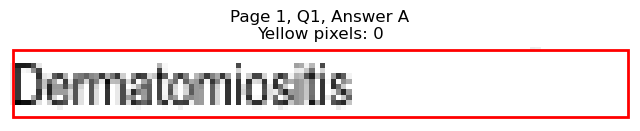

Page 1, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=132.1, y1=114.7
Page 1, Q1, B: Yellow pixels: 1
Page 1, Q1, B: Total non-white pixels: 422
Page 1, Q1, B: Yellow percentage: 0.2%


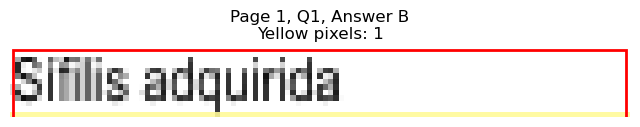

Page 1, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=108.0, y1=127.3
Page 1, Q1, C: Yellow pixels: 934
Page 1, Q1, C: Total non-white pixels: 1274
Page 1, Q1, C: Yellow percentage: 73.3%


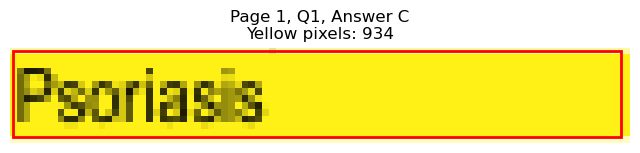

Page 1, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=444.4, y1=102.1
Page 1, Q1, D: Yellow pixels: 0
Page 1, Q1, D: Total non-white pixels: 580
Page 1, Q1, D: Yellow percentage: 0.0%


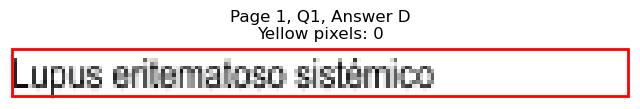

Page 1, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=371.2, y1=114.7
Page 1, Q1, E: Yellow pixels: 0
Page 1, Q1, E: Total non-white pixels: 232
Page 1, Q1, E: Yellow percentage: 0.0%


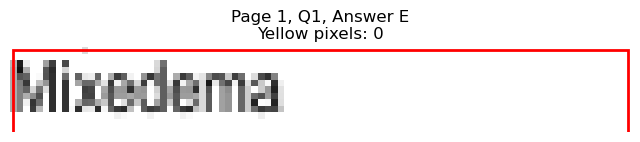


Page 1, Q1 - Selected Answer: C (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=97.3, y1=177.8
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 160
Page 1, Q2, A: Yellow percentage: 0.0%


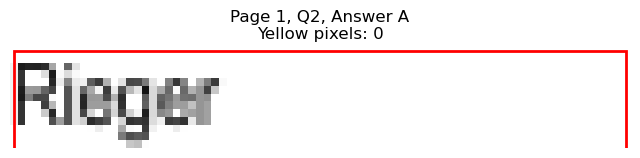

Page 1, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=101.9, y1=190.4
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 177
Page 1, Q2, B: Yellow percentage: 0.0%


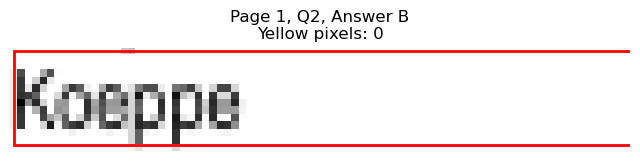

Page 1, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=95.9, y1=203.0
Page 1, Q2, C: Yellow pixels: 0
Page 1, Q2, C: Total non-white pixels: 133
Page 1, Q2, C: Yellow percentage: 0.0%


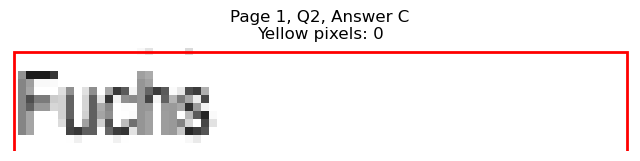

Page 1, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=359.7, y1=177.8
Page 1, Q2, D: Yellow pixels: 0
Page 1, Q2, D: Total non-white pixels: 249
Page 1, Q2, D: Yellow percentage: 0.0%


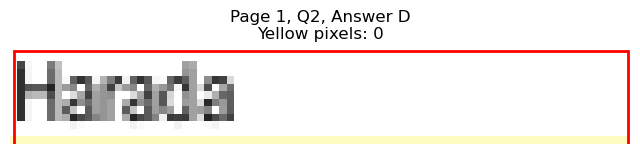

Page 1, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=366.3, y1=190.4
Page 1, Q2, E: Yellow pixels: 926
Page 1, Q2, E: Total non-white pixels: 1260
Page 1, Q2, E: Yellow percentage: 73.5%


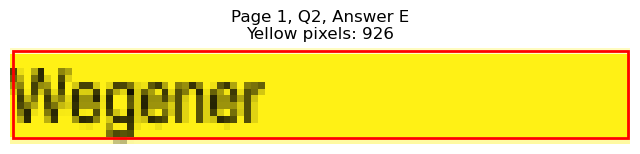


Page 1, Q2 - Selected Answer: E (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=102.9, y1=240.9
Page 1, Q3, A: Yellow pixels: 0
Page 1, Q3, A: Total non-white pixels: 250
Page 1, Q3, A: Yellow percentage: 0.0%


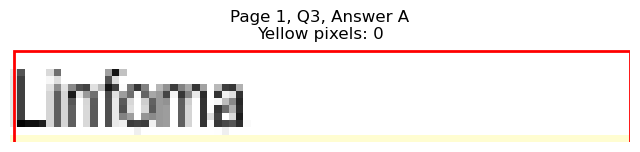

Page 1, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=150.0, y1=253.5
Page 1, Q3, B: Yellow pixels: 1414
Page 1, Q3, B: Total non-white pixels: 1862
Page 1, Q3, B: Yellow percentage: 75.9%


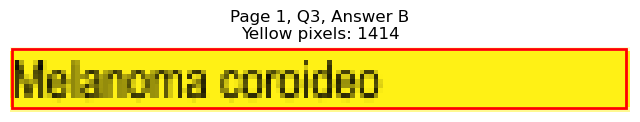

Page 1, Q3 - C: Detected box: x0=68.8, y0=253.5, x1=120.5, y1=266.1
Page 1, Q3, C: Yellow pixels: 103
Page 1, Q3, C: Total non-white pixels: 354
Page 1, Q3, C: Yellow percentage: 29.1%


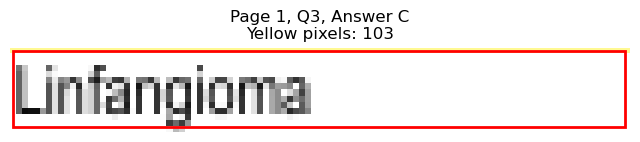

Page 1, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=392.7, y1=240.9
Page 1, Q3, D: Yellow pixels: 0
Page 1, Q3, D: Total non-white pixels: 327
Page 1, Q3, D: Yellow percentage: 0.0%


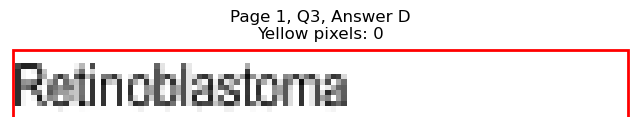

Page 1, Q3 - E: Detected box: x0=327.0, y0=240.9, x1=412.3, y1=253.5
Page 1, Q3, E: Yellow pixels: 0
Page 1, Q3, E: Total non-white pixels: 453
Page 1, Q3, E: Yellow percentage: 0.0%


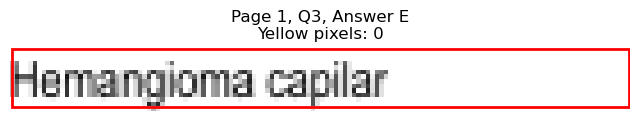


Page 1, Q3 - Selected Answer: B (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=68.3, y0=291.4, x1=140.5, y1=304.1
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 391
Page 1, Q4, A: Yellow percentage: 0.0%


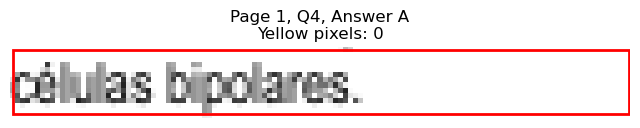

Page 1, Q4 - B: Detected box: x0=68.3, y0=304.0, x1=141.0, y1=316.7
Page 1, Q4, B: Yellow pixels: 0
Page 1, Q4, B: Total non-white pixels: 383
Page 1, Q4, B: Yellow percentage: 0.0%


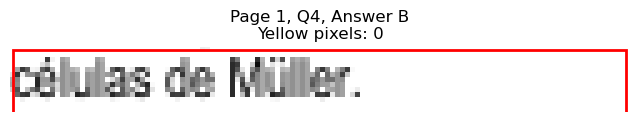

Page 1, Q4 - C: Detected box: x0=68.8, y0=316.6, x1=156.0, y1=329.3
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 410
Page 1, Q4, C: Yellow percentage: 0.0%


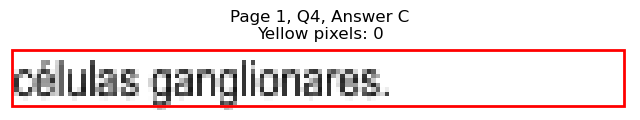

Page 1, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=410.8, y1=304.1
Page 1, Q4, D: Yellow pixels: 134
Page 1, Q4, D: Total non-white pixels: 575
Page 1, Q4, D: Yellow percentage: 23.3%


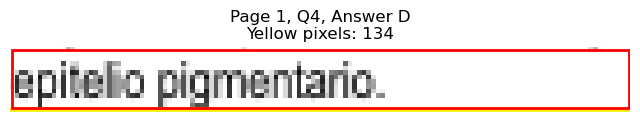

Page 1, Q4 - E: Detected box: x0=327.0, y0=304.0, x1=392.8, y1=316.7
Page 1, Q4, E: Yellow pixels: 1237
Page 1, Q4, E: Total non-white pixels: 1508
Page 1, Q4, E: Yellow percentage: 82.0%


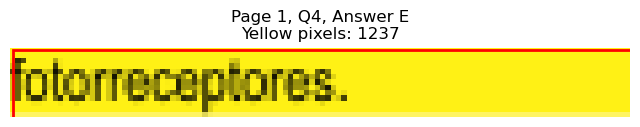


Page 1, Q4 - Selected Answer: E (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=173.7, y1=405.0
Page 1, Q5, A: Yellow pixels: 1636
Page 1, Q5, A: Total non-white pixels: 2028
Page 1, Q5, A: Yellow percentage: 80.7%


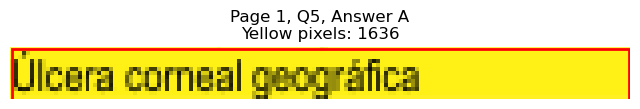

Page 1, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=228.8, y1=417.6
Page 1, Q5, B: Yellow pixels: 203
Page 1, Q5, B: Total non-white pixels: 1015
Page 1, Q5, B: Yellow percentage: 20.0%


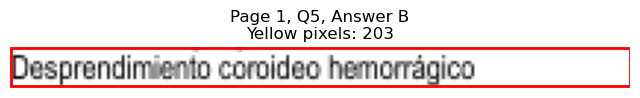

Page 1, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=99.9, y1=430.3
Page 1, Q5, C: Yellow pixels: 0
Page 1, Q5, C: Total non-white pixels: 154
Page 1, Q5, C: Yellow percentage: 0.0%


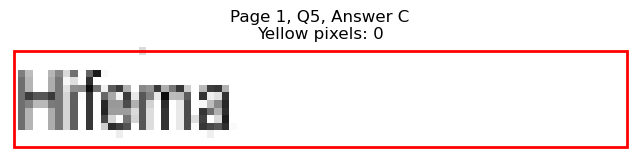

Page 1, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=476.5, y1=405.0
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 729
Page 1, Q5, D: Yellow percentage: 0.0%


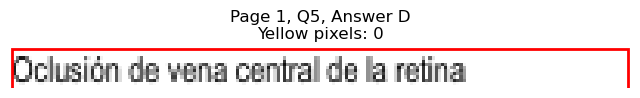

Page 1, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=425.8, y1=417.6
Page 1, Q5, E: Yellow pixels: 0
Page 1, Q5, E: Total non-white pixels: 509
Page 1, Q5, E: Yellow percentage: 0.0%


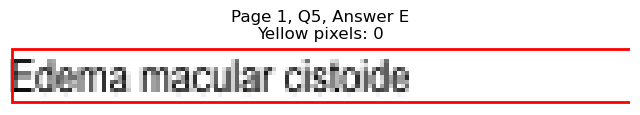


Page 1, Q5 - Selected Answer: A (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=131.5, y1=468.1
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 302
Page 1, Q6, A: Yellow percentage: 0.0%


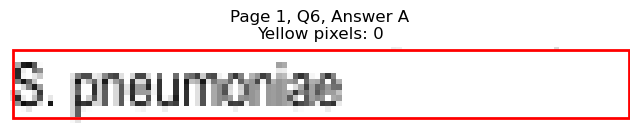

Page 1, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=121.1, y1=480.7
Page 1, Q6, B: Yellow pixels: 0
Page 1, Q6, B: Total non-white pixels: 269
Page 1, Q6, B: Yellow percentage: 0.0%


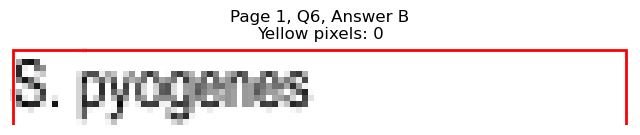

Page 1, Q6 - C: Detected box: x0=68.8, y0=480.8, x1=167.7, y1=493.4
Page 1, Q6, C: Yellow pixels: 1395
Page 1, Q6, C: Total non-white pixels: 2100
Page 1, Q6, C: Yellow percentage: 66.4%


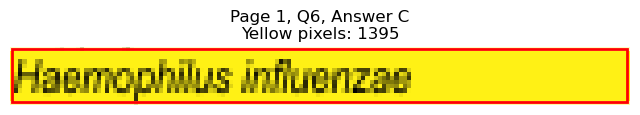

Page 1, Q6 - D: Detected box: x0=327.5, y0=455.5, x1=423.4, y1=468.1
Page 1, Q6, D: Yellow pixels: 0
Page 1, Q6, D: Total non-white pixels: 480
Page 1, Q6, D: Yellow percentage: 0.0%


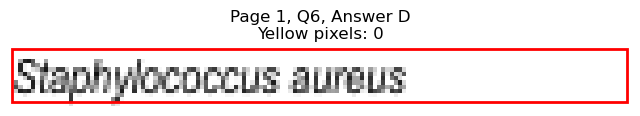

Page 1, Q6 - E: Detected box: x0=327.0, y0=468.1, x1=434.5, y1=480.7
Page 1, Q6, E: Yellow pixels: 0
Page 1, Q6, E: Total non-white pixels: 543
Page 1, Q6, E: Yellow percentage: 0.0%


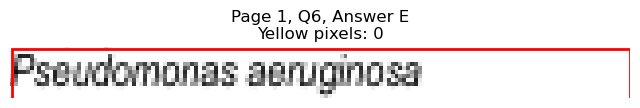


Page 1, Q6 - Selected Answer: C (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=124.0, y1=543.8
Page 1, Q7, A: Yellow pixels: 1165
Page 1, Q7, A: Total non-white pixels: 1378
Page 1, Q7, A: Yellow percentage: 84.5%


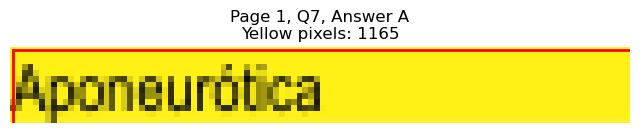

Page 1, Q7 - B: Detected box: x0=68.3, y0=543.9, x1=112.0, y1=556.6
Page 1, Q7, B: Yellow pixels: 92
Page 1, Q7, B: Total non-white pixels: 328
Page 1, Q7, B: Yellow percentage: 28.0%


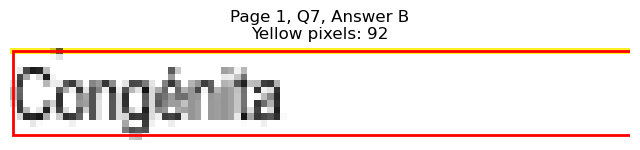

Page 1, Q7 - C: Detected box: x0=68.8, y0=556.5, x1=115.9, y1=569.2
Page 1, Q7, C: Yellow pixels: 0
Page 1, Q7, C: Total non-white pixels: 243
Page 1, Q7, C: Yellow percentage: 0.0%


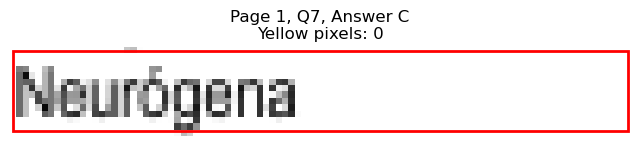

Page 1, Q7 - D: Detected box: x0=327.5, y0=531.2, x1=364.6, y1=543.8
Page 1, Q7, D: Yellow pixels: 0
Page 1, Q7, D: Total non-white pixels: 207
Page 1, Q7, D: Yellow percentage: 0.0%


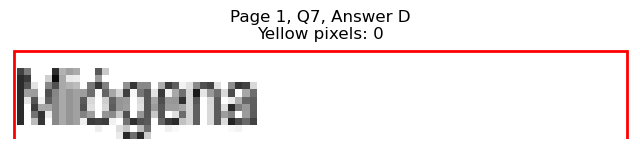

Page 1, Q7 - E: Detected box: x0=327.0, y0=543.9, x1=368.2, y1=556.6
Page 1, Q7, E: Yellow pixels: 0
Page 1, Q7, E: Total non-white pixels: 230
Page 1, Q7, E: Yellow percentage: 0.0%


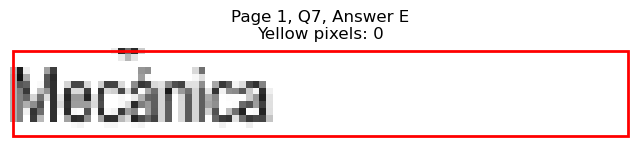


Page 1, Q7 - Selected Answer: A (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=68.3, y0=594.3, x1=79.3, y1=607.0
Page 1, Q8, A: Yellow pixels: 776
Page 1, Q8, A: Total non-white pixels: 806
Page 1, Q8, A: Yellow percentage: 96.3%


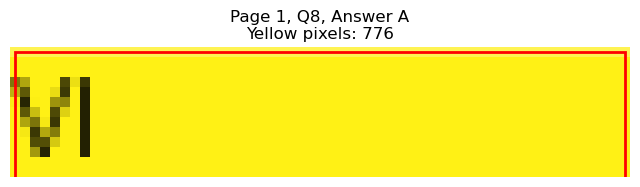

Page 1, Q8 - B: Detected box: x0=68.3, y0=607.0, x1=78.4, y1=619.7
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 93
Page 1, Q8, B: Yellow percentage: 0.0%


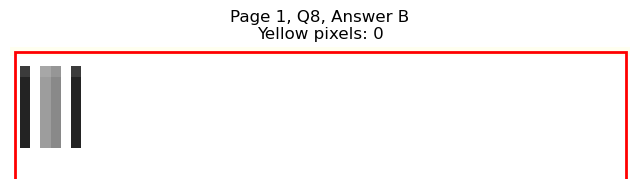

Page 1, Q8 - C: Detected box: x0=68.8, y0=619.6, x1=79.8, y1=632.3
Page 1, Q8, C: Yellow pixels: 0
Page 1, Q8, C: Total non-white pixels: 44
Page 1, Q8, C: Yellow percentage: 0.0%


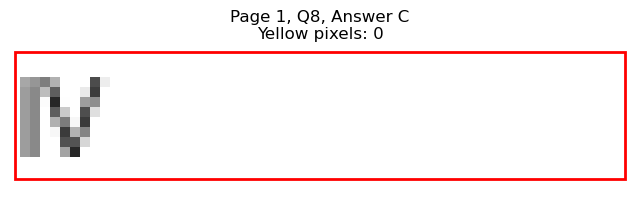

Page 1, Q8 - D: Detected box: x0=315.4, y0=594.3, x1=324.4, y1=607.0
Page 1, Q8, D: Yellow pixels: 0
Page 1, Q8, D: Total non-white pixels: 69
Page 1, Q8, D: Yellow percentage: 0.0%


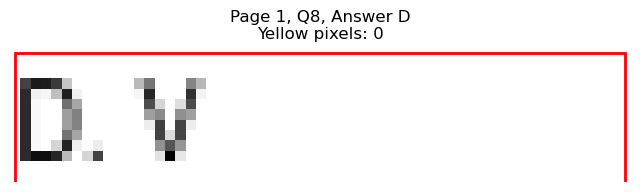

Page 1, Q8 - E: Detected box: x0=327.0, y0=607.0, x1=340.6, y1=619.7
Page 1, Q8, E: Yellow pixels: 0
Page 1, Q8, E: Total non-white pixels: 58
Page 1, Q8, E: Yellow percentage: 0.0%


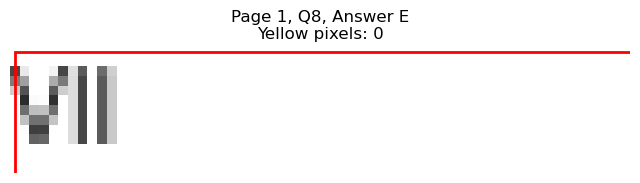


Page 1, Q8 - Selected Answer: A (based on yellow pixel count)




Page 1, Q9 - A: Detected box: x0=68.3, y0=670.1, x1=124.9, y1=682.7
Page 1, Q9, A: Yellow pixels: 1186
Page 1, Q9, A: Total non-white pixels: 1391
Page 1, Q9, A: Yellow percentage: 85.3%


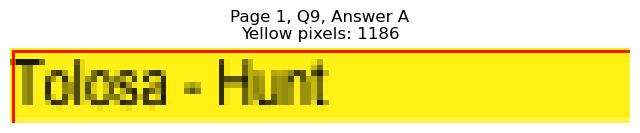

Page 1, Q9 - B: Detected box: x0=68.3, y0=682.8, x1=132.0, y1=695.4
Page 1, Q9, B: Yellow pixels: 115
Page 1, Q9, B: Total non-white pixels: 419
Page 1, Q9, B: Yellow percentage: 27.4%


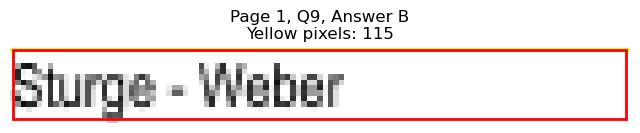

Page 1, Q9 - C: Detected box: x0=68.8, y0=695.4, x1=157.1, y1=708.0
Page 1, Q9, C: Yellow pixels: 0
Page 1, Q9, C: Total non-white pixels: 410
Page 1, Q9, C: Yellow percentage: 0.0%


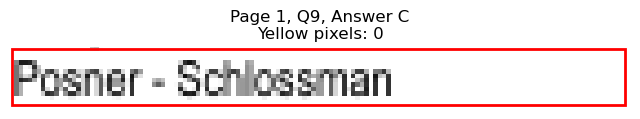

Page 1, Q9 - D: Detected box: x0=327.5, y0=670.1, x1=402.8, y1=682.7
Page 1, Q9, D: Yellow pixels: 0
Page 1, Q9, D: Total non-white pixels: 341
Page 1, Q9, D: Yellow percentage: 0.0%


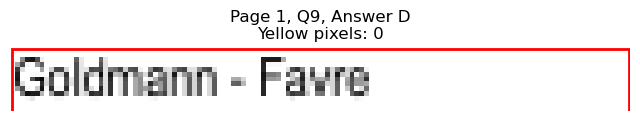

Page 1, Q9 - E: Detected box: x0=327.0, y0=682.8, x1=389.7, y1=695.4
Page 1, Q9, E: Yellow pixels: 0
Page 1, Q9, E: Total non-white pixels: 290
Page 1, Q9, E: Yellow percentage: 0.0%


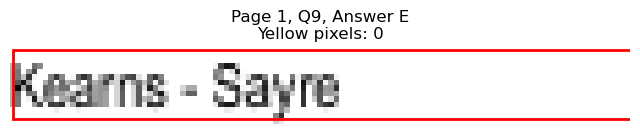


Page 1, Q9 - Selected Answer: A (based on yellow pixel count)




Page 1, Q10 - A: Detected box: x0=68.3, y0=733.2, x1=105.9, y1=745.8
Page 1, Q10, A: Yellow pixels: 0
Page 1, Q10, A: Total non-white pixels: 172
Page 1, Q10, A: Yellow percentage: 0.0%


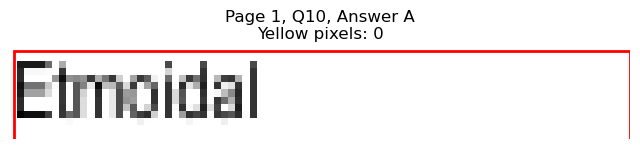

Page 1, Q10 - B: Detected box: x0=68.3, y0=745.9, x1=99.0, y1=758.6
Page 1, Q10, B: Yellow pixels: 0
Page 1, Q10, B: Total non-white pixels: 136
Page 1, Q10, B: Yellow percentage: 0.0%


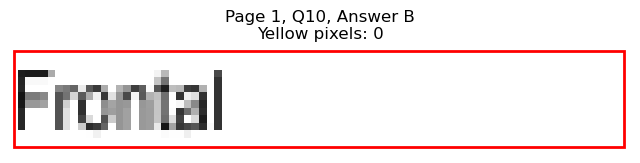

Page 1, Q10 - C: Detected box: x0=68.8, y0=758.5, x1=125.5, y1=771.2
Page 1, Q10, C: Yellow pixels: 0
Page 1, Q10, C: Total non-white pixels: 305
Page 1, Q10, C: Yellow percentage: 0.0%


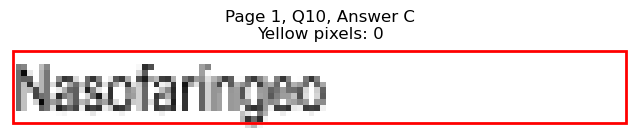

Page 1, Q10 - D: Detected box: x0=327.5, y0=733.2, x1=359.2, y1=745.8
Page 1, Q10, D: Yellow pixels: 952
Page 1, Q10, D: Total non-white pixels: 1079
Page 1, Q10, D: Yellow percentage: 88.2%


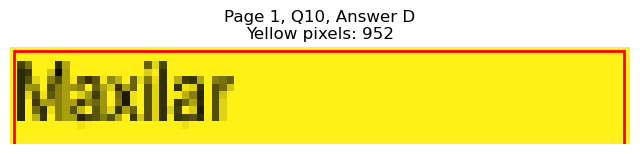

Page 1, Q10 - E: Detected box: x0=327.0, y0=745.9, x1=376.7, y1=758.6
Page 1, Q10, E: Yellow pixels: 100
Page 1, Q10, E: Total non-white pixels: 346
Page 1, Q10, E: Yellow percentage: 28.9%


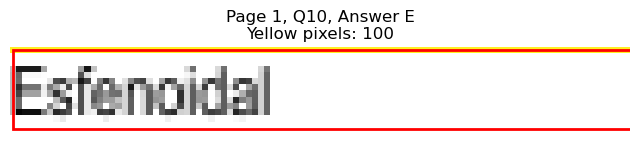


Page 1, Q10 - Selected Answer: D (based on yellow pixel count)





Page 2: Found 8 questions
Page 2, Q1 - A: Detected box: x0=68.3, y0=127.2, x1=255.4, y1=139.9
Page 2, Q1, A: Yellow pixels: 2102
Page 2, Q1, A: Total non-white pixels: 2782
Page 2, Q1, A: Yellow percentage: 75.6%


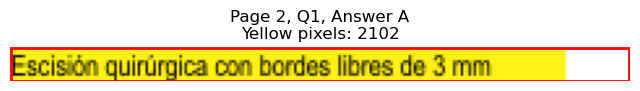

Page 2, Q1 - B: Detected box: x0=68.3, y0=139.9, x1=186.6, y1=152.6
Page 2, Q1, B: Yellow pixels: 164
Page 2, Q1, B: Total non-white pixels: 747
Page 2, Q1, B: Yellow percentage: 22.0%


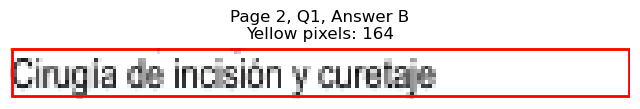

Page 2, Q1 - C: Detected box: x0=68.8, y0=152.5, x1=228.8, y1=165.2
Page 2, Q1, C: Yellow pixels: 0
Page 2, Q1, C: Total non-white pixels: 793
Page 2, Q1, C: Yellow percentage: 0.0%


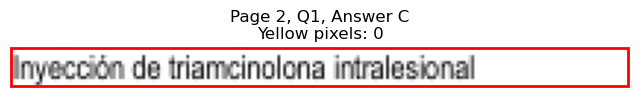

Page 2, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=513.1, y1=139.9
Page 2, Q1, D: Yellow pixels: 0
Page 2, Q1, D: Total non-white pixels: 885
Page 2, Q1, D: Yellow percentage: 0.0%


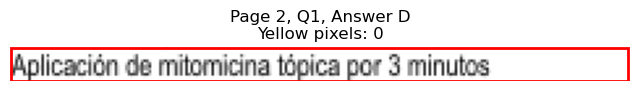

Page 2, Q1 - E: Detected box: x0=327.0, y0=139.9, x1=395.8, y1=152.6
Page 2, Q1, E: Yellow pixels: 0
Page 2, Q1, E: Total non-white pixels: 567
Page 2, Q1, E: Yellow percentage: 0.0%


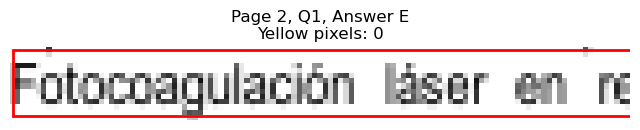


Page 2, Q1 - Selected Answer: A (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=94.3, y1=215.6
Page 2, Q2, A: Yellow pixels: 906
Page 2, Q2, A: Total non-white pixels: 1078
Page 2, Q2, A: Yellow percentage: 84.0%


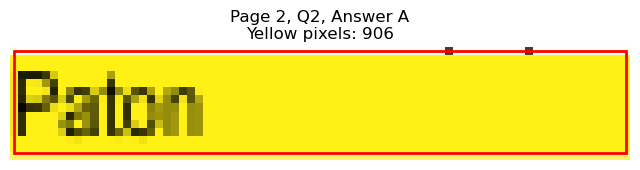

Page 2, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=96.9, y1=228.3
Page 2, Q2, B: Yellow pixels: 79
Page 2, Q2, B: Total non-white pixels: 228
Page 2, Q2, B: Yellow percentage: 34.6%


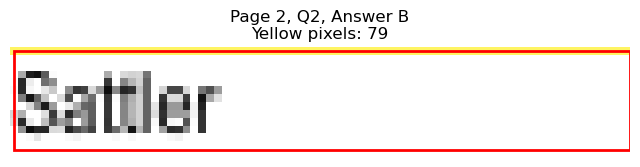

Page 2, Q2 - C: Detected box: x0=68.8, y0=228.3, x1=101.4, y1=240.9
Page 2, Q2, C: Yellow pixels: 0
Page 2, Q2, C: Total non-white pixels: 157
Page 2, Q2, C: Yellow percentage: 0.0%


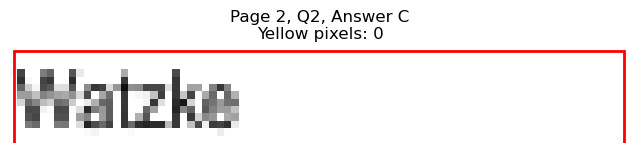

Page 2, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=351.7, y1=215.6
Page 2, Q2, D: Yellow pixels: 0
Page 2, Q2, D: Total non-white pixels: 100
Page 2, Q2, D: Yellow percentage: 0.0%


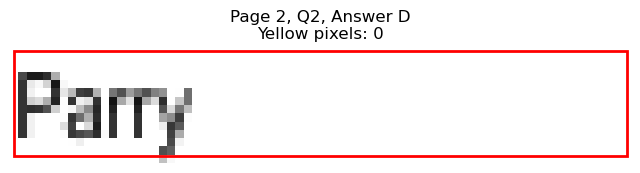

Page 2, Q2 - E: Detected box: x0=327.0, y0=215.7, x1=357.7, y1=228.3
Page 2, Q2, E: Yellow pixels: 0
Page 2, Q2, E: Total non-white pixels: 150
Page 2, Q2, E: Yellow percentage: 0.0%


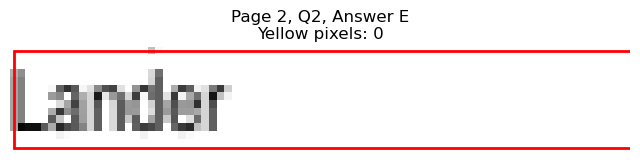


Page 2, Q2 - Selected Answer: A (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=92.4, y1=278.7
Page 2, Q3, A: Yellow pixels: 0
Page 2, Q3, A: Total non-white pixels: 127
Page 2, Q3, A: Yellow percentage: 0.0%


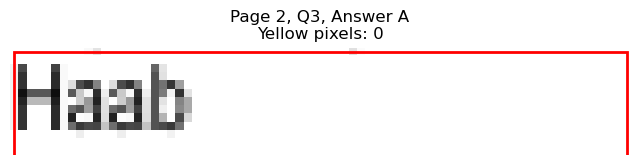

Page 2, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=95.4, y1=291.5
Page 2, Q3, B: Yellow pixels: 0
Page 2, Q3, B: Total non-white pixels: 112
Page 2, Q3, B: Yellow percentage: 0.0%


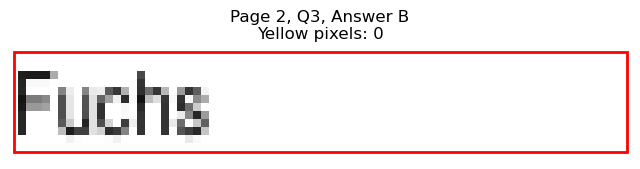

Page 2, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=115.0, y1=304.1
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 217
Page 2, Q3, C: Yellow percentage: 0.0%


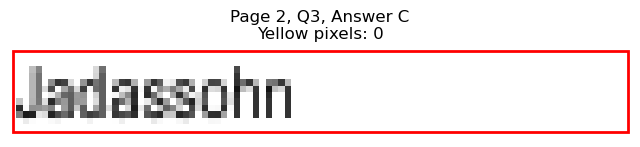

Page 2, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=360.7, y1=278.7
Page 2, Q3, D: Yellow pixels: 961
Page 2, Q3, D: Total non-white pixels: 1092
Page 2, Q3, D: Yellow percentage: 88.0%


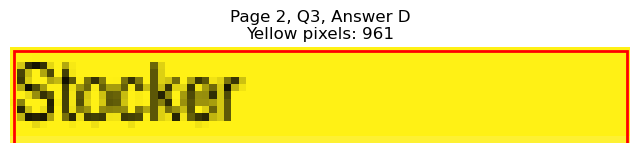

Page 2, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=347.2, y1=291.5
Page 2, Q3, E: Yellow pixels: 71
Page 2, Q3, E: Total non-white pixels: 177
Page 2, Q3, E: Yellow percentage: 40.1%


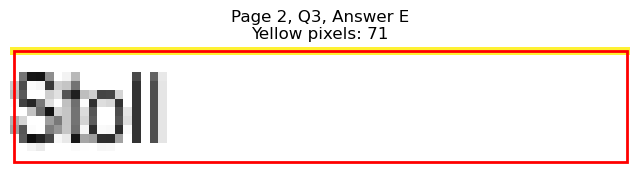


Page 2, Q3 - Selected Answer: D (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=140.1, y1=341.9
Page 2, Q4, A: Yellow pixels: 0
Page 2, Q4, A: Total non-white pixels: 366
Page 2, Q4, A: Yellow percentage: 0.0%


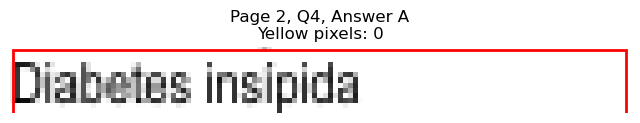

Page 2, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=136.0, y1=354.6
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 338
Page 2, Q4, B: Yellow percentage: 0.0%


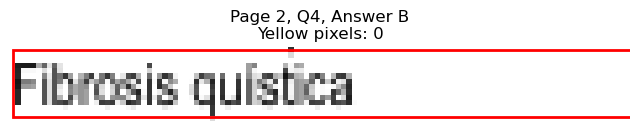

Page 2, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=139.0, y1=367.2
Page 2, Q4, C: Yellow pixels: 0
Page 2, Q4, C: Total non-white pixels: 363
Page 2, Q4, C: Yellow percentage: 0.0%


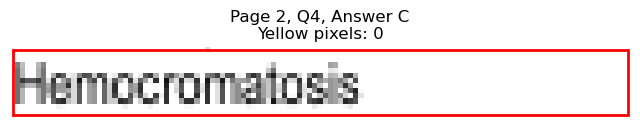

Page 2, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=409.7, y1=341.9
Page 2, Q4, D: Yellow pixels: 0
Page 2, Q4, D: Total non-white pixels: 441
Page 2, Q4, D: Yellow percentage: 0.0%


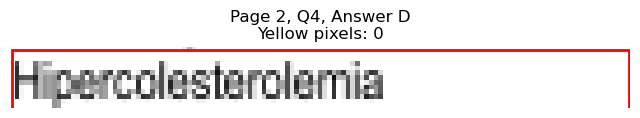

Page 2, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=384.8, y1=354.6
Page 2, Q4, E: Yellow pixels: 1159
Page 2, Q4, E: Total non-white pixels: 1512
Page 2, Q4, E: Yellow percentage: 76.7%


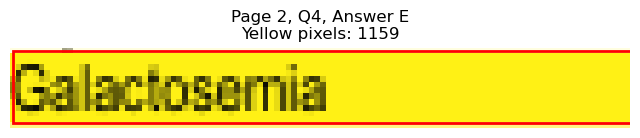


Page 2, Q4 - Selected Answer: E (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=153.0, y1=430.3
Page 2, Q5, A: Yellow pixels: 136
Page 2, Q5, A: Total non-white pixels: 562
Page 2, Q5, A: Yellow percentage: 24.2%


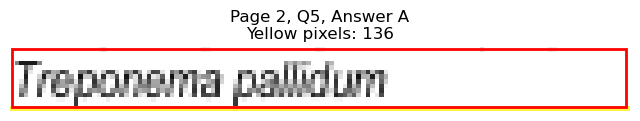

Page 2, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=150.5, y1=442.9
Page 2, Q5, B: Yellow pixels: 1391
Page 2, Q5, B: Total non-white pixels: 1729
Page 2, Q5, B: Yellow percentage: 80.5%


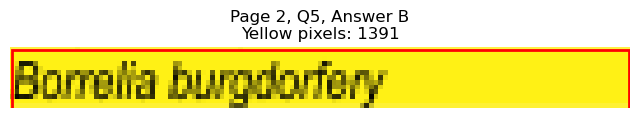

Page 2, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=169.6, y1=455.5
Page 2, Q5, C: Yellow pixels: 145
Page 2, Q5, C: Total non-white pixels: 677
Page 2, Q5, C: Yellow percentage: 21.4%


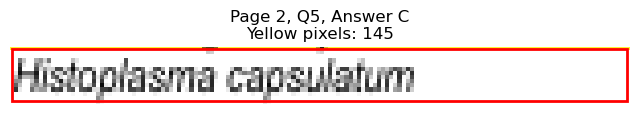

Page 2, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=434.8, y1=430.3
Page 2, Q5, D: Yellow pixels: 0
Page 2, Q5, D: Total non-white pixels: 539
Page 2, Q5, D: Yellow percentage: 0.0%


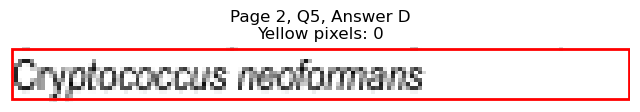

Page 2, Q5 - E: Detected box: x0=327.0, y0=430.2, x1=398.8, y1=442.9
Page 2, Q5, E: Yellow pixels: 0
Page 2, Q5, E: Total non-white pixels: 366
Page 2, Q5, E: Yellow percentage: 0.0%


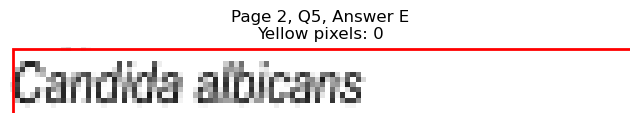


Page 2, Q5 - Selected Answer: B (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=68.3, y0=518.6, x1=219.9, y1=531.2
Page 2, Q6, A: Yellow pixels: 0
Page 2, Q6, A: Total non-white pixels: 754
Page 2, Q6, A: Yellow percentage: 0.0%


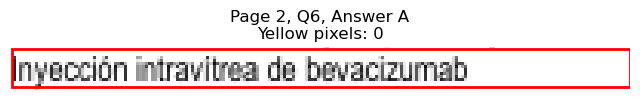

Page 2, Q6 - B: Detected box: x0=68.3, y0=531.2, x1=150.0, y1=543.8
Page 2, Q6, B: Yellow pixels: 0
Page 2, Q6, B: Total non-white pixels: 407
Page 2, Q6, B: Yellow percentage: 0.0%


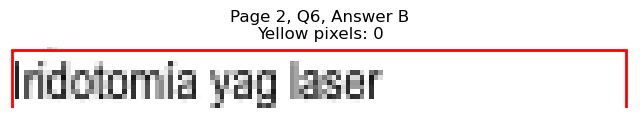

Page 2, Q6 - C: Detected box: x0=68.8, y0=543.8, x1=150.5, y1=556.4
Page 2, Q6, C: Yellow pixels: 0
Page 2, Q6, C: Total non-white pixels: 436
Page 2, Q6, C: Yellow percentage: 0.0%


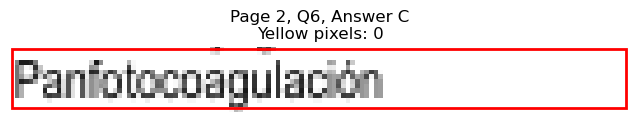

Page 2, Q6 - D: Detected box: x0=327.5, y0=518.6, x1=386.2, y1=531.2
Page 2, Q6, D: Yellow pixels: 1202
Page 2, Q6, D: Total non-white pixels: 1540
Page 2, Q6, D: Yellow percentage: 78.1%


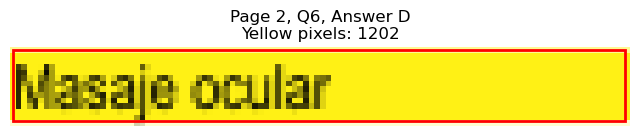

Page 2, Q6 - E: Detected box: x0=327.0, y0=531.2, x1=381.7, y1=543.8
Page 2, Q6, E: Yellow pixels: 0
Page 2, Q6, E: Total non-white pixels: 392
Page 2, Q6, E: Yellow percentage: 0.0%


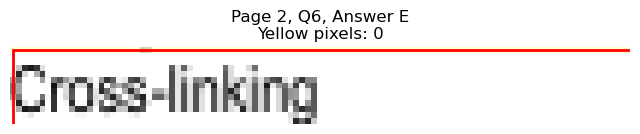


Page 2, Q6 - Selected Answer: D (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=68.3, y0=581.7, x1=103.9, y1=594.4
Page 2, Q7, A: Yellow pixels: 86
Page 2, Q7, A: Total non-white pixels: 290
Page 2, Q7, A: Yellow percentage: 29.7%


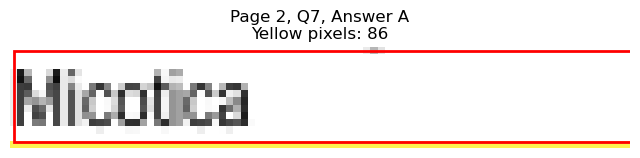

Page 2, Q7 - B: Detected box: x0=68.3, y0=594.3, x1=96.9, y1=607.0
Page 2, Q7, B: Yellow pixels: 922
Page 2, Q7, B: Total non-white pixels: 1027
Page 2, Q7, B: Yellow percentage: 89.8%


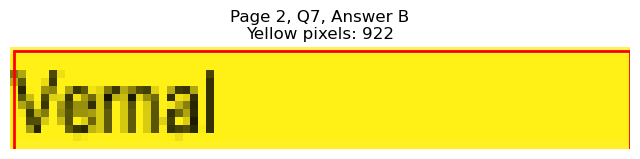

Page 2, Q7 - C: Detected box: x0=68.8, y0=606.9, x1=109.9, y1=619.6
Page 2, Q7, C: Yellow pixels: 92
Page 2, Q7, C: Total non-white pixels: 317
Page 2, Q7, C: Yellow percentage: 29.0%


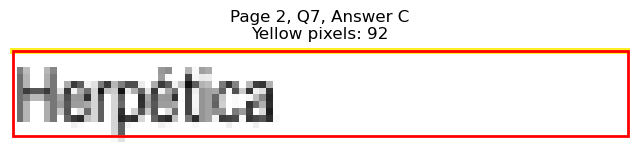

Page 2, Q7 - D: Detected box: x0=327.5, y0=581.7, x1=350.6, y1=594.4
Page 2, Q7, D: Yellow pixels: 0
Page 2, Q7, D: Total non-white pixels: 115
Page 2, Q7, D: Yellow percentage: 0.0%


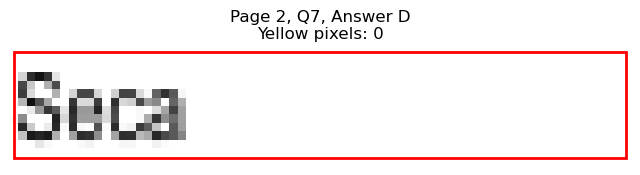

Page 2, Q7 - E: Detected box: x0=327.0, y0=594.3, x1=371.7, y1=607.0
Page 2, Q7, E: Yellow pixels: 0
Page 2, Q7, E: Total non-white pixels: 248
Page 2, Q7, E: Yellow percentage: 0.0%


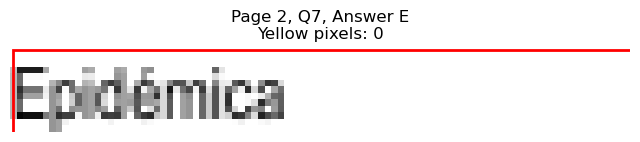


Page 2, Q7 - Selected Answer: B (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=68.3, y0=657.5, x1=117.5, y1=670.1
Page 2, Q8, A: Yellow pixels: 100
Page 2, Q8, A: Total non-white pixels: 361
Page 2, Q8, A: Yellow percentage: 27.7%


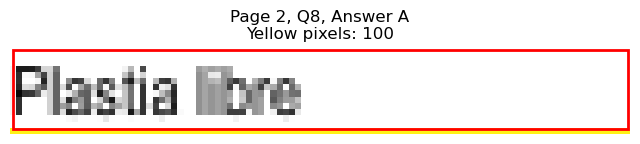

Page 2, Q8 - B: Detected box: x0=68.3, y0=670.1, x1=158.1, y1=682.7
Page 2, Q8, B: Yellow pixels: 1509
Page 2, Q8, B: Total non-white pixels: 1833
Page 2, Q8, B: Yellow percentage: 82.3%


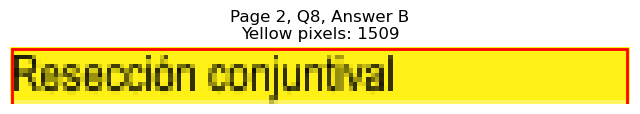

Page 2, Q8 - C: Detected box: x0=68.8, y0=682.7, x1=141.0, y1=695.3
Page 2, Q8, C: Yellow pixels: 123
Page 2, Q8, C: Total non-white pixels: 510
Page 2, Q8, C: Yellow percentage: 24.1%


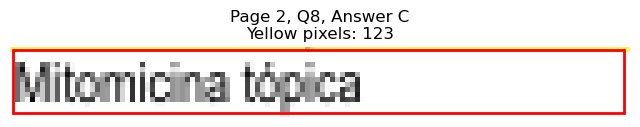

Page 2, Q8 - D: Detected box: x0=327.5, y0=657.5, x1=382.3, y1=670.1
Page 2, Q8, D: Yellow pixels: 0
Page 2, Q8, D: Total non-white pixels: 282
Page 2, Q8, D: Yellow percentage: 0.0%


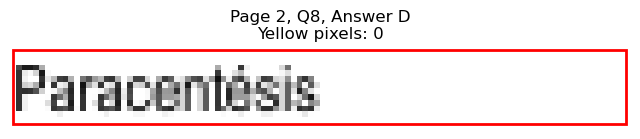

Page 2, Q8 - E: Detected box: x0=327.0, y0=670.1, x1=412.9, y1=682.7
Page 2, Q8, E: Yellow pixels: 0
Page 2, Q8, E: Total non-white pixels: 427
Page 2, Q8, E: Yellow percentage: 0.0%


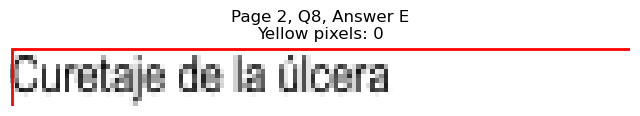


Page 2, Q8 - Selected Answer: B (based on yellow pixel count)





Page 3: Found 8 questions
Page 3, Q1 - A: Detected box: x0=68.3, y0=114.6, x1=136.0, y1=127.3
Page 3, Q1, A: Yellow pixels: 0
Page 3, Q1, A: Total non-white pixels: 368
Page 3, Q1, A: Yellow percentage: 0.0%


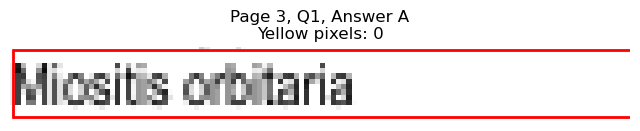

Page 3, Q1 - B: Detected box: x0=68.3, y0=127.2, x1=185.8, y1=139.9
Page 3, Q1, B: Yellow pixels: 0
Page 3, Q1, B: Total non-white pixels: 594
Page 3, Q1, B: Yellow percentage: 0.0%


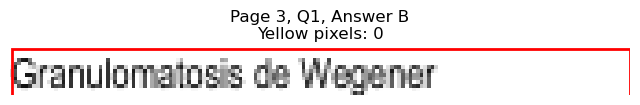

Page 3, Q1 - C: Detected box: x0=68.8, y0=139.9, x1=118.0, y1=152.6
Page 3, Q1, C: Yellow pixels: 0
Page 3, Q1, C: Total non-white pixels: 259
Page 3, Q1, C: Yellow percentage: 0.0%


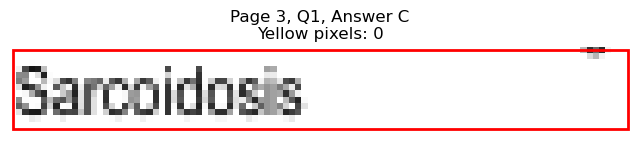

Page 3, Q1 - D: Detected box: x0=327.5, y0=114.6, x1=362.2, y1=127.3
Page 3, Q1, D: Yellow pixels: 86
Page 3, Q1, D: Total non-white pixels: 234
Page 3, Q1, D: Yellow percentage: 36.8%


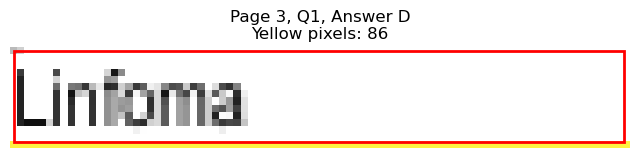

Page 3, Q1 - E: Detected box: x0=327.0, y0=127.2, x1=413.9, y1=139.9
Page 3, Q1, E: Yellow pixels: 1428
Page 3, Q1, E: Total non-white pixels: 1781
Page 3, Q1, E: Yellow percentage: 80.2%


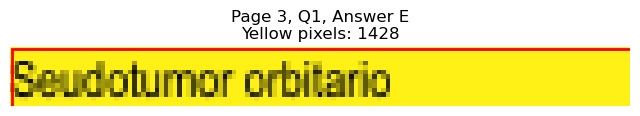


Page 3, Q1 - Selected Answer: E (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=124.9, y1=190.4
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 276
Page 3, Q2, A: Yellow percentage: 0.0%


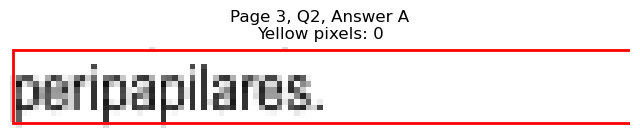

Page 3, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=154.1, y1=203.0
Page 3, Q2, B: Yellow pixels: 0
Page 3, Q2, B: Total non-white pixels: 386
Page 3, Q2, B: Yellow percentage: 0.0%


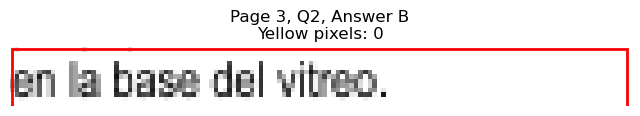

Page 3, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=144.5, y1=215.6
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 364
Page 3, Q2, C: Yellow percentage: 0.0%


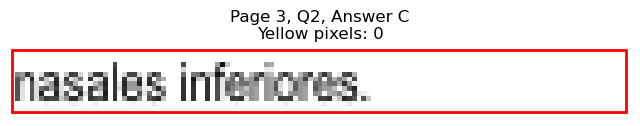

Page 3, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=374.2, y1=190.4
Page 3, Q2, D: Yellow pixels: 98
Page 3, Q2, D: Total non-white pixels: 321
Page 3, Q2, D: Yellow percentage: 30.5%


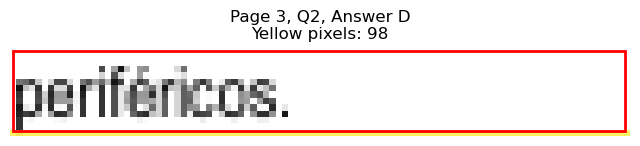

Page 3, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=380.7, y1=203.0
Page 3, Q2, E: Yellow pixels: 1127
Page 3, Q2, E: Total non-white pixels: 1352
Page 3, Q2, E: Yellow percentage: 83.4%


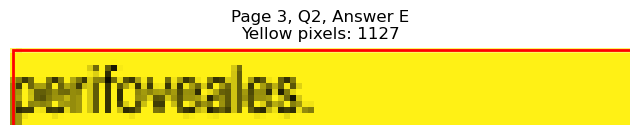


Page 3, Q2 - Selected Answer: E (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=133.5, y1=253.5
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 319
Page 3, Q3, A: Yellow percentage: 0.0%


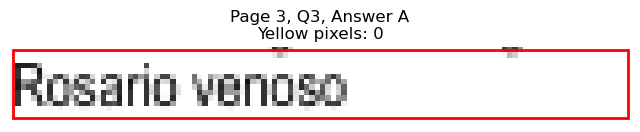

Page 3, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=99.4, y1=266.1
Page 3, Q3, B: Yellow pixels: 0
Page 3, Q3, B: Total non-white pixels: 156
Page 3, Q3, B: Yellow percentage: 0.0%


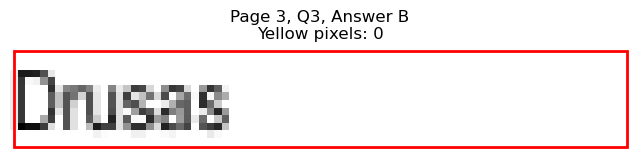

Page 3, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=166.1, y1=278.7
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 456
Page 3, Q3, C: Yellow percentage: 0.0%


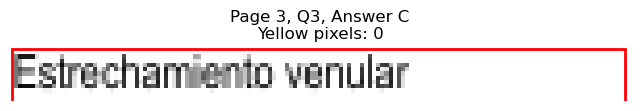

Page 3, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=397.3, y1=253.5
Page 3, Q3, D: Yellow pixels: 121
Page 3, Q3, D: Total non-white pixels: 459
Page 3, Q3, D: Yellow percentage: 26.4%


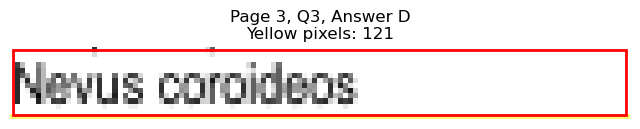

Page 3, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=398.2, y1=266.1
Page 3, Q3, E: Yellow pixels: 1291
Page 3, Q3, E: Total non-white pixels: 1708
Page 3, Q3, E: Yellow percentage: 75.6%


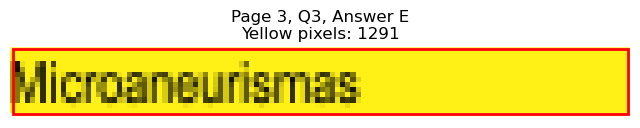


Page 3, Q3 - Selected Answer: E (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=68.3, y0=341.9, x1=155.7, y1=354.6
Page 3, Q4, A: Yellow pixels: 0
Page 3, Q4, A: Total non-white pixels: 463
Page 3, Q4, A: Yellow percentage: 0.0%


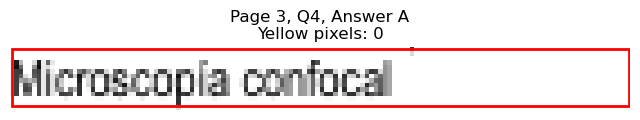

Page 3, Q4 - B: Detected box: x0=68.3, y0=354.5, x1=179.8, y1=367.2
Page 3, Q4, B: Yellow pixels: 0
Page 3, Q4, B: Total non-white pixels: 540
Page 3, Q4, B: Yellow percentage: 0.0%


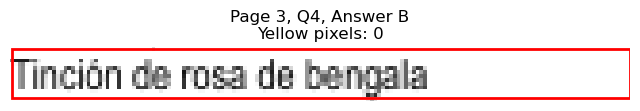

Page 3, Q4 - C: Detected box: x0=68.8, y0=367.1, x1=201.8, y1=379.8
Page 3, Q4, C: Yellow pixels: 0
Page 3, Q4, C: Total non-white pixels: 650
Page 3, Q4, C: Yellow percentage: 0.0%


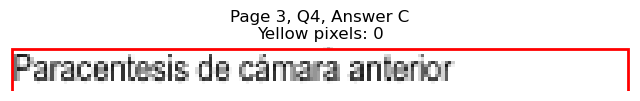

Page 3, Q4 - D: Detected box: x0=327.5, y0=341.9, x1=453.4, y1=354.6
Page 3, Q4, D: Yellow pixels: 177
Page 3, Q4, D: Total non-white pixels: 832
Page 3, Q4, D: Yellow percentage: 21.3%


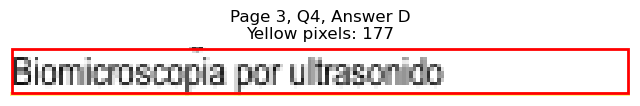

Page 3, Q4 - E: Detected box: x0=327.0, y0=354.5, x1=480.6, y1=367.2
Page 3, Q4, E: Yellow pixels: 2076
Page 3, Q4, E: Total non-white pixels: 2856
Page 3, Q4, E: Yellow percentage: 72.7%


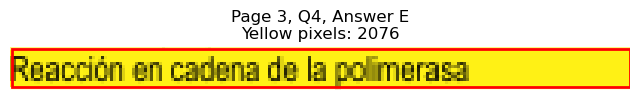


Page 3, Q4 - Selected Answer: E (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=68.3, y0=442.8, x1=158.5, y1=455.5
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 444
Page 3, Q5, A: Yellow percentage: 0.0%


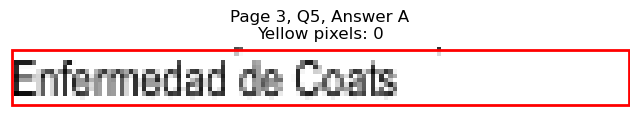

Page 3, Q5 - B: Detected box: x0=68.3, y0=455.5, x1=155.5, y1=468.1
Page 3, Q5, B: Yellow pixels: 138
Page 3, Q5, B: Total non-white pixels: 615
Page 3, Q5, B: Yellow percentage: 22.4%


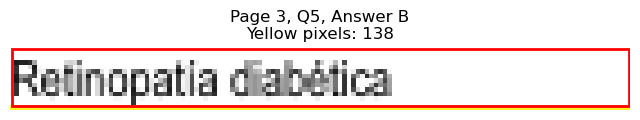

Page 3, Q5 - C: Detected box: x0=68.8, y0=468.1, x1=158.1, y1=480.7
Page 3, Q5, C: Yellow pixels: 1454
Page 3, Q5, C: Total non-white pixels: 1833
Page 3, Q5, C: Yellow percentage: 79.3%


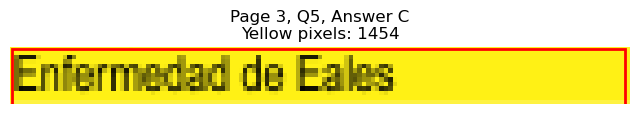

Page 3, Q5 - D: Detected box: x0=327.5, y0=442.8, x1=419.3, y1=455.5
Page 3, Q5, D: Yellow pixels: 0
Page 3, Q5, D: Total non-white pixels: 489
Page 3, Q5, D: Yellow percentage: 0.0%


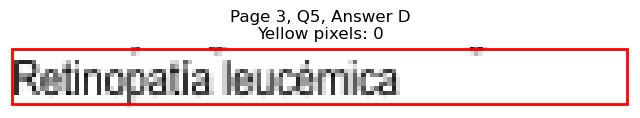

Page 3, Q5 - E: Detected box: x0=327.0, y0=455.5, x1=421.4, y1=468.1
Page 3, Q5, E: Yellow pixels: 0
Page 3, Q5, E: Total non-white pixels: 489
Page 3, Q5, E: Yellow percentage: 0.0%


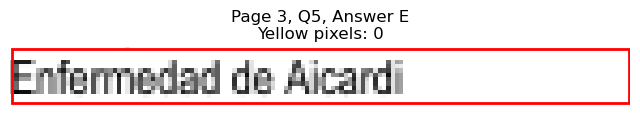


Page 3, Q5 - Selected Answer: C (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=68.3, y0=518.6, x1=170.5, y1=531.2
Page 3, Q6, A: Yellow pixels: 0
Page 3, Q6, A: Total non-white pixels: 507
Page 3, Q6, A: Yellow percentage: 0.0%


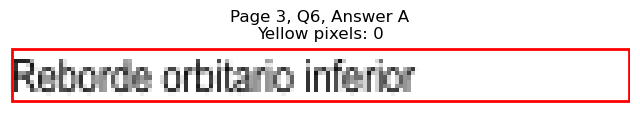

Page 3, Q6 - B: Detected box: x0=68.3, y0=531.2, x1=171.1, y1=543.8
Page 3, Q6, B: Yellow pixels: 0
Page 3, Q6, B: Total non-white pixels: 505
Page 3, Q6, B: Yellow percentage: 0.0%


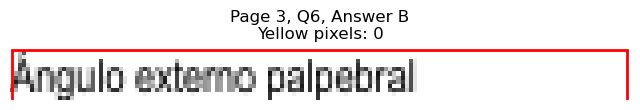

Page 3, Q6 - C: Detected box: x0=68.8, y0=543.8, x1=145.6, y1=556.4
Page 3, Q6, C: Yellow pixels: 0
Page 3, Q6, C: Total non-white pixels: 412
Page 3, Q6, C: Yellow percentage: 0.0%


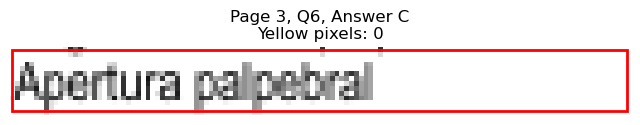

Page 3, Q6 - D: Detected box: x0=327.5, y0=518.6, x1=386.8, y1=531.2
Page 3, Q6, D: Yellow pixels: 110
Page 3, Q6, D: Total non-white pixels: 375
Page 3, Q6, D: Yellow percentage: 29.3%


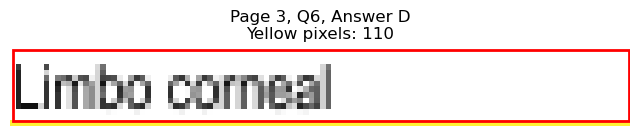

Page 3, Q6 - E: Detected box: x0=327.0, y0=531.2, x1=389.7, y1=543.8
Page 3, Q6, E: Yellow pixels: 1215
Page 3, Q6, E: Total non-white pixels: 1469
Page 3, Q6, E: Yellow percentage: 82.7%


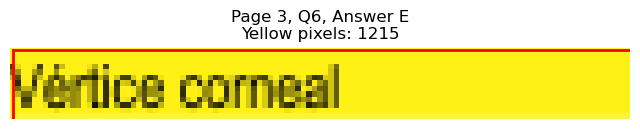


Page 3, Q6 - Selected Answer: E (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=68.3, y0=619.6, x1=157.6, y1=632.3
Page 3, Q7, A: Yellow pixels: 140
Page 3, Q7, A: Total non-white pixels: 576
Page 3, Q7, A: Yellow percentage: 24.3%


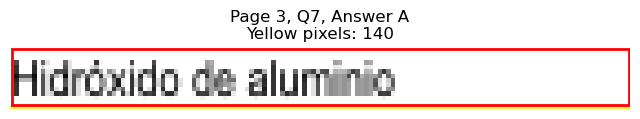

Page 3, Q7 - B: Detected box: x0=68.3, y0=632.2, x1=132.5, y1=644.9
Page 3, Q7, B: Yellow pixels: 1273
Page 3, Q7, B: Total non-white pixels: 1495
Page 3, Q7, B: Yellow percentage: 85.2%


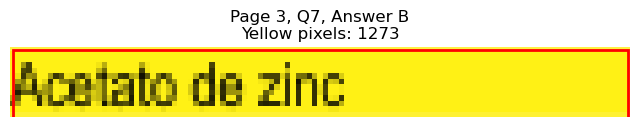

Page 3, Q7 - C: Detected box: x0=68.8, y0=644.9, x1=142.0, y1=657.5
Page 3, Q7, C: Yellow pixels: 0
Page 3, Q7, C: Total non-white pixels: 398
Page 3, Q7, C: Yellow percentage: 0.0%


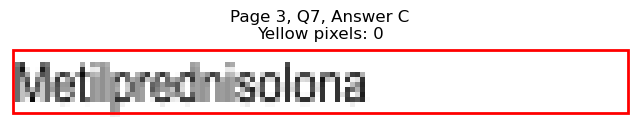

Page 3, Q7 - D: Detected box: x0=327.5, y0=619.6, x1=375.7, y1=632.3
Page 3, Q7, D: Yellow pixels: 0
Page 3, Q7, D: Total non-white pixels: 247
Page 3, Q7, D: Yellow percentage: 0.0%


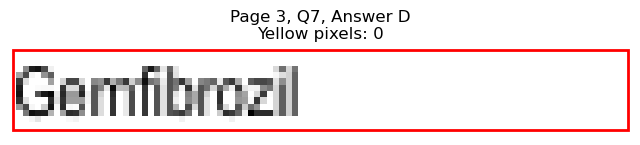

Page 3, Q7 - E: Detected box: x0=327.0, y0=632.2, x1=388.7, y1=644.9
Page 3, Q7, E: Yellow pixels: 0
Page 3, Q7, E: Total non-white pixels: 315
Page 3, Q7, E: Yellow percentage: 0.0%


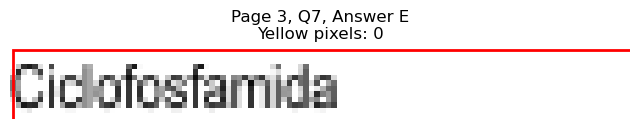


Page 3, Q7 - Selected Answer: B (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=56.6, y0=682.7, x1=65.2, y1=695.3
Page 3, Q8, A: Yellow pixels: 0
Page 3, Q8, A: Total non-white pixels: 71
Page 3, Q8, A: Yellow percentage: 0.0%


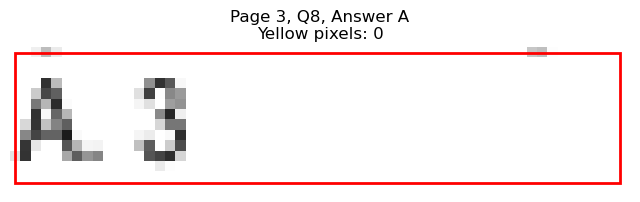

Page 3, Q8 - B: Detected box: x0=56.6, y0=695.4, x1=65.2, y1=708.0
Page 3, Q8, B: Yellow pixels: 0
Page 3, Q8, B: Total non-white pixels: 66
Page 3, Q8, B: Yellow percentage: 0.0%


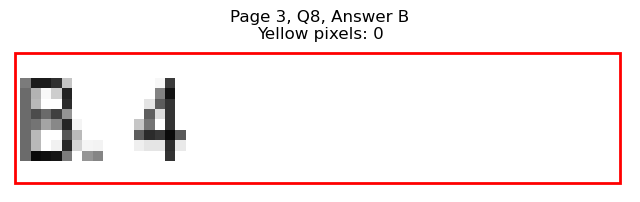

Page 3, Q8 - C: Detected box: x0=56.6, y0=708.0, x1=65.6, y1=720.6
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 56
Page 3, Q8, C: Yellow percentage: 0.0%


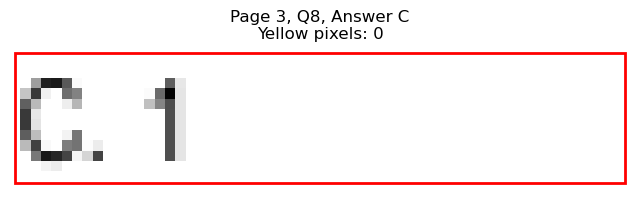

Page 3, Q8 - D: Detected box: x0=315.4, y0=682.7, x1=324.4, y1=695.3
Page 3, Q8, D: Yellow pixels: 0
Page 3, Q8, D: Total non-white pixels: 73
Page 3, Q8, D: Yellow percentage: 0.0%


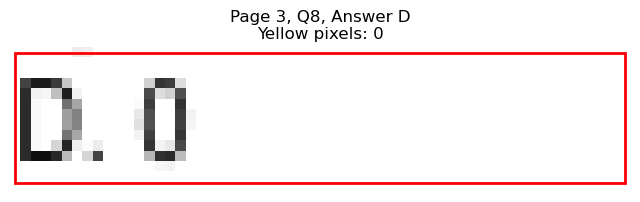

Page 3, Q8 - E: Detected box: x0=315.4, y0=695.4, x1=323.9, y1=708.0
Page 3, Q8, E: Yellow pixels: 718
Page 3, Q8, E: Total non-white pixels: 767
Page 3, Q8, E: Yellow percentage: 93.6%


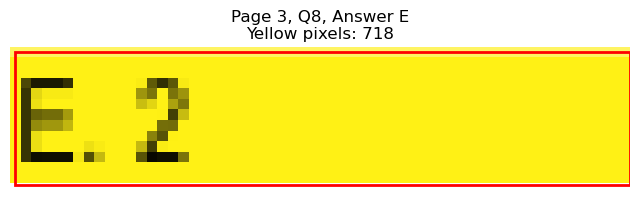


Page 3, Q8 - Selected Answer: E (based on yellow pixel count)





Page 4: Found 9 questions
Page 4, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=116.9, y1=102.1
Page 4, Q1, A: Yellow pixels: 0
Page 4, Q1, A: Total non-white pixels: 265
Page 4, Q1, A: Yellow percentage: 0.0%


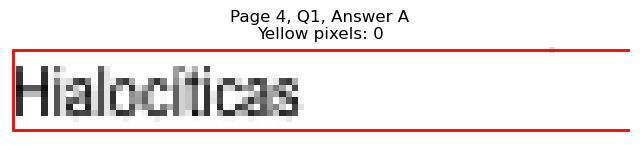

Page 4, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=127.9, y1=114.7
Page 4, Q1, B: Yellow pixels: 0
Page 4, Q1, B: Total non-white pixels: 324
Page 4, Q1, B: Yellow percentage: 0.0%


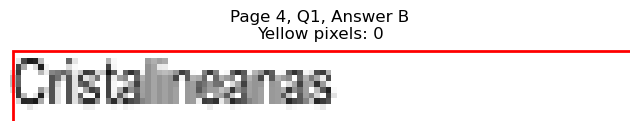

Page 4, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=118.0, y1=127.3
Page 4, Q1, C: Yellow pixels: 0
Page 4, Q1, C: Total non-white pixels: 247
Page 4, Q1, C: Yellow percentage: 0.0%


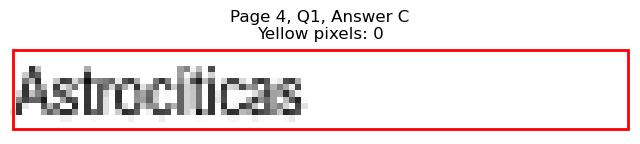

Page 4, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=387.8, y1=102.1
Page 4, Q1, D: Yellow pixels: 1186
Page 4, Q1, D: Total non-white pixels: 1554
Page 4, Q1, D: Yellow percentage: 76.3%


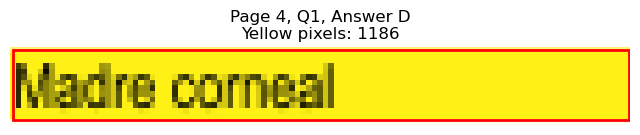

Page 4, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=379.3, y1=114.7
Page 4, Q1, E: Yellow pixels: 0
Page 4, Q1, E: Total non-white pixels: 358
Page 4, Q1, E: Yellow percentage: 0.0%


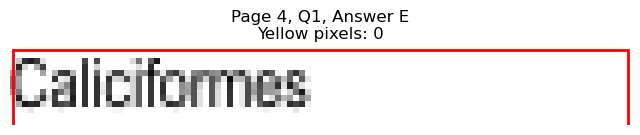


Page 4, Q1 - Selected Answer: D (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=68.3, y0=152.5, x1=110.4, y1=165.2
Page 4, Q2, A: Yellow pixels: 93
Page 4, Q2, A: Total non-white pixels: 297
Page 4, Q2, A: Yellow percentage: 31.3%


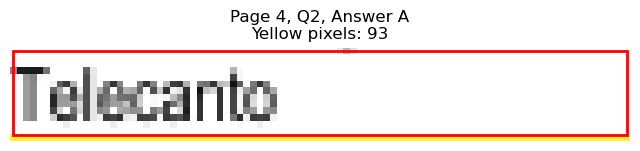

Page 4, Q2 - B: Detected box: x0=68.3, y0=165.1, x1=129.0, y1=177.8
Page 4, Q2, B: Yellow pixels: 1222
Page 4, Q2, B: Total non-white pixels: 1456
Page 4, Q2, B: Yellow percentage: 83.9%


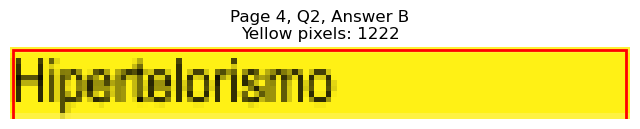

Page 4, Q2 - C: Detected box: x0=68.8, y0=177.7, x1=115.9, y1=190.4
Page 4, Q2, C: Yellow pixels: 98
Page 4, Q2, C: Total non-white pixels: 331
Page 4, Q2, C: Yellow percentage: 29.6%


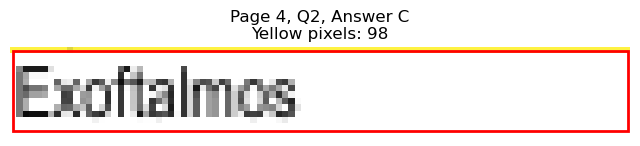

Page 4, Q2 - D: Detected box: x0=327.5, y0=152.5, x1=368.2, y1=165.2
Page 4, Q2, D: Yellow pixels: 0
Page 4, Q2, D: Total non-white pixels: 206
Page 4, Q2, D: Yellow percentage: 0.0%


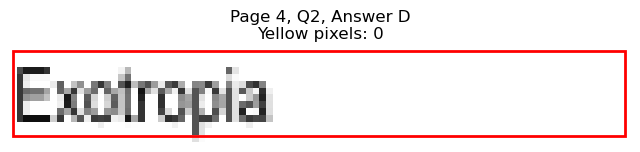

Page 4, Q2 - E: Detected box: x0=327.0, y0=165.1, x1=371.7, y1=177.8
Page 4, Q2, E: Yellow pixels: 0
Page 4, Q2, E: Total non-white pixels: 238
Page 4, Q2, E: Yellow percentage: 0.0%


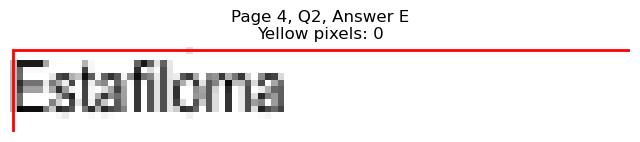


Page 4, Q2 - Selected Answer: B (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=178.1, y1=266.1
Page 4, Q3, A: Yellow pixels: 0
Page 4, Q3, A: Total non-white pixels: 510
Page 4, Q3, A: Yellow percentage: 0.0%


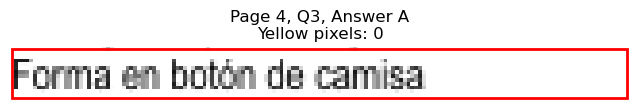

Page 4, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=222.4, y1=278.7
Page 4, Q3, B: Yellow pixels: 0
Page 4, Q3, B: Total non-white pixels: 747
Page 4, Q3, B: Yellow percentage: 0.0%


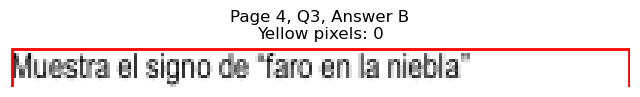

Page 4, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=215.8, y1=291.5
Page 4, Q3, C: Yellow pixels: 0
Page 4, Q3, C: Total non-white pixels: 720
Page 4, Q3, C: Yellow percentage: 0.0%


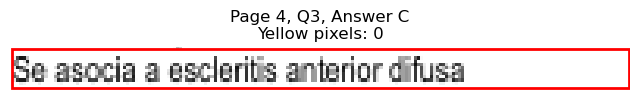

Page 4, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=491.6, y1=266.1
Page 4, Q3, D: Yellow pixels: 2163
Page 4, Q3, D: Total non-white pixels: 2995
Page 4, Q3, D: Yellow percentage: 72.2%


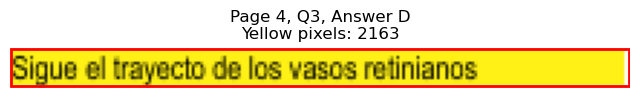

Page 4, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=475.5, y1=278.7
Page 4, Q3, E: Yellow pixels: 0
Page 4, Q3, E: Total non-white pixels: 948
Page 4, Q3, E: Yellow percentage: 0.0%


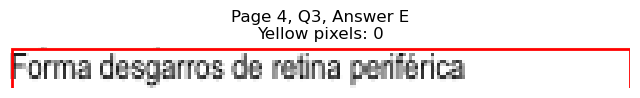


Page 4, Q3 - Selected Answer: D (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=185.7, y1=367.2
Page 4, Q4, A: Yellow pixels: 0
Page 4, Q4, A: Total non-white pixels: 587
Page 4, Q4, A: Yellow percentage: 0.0%


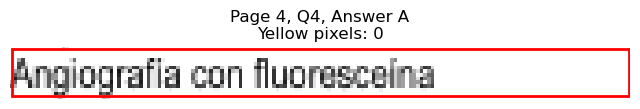

Page 4, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=161.1, y1=379.8
Page 4, Q4, B: Yellow pixels: 0
Page 4, Q4, B: Total non-white pixels: 618
Page 4, Q4, B: Yellow percentage: 0.0%


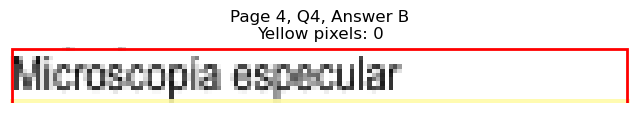

Page 4, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=194.7, y1=392.4
Page 4, Q4, C: Yellow pixels: 1624
Page 4, Q4, C: Total non-white pixels: 2478
Page 4, Q4, C: Yellow percentage: 65.5%


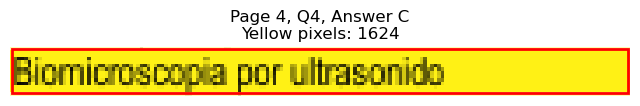

Page 4, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=458.9, y1=367.2
Page 4, Q4, D: Yellow pixels: 0
Page 4, Q4, D: Total non-white pixels: 661
Page 4, Q4, D: Yellow percentage: 0.0%


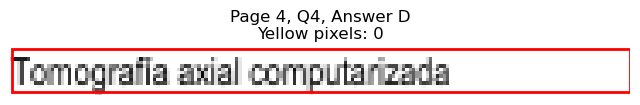

Page 4, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=453.4, y1=379.8
Page 4, Q4, E: Yellow pixels: 0
Page 4, Q4, E: Total non-white pixels: 675
Page 4, Q4, E: Yellow percentage: 0.0%


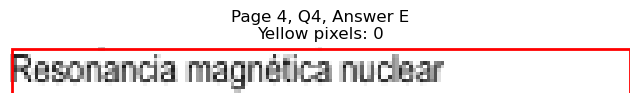


Page 4, Q4 - Selected Answer: C (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=68.3, y0=442.8, x1=192.6, y1=455.5
Page 4, Q5, A: Yellow pixels: 1781
Page 4, Q5, A: Total non-white pixels: 2450
Page 4, Q5, A: Yellow percentage: 72.7%


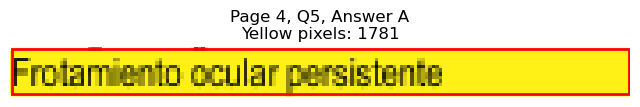

Page 4, Q5 - B: Detected box: x0=68.3, y0=455.5, x1=218.2, y1=468.1
Page 4, Q5, B: Yellow pixels: 0
Page 4, Q5, B: Total non-white pixels: 737
Page 4, Q5, B: Yellow percentage: 0.0%


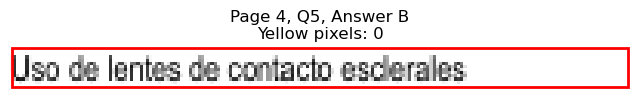

Page 4, Q5 - C: Detected box: x0=68.8, y0=468.1, x1=176.7, y1=480.7
Page 4, Q5, C: Yellow pixels: 0
Page 4, Q5, C: Total non-white pixels: 508
Page 4, Q5, C: Yellow percentage: 0.0%


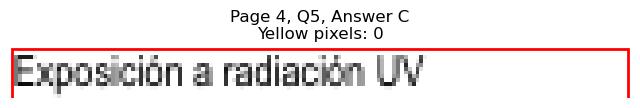

Page 4, Q5 - D: Detected box: x0=327.5, y0=442.8, x1=449.5, y1=455.5
Page 4, Q5, D: Yellow pixels: 0
Page 4, Q5, D: Total non-white pixels: 612
Page 4, Q5, D: Yellow percentage: 0.0%


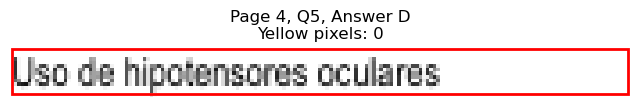

Page 4, Q5 - E: Detected box: x0=327.0, y0=455.5, x1=469.1, y1=468.1
Page 4, Q5, E: Yellow pixels: 0
Page 4, Q5, E: Total non-white pixels: 749
Page 4, Q5, E: Yellow percentage: 0.0%


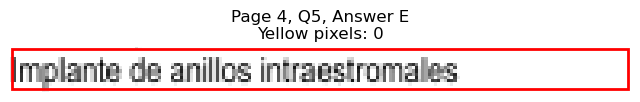


Page 4, Q5 - Selected Answer: A (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=68.3, y0=531.2, x1=145.0, y1=543.8
Page 4, Q6, A: Yellow pixels: 1342
Page 4, Q6, A: Total non-white pixels: 1651
Page 4, Q6, A: Yellow percentage: 81.3%


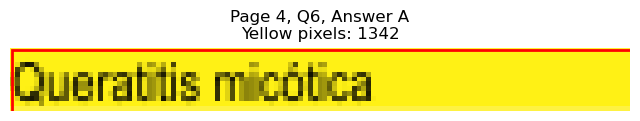

Page 4, Q6 - B: Detected box: x0=68.3, y0=543.8, x1=145.6, y1=556.4
Page 4, Q6, B: Yellow pixels: 128
Page 4, Q6, B: Total non-white pixels: 529
Page 4, Q6, B: Yellow percentage: 24.2%


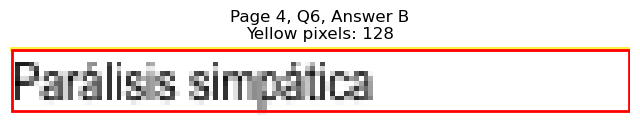

Page 4, Q6 - C: Detected box: x0=68.8, y0=556.5, x1=141.5, y1=569.2
Page 4, Q6, C: Yellow pixels: 0
Page 4, Q6, C: Total non-white pixels: 378
Page 4, Q6, C: Yellow percentage: 0.0%


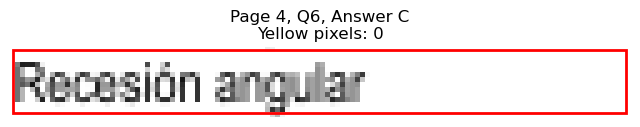

Page 4, Q6 - D: Detected box: x0=327.5, y0=531.2, x1=416.8, y1=543.8
Page 4, Q6, D: Yellow pixels: 0
Page 4, Q6, D: Total non-white pixels: 434
Page 4, Q6, D: Yellow percentage: 0.0%


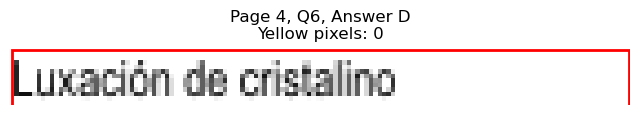

Page 4, Q6 - E: Detected box: x0=327.0, y0=543.8, x1=379.3, y1=556.4
Page 4, Q6, E: Yellow pixels: 0
Page 4, Q6, E: Total non-white pixels: 271
Page 4, Q6, E: Yellow percentage: 0.0%


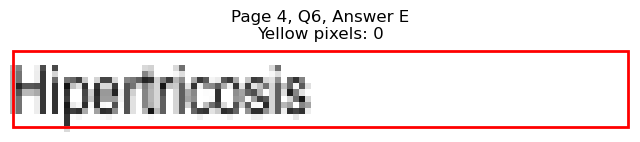


Page 4, Q6 - Selected Answer: A (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=68.3, y0=594.3, x1=109.5, y1=607.0
Page 4, Q7, A: Yellow pixels: 0
Page 4, Q7, A: Total non-white pixels: 225
Page 4, Q7, A: Yellow percentage: 0.0%


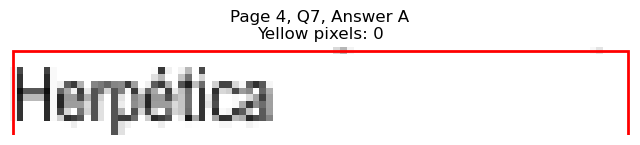

Page 4, Q7 - B: Detected box: x0=68.3, y0=606.9, x1=112.5, y1=619.6
Page 4, Q7, B: Yellow pixels: 0
Page 4, Q7, B: Total non-white pixels: 234
Page 4, Q7, B: Yellow percentage: 0.0%


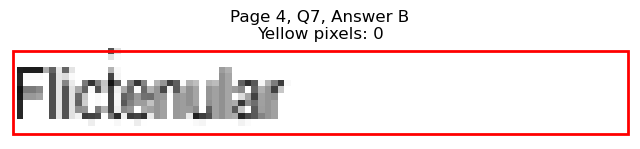

Page 4, Q7 - C: Detected box: x0=68.8, y0=619.6, x1=113.4, y1=632.3
Page 4, Q7, C: Yellow pixels: 0
Page 4, Q7, C: Total non-white pixels: 234
Page 4, Q7, C: Yellow percentage: 0.0%


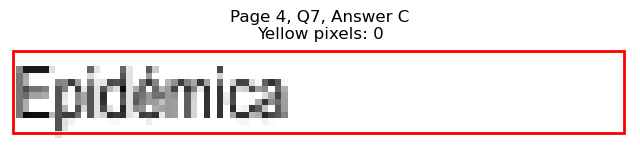

Page 4, Q7 - D: Detected box: x0=327.5, y0=594.3, x1=359.7, y1=607.0
Page 4, Q7, D: Yellow pixels: 0
Page 4, Q7, D: Total non-white pixels: 227
Page 4, Q7, D: Yellow percentage: 0.0%


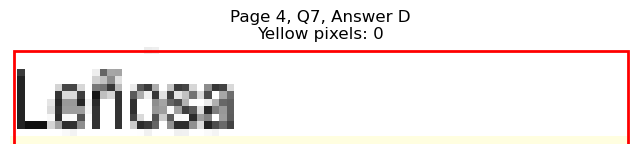

Page 4, Q7 - E: Detected box: x0=327.0, y0=606.9, x1=355.6, y1=619.6
Page 4, Q7, E: Yellow pixels: 905
Page 4, Q7, E: Total non-white pixels: 1106
Page 4, Q7, E: Yellow percentage: 81.8%


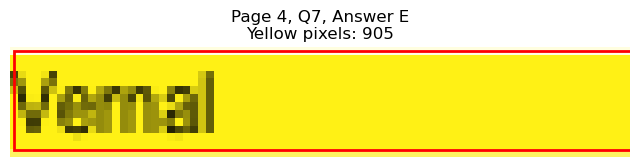


Page 4, Q7 - Selected Answer: E (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=68.3, y0=657.5, x1=147.5, y1=670.1
Page 4, Q8, A: Yellow pixels: 130
Page 4, Q8, A: Total non-white pixels: 532
Page 4, Q8, A: Yellow percentage: 24.4%


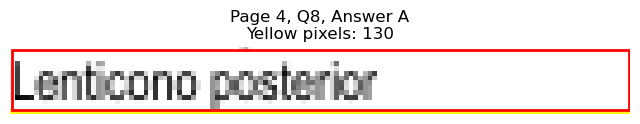

Page 4, Q8 - B: Detected box: x0=68.3, y0=670.1, x1=143.1, y1=682.7
Page 4, Q8, B: Yellow pixels: 1366
Page 4, Q8, B: Total non-white pixels: 1638
Page 4, Q8, B: Yellow percentage: 83.4%


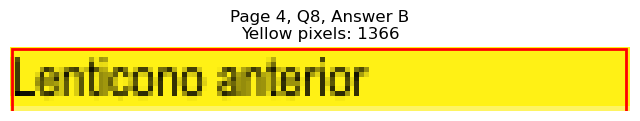

Page 4, Q8 - C: Detected box: x0=68.8, y0=682.7, x1=112.9, y1=695.3
Page 4, Q8, C: Yellow pixels: 95
Page 4, Q8, C: Total non-white pixels: 313
Page 4, Q8, C: Yellow percentage: 30.4%


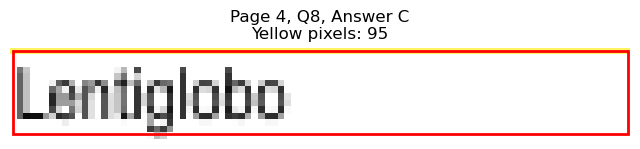

Page 4, Q8 - D: Detected box: x0=327.5, y0=657.5, x1=371.2, y1=670.1
Page 4, Q8, D: Yellow pixels: 0
Page 4, Q8, D: Total non-white pixels: 223
Page 4, Q8, D: Yellow percentage: 0.0%


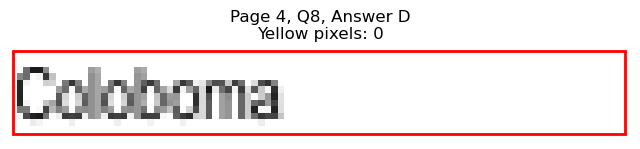

Page 4, Q8 - E: Detected box: x0=327.0, y0=670.1, x1=401.3, y1=682.7
Page 4, Q8, E: Yellow pixels: 0
Page 4, Q8, E: Total non-white pixels: 397
Page 4, Q8, E: Yellow percentage: 0.0%


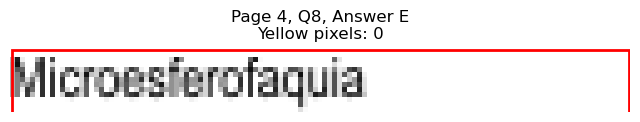


Page 4, Q8 - Selected Answer: B (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=68.3, y0=720.6, x1=96.4, y1=733.2
Page 4, Q9, A: Yellow pixels: 0
Page 4, Q9, A: Total non-white pixels: 129
Page 4, Q9, A: Yellow percentage: 0.0%


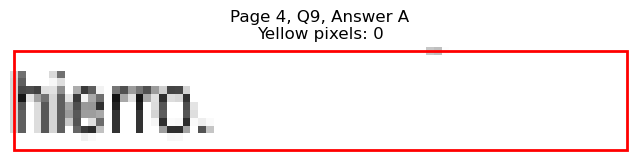

Page 4, Q9 - B: Detected box: x0=68.3, y0=733.2, x1=96.4, y1=745.8
Page 4, Q9, B: Yellow pixels: 0
Page 4, Q9, B: Total non-white pixels: 130
Page 4, Q9, B: Yellow percentage: 0.0%


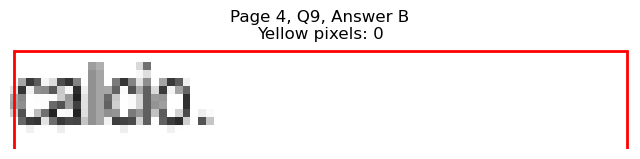

Page 4, Q9 - C: Detected box: x0=68.8, y0=745.8, x1=86.9, y1=758.4
Page 4, Q9, C: Yellow pixels: 0
Page 4, Q9, C: Total non-white pixels: 66
Page 4, Q9, C: Yellow percentage: 0.0%


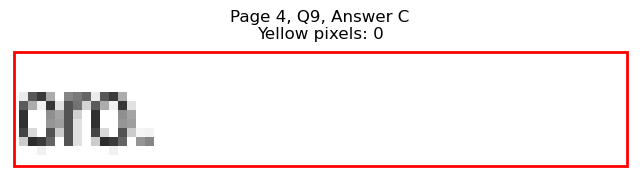

Page 4, Q9 - D: Detected box: x0=327.5, y0=720.6, x1=357.2, y1=733.2
Page 4, Q9, D: Yellow pixels: 81
Page 4, Q9, D: Total non-white pixels: 202
Page 4, Q9, D: Yellow percentage: 40.1%


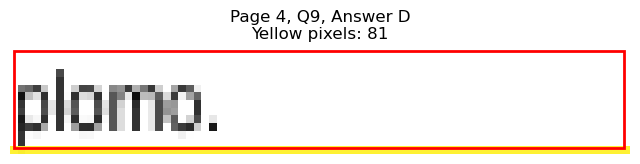

Page 4, Q9 - E: Detected box: x0=327.0, y0=733.2, x1=354.7, y1=745.8
Page 4, Q9, E: Yellow pixels: 921
Page 4, Q9, E: Total non-white pixels: 1014
Page 4, Q9, E: Yellow percentage: 90.8%


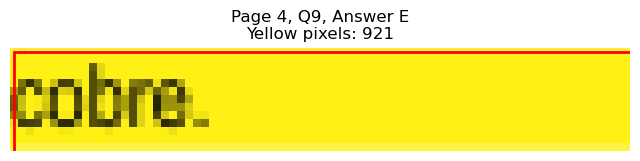


Page 4, Q9 - Selected Answer: E (based on yellow pixel count)





Page 5: Found 8 questions
Page 5, Q1 - A: Detected box: x0=68.3, y0=127.2, x1=137.5, y1=139.9
Page 5, Q1, A: Yellow pixels: 0
Page 5, Q1, A: Total non-white pixels: 361
Page 5, Q1, A: Yellow percentage: 0.0%


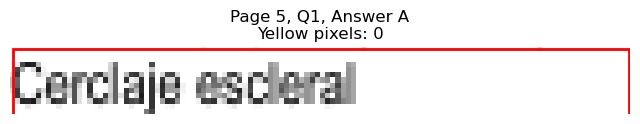

Page 5, Q1 - B: Detected box: x0=68.3, y0=139.9, x1=133.5, y1=152.6
Page 5, Q1, B: Yellow pixels: 1248
Page 5, Q1, B: Total non-white pixels: 1624
Page 5, Q1, B: Yellow percentage: 76.8%


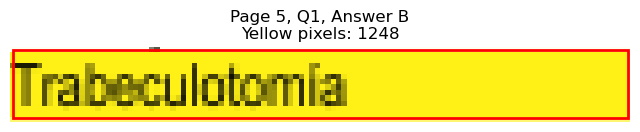

Page 5, Q1 - C: Detected box: x0=68.8, y0=152.5, x1=137.5, y1=165.2
Page 5, Q1, C: Yellow pixels: 120
Page 5, Q1, C: Total non-white pixels: 470
Page 5, Q1, C: Yellow percentage: 25.5%


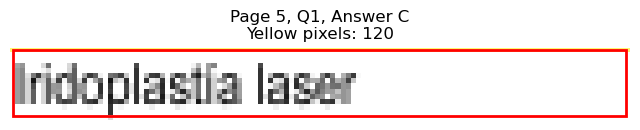

Page 5, Q1 - D: Detected box: x0=327.5, y0=127.2, x1=406.7, y1=139.9
Page 5, Q1, D: Yellow pixels: 0
Page 5, Q1, D: Total non-white pixels: 424
Page 5, Q1, D: Yellow percentage: 0.0%


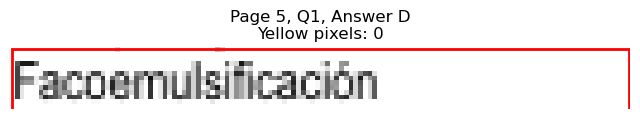

Page 5, Q1 - E: Detected box: x0=327.0, y0=139.9, x1=381.8, y1=152.6
Page 5, Q1, E: Yellow pixels: 0
Page 5, Q1, E: Total non-white pixels: 293
Page 5, Q1, E: Yellow percentage: 0.0%


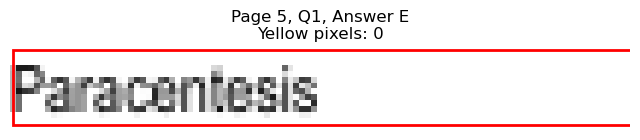


Page 5, Q1 - Selected Answer: B (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=68.3, y0=202.9, x1=109.0, y1=215.6
Page 5, Q2, A: Yellow pixels: 0
Page 5, Q2, A: Total non-white pixels: 209
Page 5, Q2, A: Yellow percentage: 0.0%


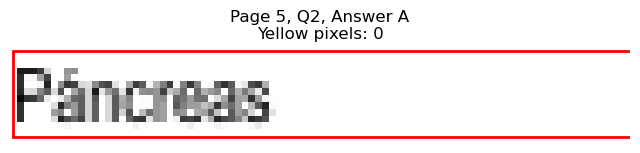

Page 5, Q2 - B: Detected box: x0=68.3, y0=215.7, x1=102.9, y1=228.3
Page 5, Q2, B: Yellow pixels: 0
Page 5, Q2, B: Total non-white pixels: 177
Page 5, Q2, B: Yellow percentage: 0.0%


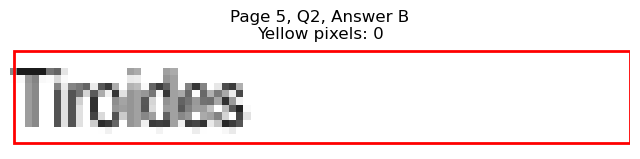

Page 5, Q2 - C: Detected box: x0=68.8, y0=228.3, x1=100.3, y1=240.9
Page 5, Q2, C: Yellow pixels: 0
Page 5, Q2, C: Total non-white pixels: 162
Page 5, Q2, C: Yellow percentage: 0.0%


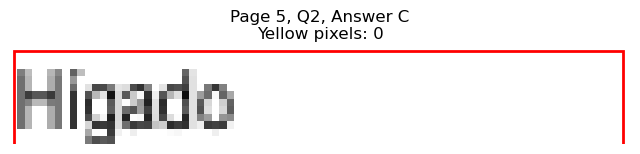

Page 5, Q2 - D: Detected box: x0=327.5, y0=202.9, x1=360.7, y1=215.6
Page 5, Q2, D: Yellow pixels: 978
Page 5, Q2, D: Total non-white pixels: 1176
Page 5, Q2, D: Yellow percentage: 83.2%


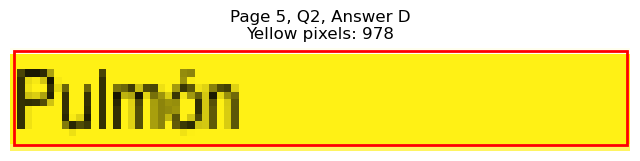

Page 5, Q2 - E: Detected box: x0=327.0, y0=215.7, x1=353.1, y1=228.3
Page 5, Q2, E: Yellow pixels: 77
Page 5, Q2, E: Total non-white pixels: 205
Page 5, Q2, E: Yellow percentage: 37.6%


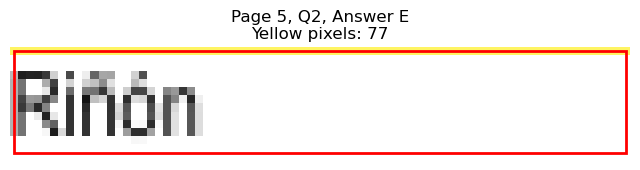


Page 5, Q2 - Selected Answer: D (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=287.0, y1=278.7
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 1060
Page 5, Q3, A: Yellow percentage: 0.0%


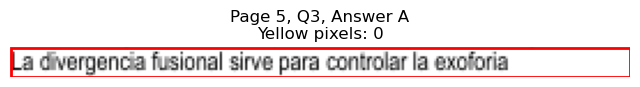

Page 5, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=299.4, y1=291.5
Page 5, Q3, B: Yellow pixels: 0
Page 5, Q3, B: Total non-white pixels: 1123
Page 5, Q3, B: Yellow percentage: 0.0%


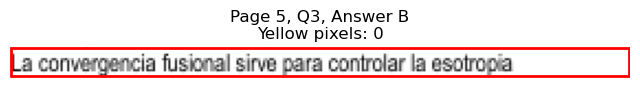

Page 5, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=291.5, y1=304.1
Page 5, Q3, C: Yellow pixels: 0
Page 5, Q3, C: Total non-white pixels: 1076
Page 5, Q3, C: Yellow percentage: 0.0%


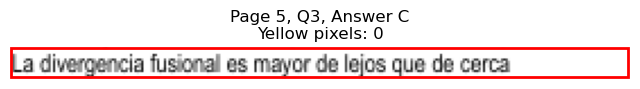

Page 5, Q3 - D: Detected box: x0=68.8, y0=304.0, x1=295.0, y1=316.7
Page 5, Q3, D: Yellow pixels: 3
Page 5, Q3, D: Total non-white pixels: 1375
Page 5, Q3, D: Yellow percentage: 0.2%


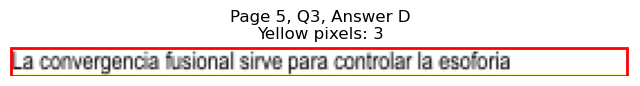

Page 5, Q3 - E: Detected box: x0=68.3, y0=316.6, x1=298.6, y1=329.3
Page 5, Q3, E: Yellow pixels: 2519
Page 5, Q3, E: Total non-white pixels: 3934
Page 5, Q3, E: Yellow percentage: 64.0%


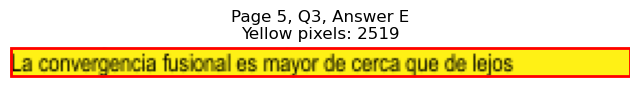


Page 5, Q3 - Selected Answer: E (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=163.1, y1=367.2
Page 5, Q4, A: Yellow pixels: 146
Page 5, Q4, A: Total non-white pixels: 602
Page 5, Q4, A: Yellow percentage: 24.3%


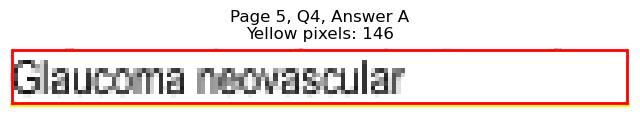

Page 5, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=127.5, y1=379.8
Page 5, Q4, B: Yellow pixels: 1213
Page 5, Q4, B: Total non-white pixels: 1430
Page 5, Q4, B: Yellow percentage: 84.8%


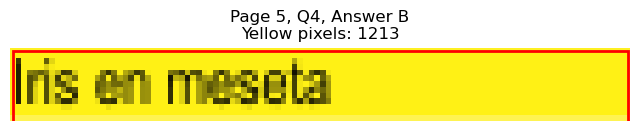

Page 5, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=163.6, y1=392.4
Page 5, Q4, C: Yellow pixels: 146
Page 5, Q4, C: Total non-white pixels: 650
Page 5, Q4, C: Yellow percentage: 22.5%


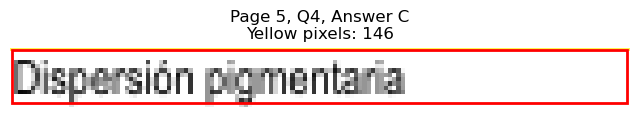

Page 5, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=434.3, y1=367.2
Page 5, Q4, D: Yellow pixels: 0
Page 5, Q4, D: Total non-white pixels: 571
Page 5, Q4, D: Yellow percentage: 0.0%


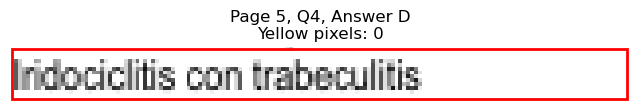

Page 5, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=398.3, y1=379.8
Page 5, Q4, E: Yellow pixels: 0
Page 5, Q4, E: Total non-white pixels: 388
Page 5, Q4, E: Yellow percentage: 0.0%


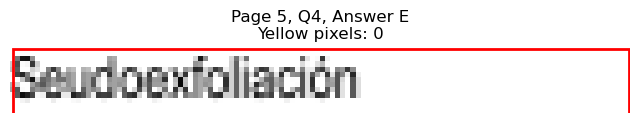


Page 5, Q4 - Selected Answer: B (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=164.5, y1=430.3
Page 5, Q5, A: Yellow pixels: 147
Page 5, Q5, A: Total non-white pixels: 611
Page 5, Q5, A: Yellow percentage: 24.1%


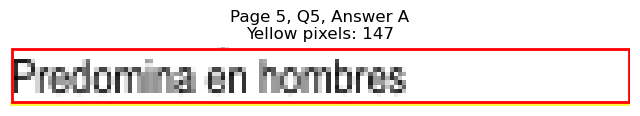

Page 5, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=220.8, y1=442.9
Page 5, Q5, B: Yellow pixels: 2054
Page 5, Q5, B: Total non-white pixels: 2639
Page 5, Q5, B: Yellow percentage: 77.8%


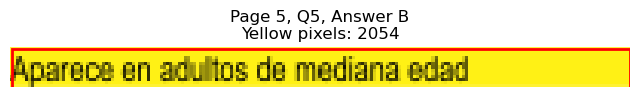

Page 5, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=211.2, y1=455.5
Page 5, Q5, C: Yellow pixels: 193
Page 5, Q5, C: Total non-white pixels: 860
Page 5, Q5, C: Yellow percentage: 22.4%


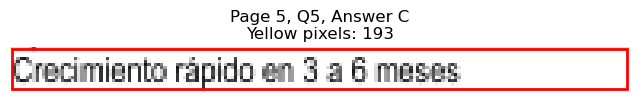

Page 5, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=528.2, y1=430.3
Page 5, Q5, D: Yellow pixels: 0
Page 5, Q5, D: Total non-white pixels: 959
Page 5, Q5, D: Yellow percentage: 0.0%


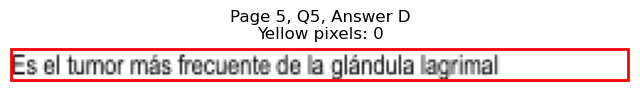

Page 5, Q5 - E: Detected box: x0=327.0, y0=430.2, x1=520.2, y1=442.9
Page 5, Q5, E: Yellow pixels: 0
Page 5, Q5, E: Total non-white pixels: 945
Page 5, Q5, E: Yellow percentage: 0.0%


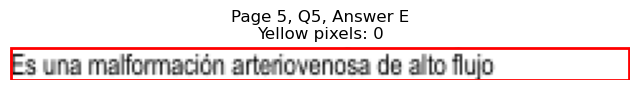


Page 5, Q5 - Selected Answer: B (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=68.3, y0=518.6, x1=76.8, y1=531.2
Page 5, Q6, A: Yellow pixels: 59
Page 5, Q6, A: Total non-white pixels: 90
Page 5, Q6, A: Yellow percentage: 65.6%


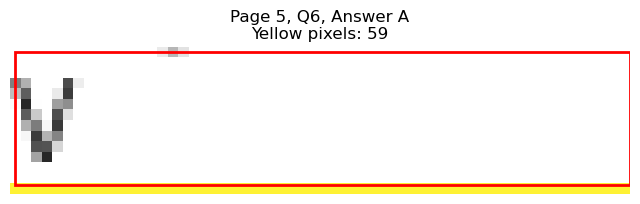

Page 5, Q6 - B: Detected box: x0=68.3, y0=531.2, x1=79.3, y1=543.8
Page 5, Q6, B: Yellow pixels: 776
Page 5, Q6, B: Total non-white pixels: 806
Page 5, Q6, B: Yellow percentage: 96.3%


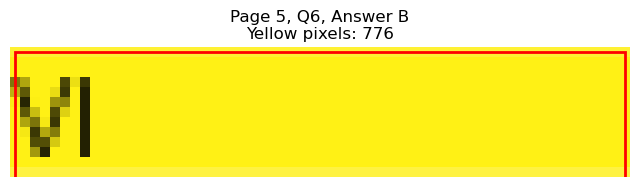

Page 5, Q6 - C: Detected box: x0=68.8, y0=543.8, x1=79.8, y1=556.4
Page 5, Q6, C: Yellow pixels: 62
Page 5, Q6, C: Total non-white pixels: 106
Page 5, Q6, C: Yellow percentage: 58.5%


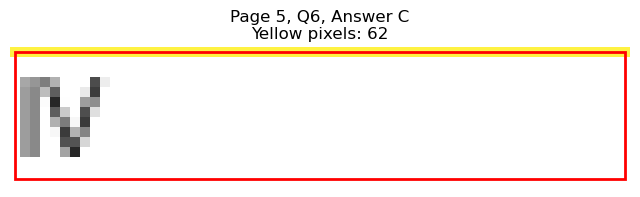

Page 5, Q6 - D: Detected box: x0=327.5, y0=518.6, x1=337.6, y1=531.2
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 48
Page 5, Q6, D: Yellow percentage: 0.0%


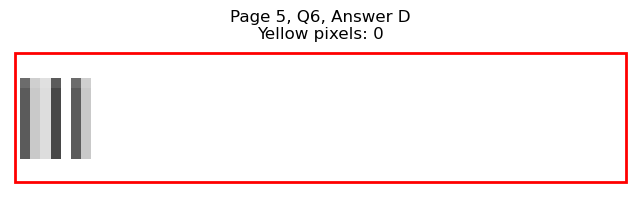

Page 5, Q6 - E: Detected box: x0=327.0, y0=531.2, x1=340.6, y1=543.8
Page 5, Q6, E: Yellow pixels: 0
Page 5, Q6, E: Total non-white pixels: 58
Page 5, Q6, E: Yellow percentage: 0.0%


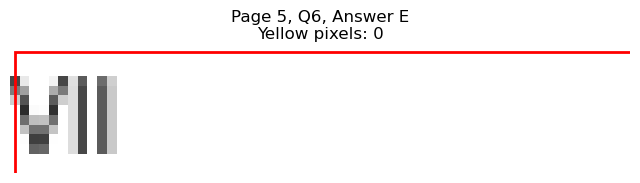


Page 5, Q6 - Selected Answer: B (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=68.3, y0=619.6, x1=140.5, y1=632.3
Page 5, Q7, A: Yellow pixels: 0
Page 5, Q7, A: Total non-white pixels: 393
Page 5, Q7, A: Yellow percentage: 0.0%


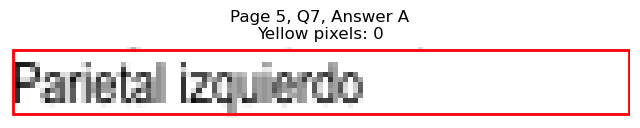

Page 5, Q7 - B: Detected box: x0=68.3, y0=632.2, x1=148.0, y1=644.9
Page 5, Q7, B: Yellow pixels: 0
Page 5, Q7, B: Total non-white pixels: 362
Page 5, Q7, B: Yellow percentage: 0.0%


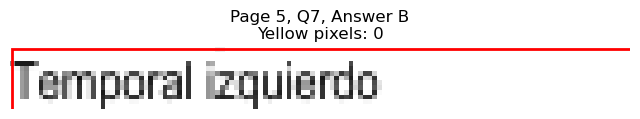

Page 5, Q7 - C: Detected box: x0=68.8, y0=644.9, x1=145.0, y1=657.5
Page 5, Q7, C: Yellow pixels: 0
Page 5, Q7, C: Total non-white pixels: 391
Page 5, Q7, C: Yellow percentage: 0.0%


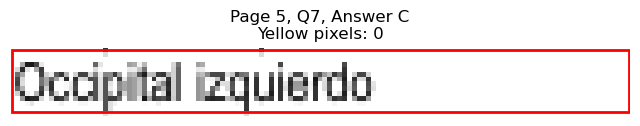

Page 5, Q7 - D: Detected box: x0=327.5, y0=619.6, x1=395.7, y1=632.3
Page 5, Q7, D: Yellow pixels: 119
Page 5, Q7, D: Total non-white pixels: 460
Page 5, Q7, D: Yellow percentage: 25.9%


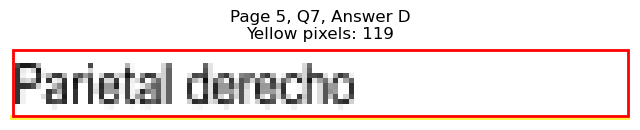

Page 5, Q7 - E: Detected box: x0=327.0, y0=632.2, x1=402.8, y1=644.9
Page 5, Q7, E: Yellow pixels: 1343
Page 5, Q7, E: Total non-white pixels: 1638
Page 5, Q7, E: Yellow percentage: 82.0%


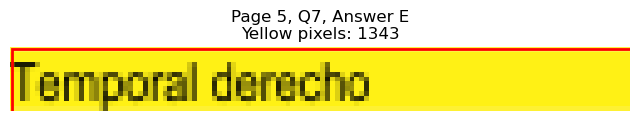


Page 5, Q7 - Selected Answer: E (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=68.3, y0=695.4, x1=150.6, y1=708.0
Page 5, Q8, A: Yellow pixels: 133
Page 5, Q8, A: Total non-white pixels: 658
Page 5, Q8, A: Yellow percentage: 20.2%


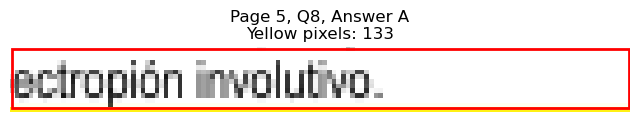

Page 5, Q8 - B: Detected box: x0=68.3, y0=708.0, x1=151.1, y1=720.6
Page 5, Q8, B: Yellow pixels: 1409
Page 5, Q8, B: Total non-white pixels: 1876
Page 5, Q8, B: Yellow percentage: 75.1%


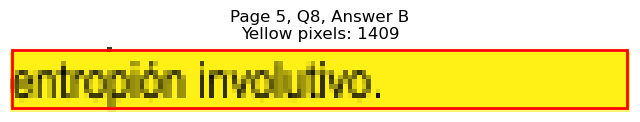

Page 5, Q8 - C: Detected box: x0=68.8, y0=720.6, x1=152.1, y1=733.2
Page 5, Q8, C: Yellow pixels: 135
Page 5, Q8, C: Total non-white pixels: 536
Page 5, Q8, C: Yellow percentage: 25.2%


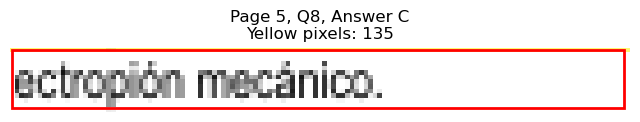

Page 5, Q8 - D: Detected box: x0=327.5, y0=695.4, x1=409.7, y1=708.0
Page 5, Q8, D: Yellow pixels: 0
Page 5, Q8, D: Total non-white pixels: 424
Page 5, Q8, D: Yellow percentage: 0.0%


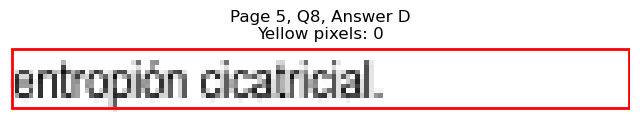

Page 5, Q8 - E: Detected box: x0=327.0, y0=708.0, x1=411.3, y1=720.6
Page 5, Q8, E: Yellow pixels: 0
Page 5, Q8, E: Total non-white pixels: 435
Page 5, Q8, E: Yellow percentage: 0.0%


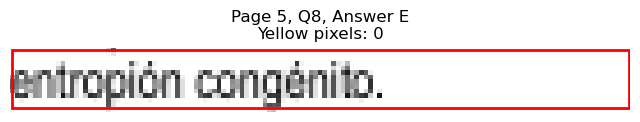


Page 5, Q8 - Selected Answer: B (based on yellow pixel count)





Page 6: Found 10 questions
Page 6, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=136.5, y1=102.1
Page 6, Q1, A: Yellow pixels: 0
Page 6, Q1, A: Total non-white pixels: 341
Page 6, Q1, A: Yellow percentage: 0.0%


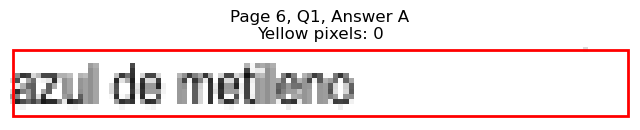

Page 6, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=156.6, y1=114.7
Page 6, Q1, B: Yellow pixels: 0
Page 6, Q1, B: Total non-white pixels: 568
Page 6, Q1, B: Yellow percentage: 0.0%


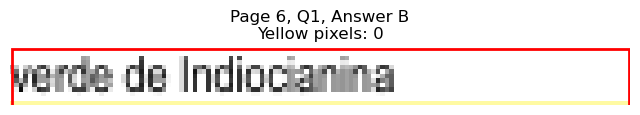

Page 6, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=137.1, y1=127.3
Page 6, Q1, C: Yellow pixels: 1184
Page 6, Q1, C: Total non-white pixels: 1680
Page 6, Q1, C: Yellow percentage: 70.5%


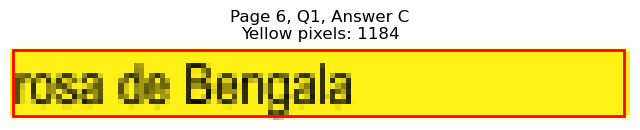

Page 6, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=367.1, y1=102.1
Page 6, Q1, D: Yellow pixels: 0
Page 6, Q1, D: Total non-white pixels: 186
Page 6, Q1, D: Yellow percentage: 0.0%


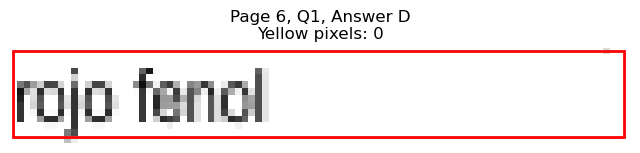

Page 6, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=386.2, y1=114.7
Page 6, Q1, E: Yellow pixels: 0
Page 6, Q1, E: Total non-white pixels: 291
Page 6, Q1, E: Yellow percentage: 0.0%


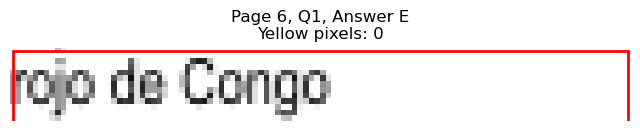


Page 6, Q1 - Selected Answer: C (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=105.5, y1=177.8
Page 6, Q2, A: Yellow pixels: 996
Page 6, Q2, A: Total non-white pixels: 1144
Page 6, Q2, A: Yellow percentage: 87.1%


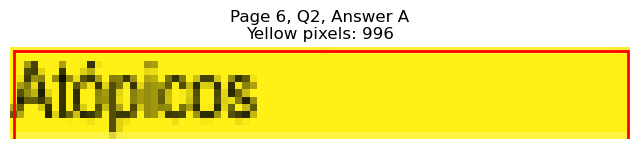

Page 6, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=102.0, y1=190.4
Page 6, Q2, B: Yellow pixels: 85
Page 6, Q2, B: Total non-white pixels: 261
Page 6, Q2, B: Yellow percentage: 32.6%


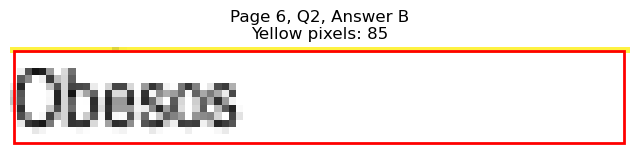

Page 6, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=117.0, y1=203.0
Page 6, Q2, C: Yellow pixels: 0
Page 6, Q2, C: Total non-white pixels: 246
Page 6, Q2, C: Yellow percentage: 0.0%


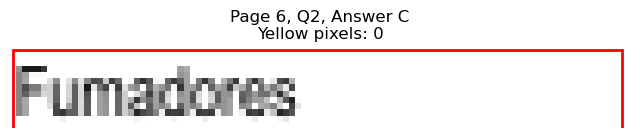

Page 6, Q2 - D: Detected box: x0=327.5, y0=165.1, x1=385.9, y1=177.8
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 319
Page 6, Q2, D: Yellow percentage: 0.0%


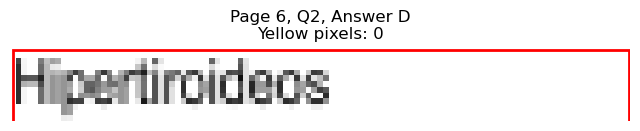

Page 6, Q2 - E: Detected box: x0=327.0, y0=177.7, x1=377.8, y1=190.4
Page 6, Q2, E: Yellow pixels: 0
Page 6, Q2, E: Total non-white pixels: 262
Page 6, Q2, E: Yellow percentage: 0.0%


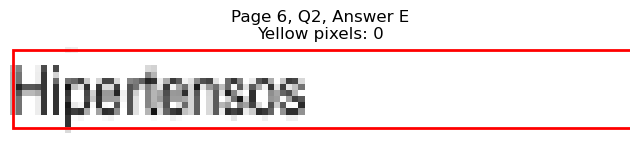


Page 6, Q2 - Selected Answer: A (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=68.3, y0=228.3, x1=116.4, y1=240.9
Page 6, Q3, A: Yellow pixels: 0
Page 6, Q3, A: Total non-white pixels: 268
Page 6, Q3, A: Yellow percentage: 0.0%


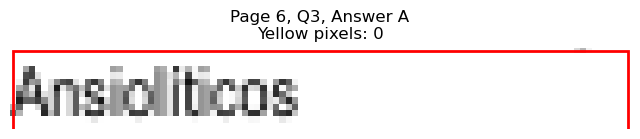

Page 6, Q3 - B: Detected box: x0=68.3, y0=240.9, x1=104.5, y1=253.5
Page 6, Q3, B: Yellow pixels: 0
Page 6, Q3, B: Total non-white pixels: 172
Page 6, Q3, B: Yellow percentage: 0.0%


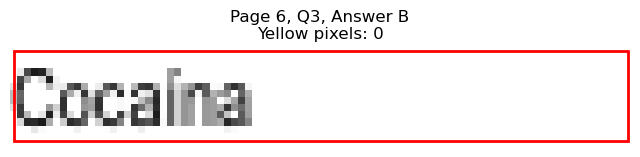

Page 6, Q3 - C: Detected box: x0=68.8, y0=253.5, x1=90.4, y1=266.1
Page 6, Q3, C: Yellow pixels: 0
Page 6, Q3, C: Total non-white pixels: 107
Page 6, Q3, C: Yellow percentage: 0.0%


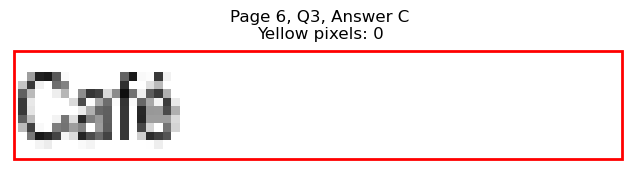

Page 6, Q3 - D: Detected box: x0=327.5, y0=228.3, x1=360.3, y1=240.9
Page 6, Q3, D: Yellow pixels: 970
Page 6, Q3, D: Total non-white pixels: 1092
Page 6, Q3, D: Yellow percentage: 88.8%


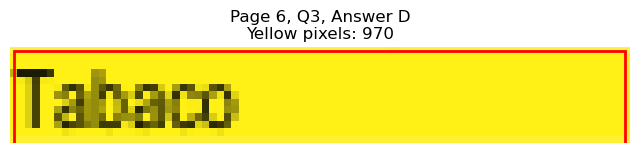

Page 6, Q3 - E: Detected box: x0=327.0, y0=240.9, x1=359.2, y1=253.5
Page 6, Q3, E: Yellow pixels: 83
Page 6, Q3, E: Total non-white pixels: 244
Page 6, Q3, E: Yellow percentage: 34.0%


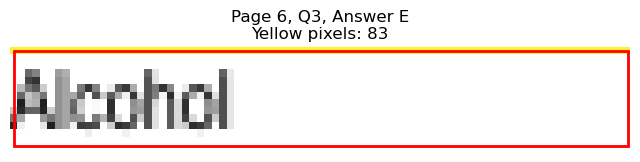


Page 6, Q3 - Selected Answer: D (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=68.3, y0=291.4, x1=134.1, y1=304.1
Page 6, Q4, A: Yellow pixels: 117
Page 6, Q4, A: Total non-white pixels: 427
Page 6, Q4, A: Yellow percentage: 27.4%


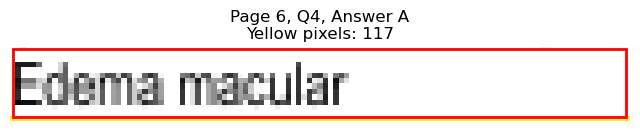

Page 6, Q4 - B: Detected box: x0=68.3, y0=304.0, x1=136.5, y1=316.7
Page 6, Q4, B: Yellow pixels: 1266
Page 6, Q4, B: Total non-white pixels: 1547
Page 6, Q4, B: Yellow percentage: 81.8%


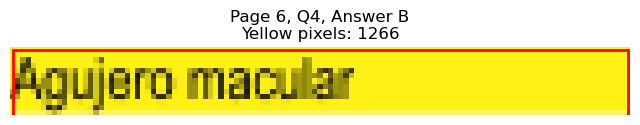

Page 6, Q4 - C: Detected box: x0=68.8, y0=316.6, x1=143.5, y1=329.3
Page 6, Q4, C: Yellow pixels: 124
Page 6, Q4, C: Total non-white pixels: 501
Page 6, Q4, C: Yellow percentage: 24.8%


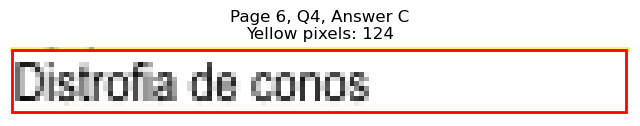

Page 6, Q4 - D: Detected box: x0=327.5, y0=291.4, x1=456.4, y1=304.1
Page 6, Q4, D: Yellow pixels: 0
Page 6, Q4, D: Total non-white pixels: 646
Page 6, Q4, D: Yellow percentage: 0.0%


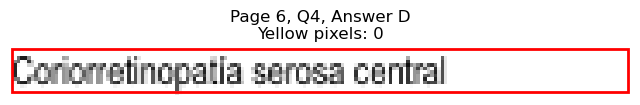

Page 6, Q4 - E: Detected box: x0=327.0, y0=304.0, x1=414.8, y1=316.7
Page 6, Q4, E: Yellow pixels: 0
Page 6, Q4, E: Total non-white pixels: 470
Page 6, Q4, E: Yellow percentage: 0.0%


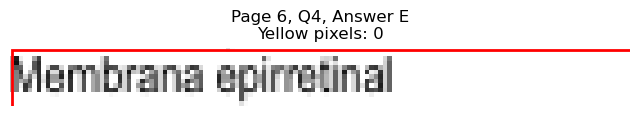


Page 6, Q4 - Selected Answer: B (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=68.3, y0=379.7, x1=143.1, y1=392.4
Page 6, Q5, A: Yellow pixels: 1254
Page 6, Q5, A: Total non-white pixels: 1764
Page 6, Q5, A: Yellow percentage: 71.1%


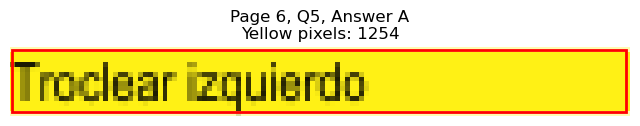

Page 6, Q5 - B: Detected box: x0=68.3, y0=392.3, x1=139.0, y1=405.0
Page 6, Q5, B: Yellow pixels: 0
Page 6, Q5, B: Total non-white pixels: 446
Page 6, Q5, B: Yellow percentage: 0.0%


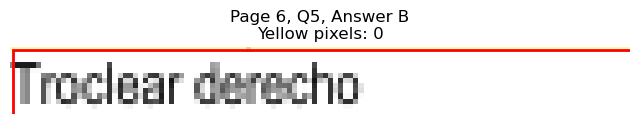

Page 6, Q5 - C: Detected box: x0=68.8, y0=404.9, x1=186.1, y1=417.6
Page 6, Q5, C: Yellow pixels: 0
Page 6, Q5, C: Total non-white pixels: 549
Page 6, Q5, C: Yellow percentage: 0.0%


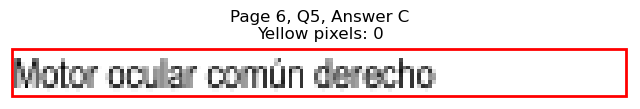

Page 6, Q5 - D: Detected box: x0=327.5, y0=379.7, x1=448.9, y1=392.4
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 592
Page 6, Q5, D: Yellow percentage: 0.0%


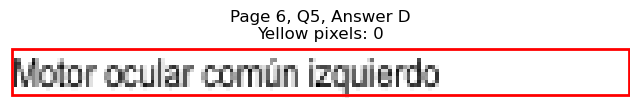

Page 6, Q5 - E: Detected box: x0=327.0, y0=392.3, x1=447.4, y1=405.0
Page 6, Q5, E: Yellow pixels: 0
Page 6, Q5, E: Total non-white pixels: 590
Page 6, Q5, E: Yellow percentage: 0.0%


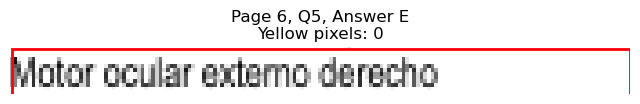


Page 6, Q5 - Selected Answer: A (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=68.3, y0=442.8, x1=76.8, y1=455.5
Page 6, Q6, A: Yellow pixels: 59
Page 6, Q6, A: Total non-white pixels: 97
Page 6, Q6, A: Yellow percentage: 60.8%


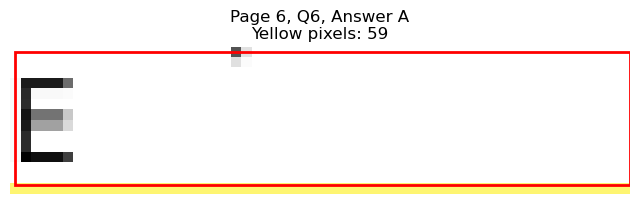

Page 6, Q6 - B: Detected box: x0=68.3, y0=455.5, x1=76.8, y1=468.1
Page 6, Q6, B: Yellow pixels: 742
Page 6, Q6, B: Total non-white pixels: 826
Page 6, Q6, B: Yellow percentage: 89.8%


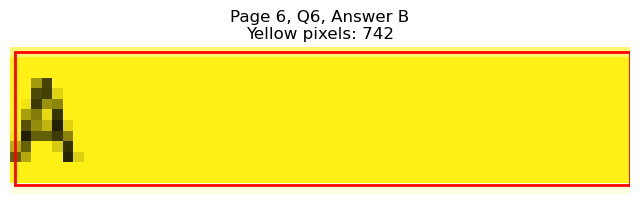

Page 6, Q6 - C: Detected box: x0=56.6, y0=468.1, x1=65.6, y1=480.7
Page 6, Q6, C: Yellow pixels: 0
Page 6, Q6, C: Total non-white pixels: 135
Page 6, Q6, C: Yellow percentage: 0.0%


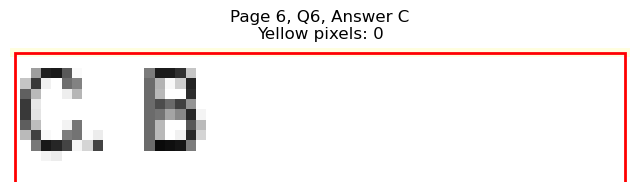

Page 6, Q6 - D: Detected box: x0=327.5, y0=442.8, x1=336.5, y1=455.5
Page 6, Q6, D: Yellow pixels: 0
Page 6, Q6, D: Total non-white pixels: 37
Page 6, Q6, D: Yellow percentage: 0.0%


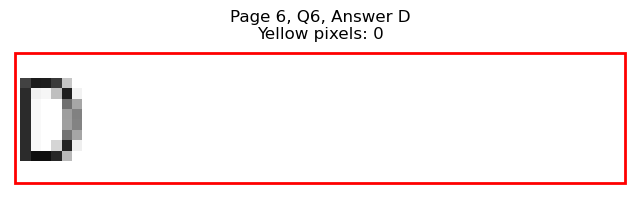

Page 6, Q6 - E: Detected box: x0=327.0, y0=455.5, x1=336.1, y1=468.1
Page 6, Q6, E: Yellow pixels: 0
Page 6, Q6, E: Total non-white pixels: 33
Page 6, Q6, E: Yellow percentage: 0.0%


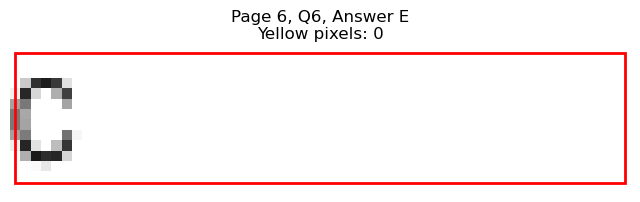


Page 6, Q6 - Selected Answer: B (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=68.3, y0=518.6, x1=106.9, y1=531.2
Page 6, Q7, A: Yellow pixels: 1012
Page 6, Q7, A: Total non-white pixels: 1246
Page 6, Q7, A: Yellow percentage: 81.2%


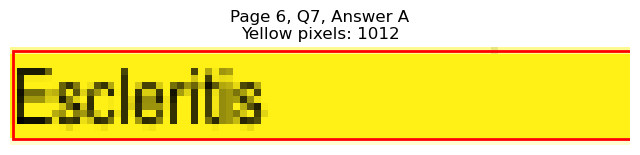

Page 6, Q7 - B: Detected box: x0=68.3, y0=531.2, x1=101.4, y1=543.8
Page 6, Q7, B: Yellow pixels: 0
Page 6, Q7, B: Total non-white pixels: 257
Page 6, Q7, B: Yellow percentage: 0.0%


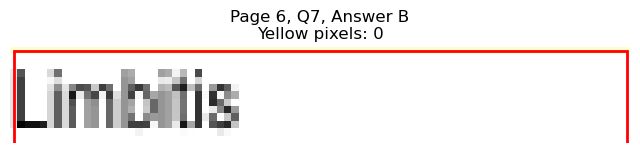

Page 6, Q7 - C: Detected box: x0=68.8, y0=543.8, x1=105.9, y1=556.4
Page 6, Q7, C: Yellow pixels: 0
Page 6, Q7, C: Total non-white pixels: 207
Page 6, Q7, C: Yellow percentage: 0.0%


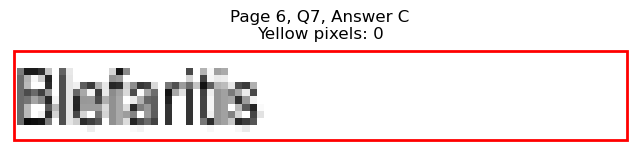

Page 6, Q7 - D: Detected box: x0=327.5, y0=518.6, x1=368.7, y1=531.2
Page 6, Q7, D: Yellow pixels: 0
Page 6, Q7, D: Total non-white pixels: 215
Page 6, Q7, D: Yellow percentage: 0.0%


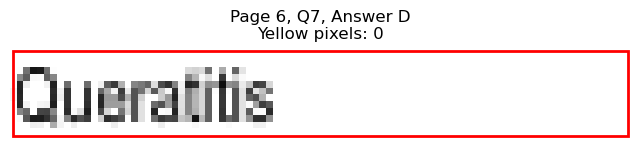

Page 6, Q7 - E: Detected box: x0=327.0, y0=531.2, x1=378.2, y1=543.8
Page 6, Q7, E: Yellow pixels: 0
Page 6, Q7, E: Total non-white pixels: 267
Page 6, Q7, E: Yellow percentage: 0.0%


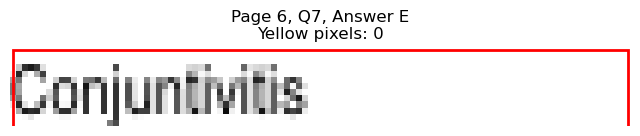


Page 6, Q7 - Selected Answer: A (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=68.3, y0=581.7, x1=253.8, y1=594.4
Page 6, Q8, A: Yellow pixels: 0
Page 6, Q8, A: Total non-white pixels: 915
Page 6, Q8, A: Yellow percentage: 0.0%


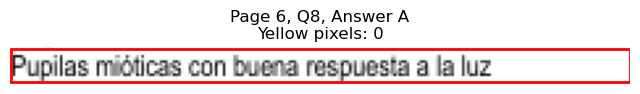

Page 6, Q8 - B: Detected box: x0=68.3, y0=594.3, x1=262.4, y1=607.0
Page 6, Q8, B: Yellow pixels: 0
Page 6, Q8, B: Total non-white pixels: 1145
Page 6, Q8, B: Yellow percentage: 0.0%


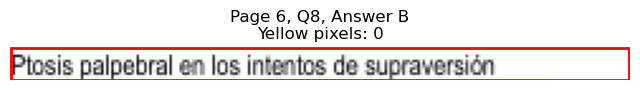

Page 6, Q8 - C: Detected box: x0=68.8, y0=606.9, x1=266.3, y1=619.6
Page 6, Q8, C: Yellow pixels: 2065
Page 6, Q8, C: Total non-white pixels: 3004
Page 6, Q8, C: Yellow percentage: 68.7%


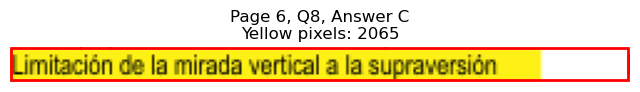

Page 6, Q8 - D: Detected box: x0=365.9, y0=581.7, x1=411.6, y1=594.4
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 377
Page 6, Q8, D: Yellow percentage: 0.0%


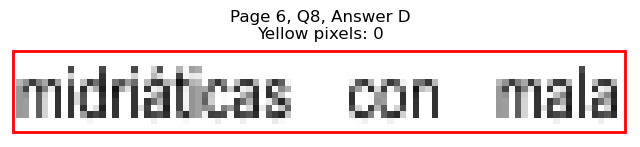

Page 6, Q8 - E: Detected box: x0=327.0, y0=606.9, x1=533.7, y1=619.6
Page 6, Q8, E: Yellow pixels: 0
Page 6, Q8, E: Total non-white pixels: 1046
Page 6, Q8, E: Yellow percentage: 0.0%


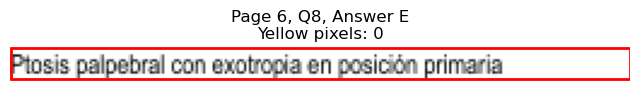


Page 6, Q8 - Selected Answer: C (based on yellow pixel count)




Page 6, Q9 - A: Detected box: x0=68.3, y0=644.9, x1=92.4, y1=657.5
Page 6, Q9, A: Yellow pixels: 75
Page 6, Q9, A: Total non-white pixels: 214
Page 6, Q9, A: Yellow percentage: 35.0%


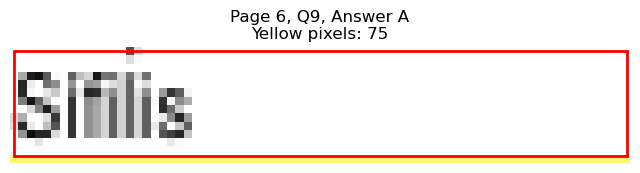

Page 6, Q9 - B: Detected box: x0=68.3, y0=657.5, x1=120.6, y1=670.1
Page 6, Q9, B: Yellow pixels: 1127
Page 6, Q9, B: Total non-white pixels: 1442
Page 6, Q9, B: Yellow percentage: 78.2%


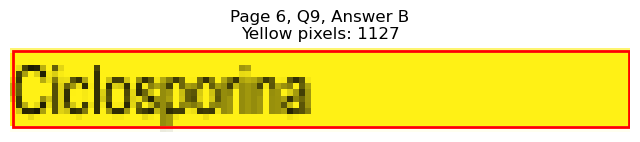

Page 6, Q9 - C: Detected box: x0=68.8, y0=670.1, x1=107.9, y1=682.7
Page 6, Q9, C: Yellow pixels: 0
Page 6, Q9, C: Total non-white pixels: 288
Page 6, Q9, C: Yellow percentage: 0.0%


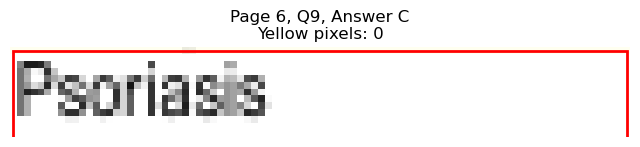

Page 6, Q9 - D: Detected box: x0=327.5, y0=644.9, x1=390.2, y1=657.5
Page 6, Q9, D: Yellow pixels: 0
Page 6, Q9, D: Total non-white pixels: 346
Page 6, Q9, D: Yellow percentage: 0.0%


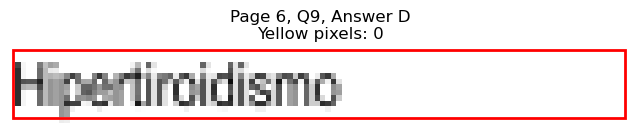

Page 6, Q9 - E: Detected box: x0=327.0, y0=657.5, x1=374.2, y1=670.1
Page 6, Q9, E: Yellow pixels: 0
Page 6, Q9, E: Total non-white pixels: 257
Page 6, Q9, E: Yellow percentage: 0.0%


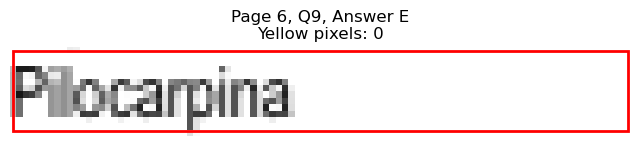


Page 6, Q9 - Selected Answer: B (based on yellow pixel count)




Page 6, Q10 - A: Detected box: x0=68.3, y0=733.2, x1=119.4, y1=745.8
Page 6, Q10, A: Yellow pixels: 0
Page 6, Q10, A: Total non-white pixels: 234
Page 6, Q10, A: Yellow percentage: 0.0%


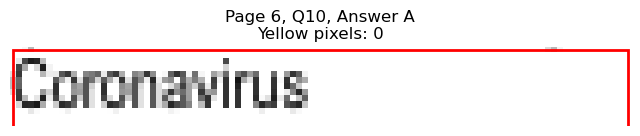

Page 6, Q10 - B: Detected box: x0=68.3, y0=745.8, x1=164.5, y1=758.4
Page 6, Q10, B: Yellow pixels: 0
Page 6, Q10, B: Total non-white pixels: 469
Page 6, Q10, B: Yellow percentage: 0.0%


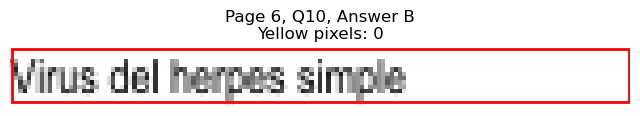

Page 6, Q10 - C: Detected box: x0=68.8, y0=758.5, x1=143.1, y1=771.2
Page 6, Q10, C: Yellow pixels: 0
Page 6, Q10, C: Total non-white pixels: 324
Page 6, Q10, C: Yellow percentage: 0.0%


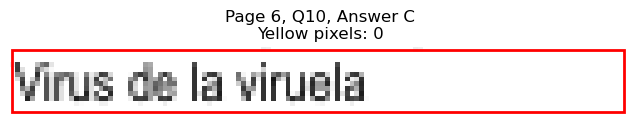

Page 6, Q10 - D: Detected box: x0=327.5, y0=733.2, x1=375.7, y1=745.8
Page 6, Q10, D: Yellow pixels: 1111
Page 6, Q10, D: Total non-white pixels: 1287
Page 6, Q10, D: Yellow percentage: 86.3%


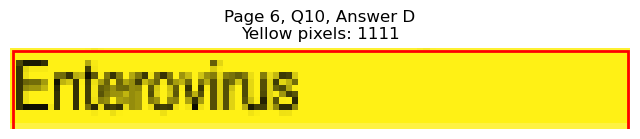

Page 6, Q10 - E: Detected box: x0=327.0, y0=745.8, x1=394.3, y1=758.4
Page 6, Q10, E: Yellow pixels: 118
Page 6, Q10, E: Total non-white pixels: 468
Page 6, Q10, E: Yellow percentage: 25.2%


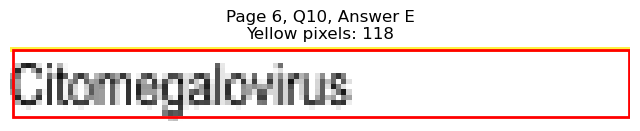


Page 6, Q10 - Selected Answer: D (based on yellow pixel count)





Page 7: Found 9 questions
Page 7, Q1 - A: Detected box: x0=56.6, y0=102.0, x1=65.2, y1=114.7
Page 7, Q1, A: Yellow pixels: 0
Page 7, Q1, A: Total non-white pixels: 122
Page 7, Q1, A: Yellow percentage: 0.0%


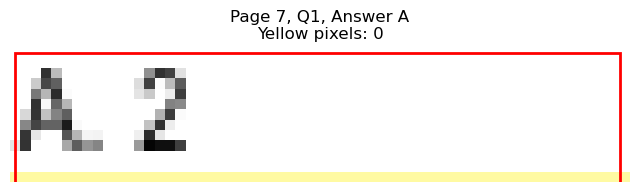

Page 7, Q1 - B: Detected box: x0=56.6, y0=114.6, x1=65.2, y1=127.3
Page 7, Q1, B: Yellow pixels: 662
Page 7, Q1, B: Total non-white pixels: 840
Page 7, Q1, B: Yellow percentage: 78.8%


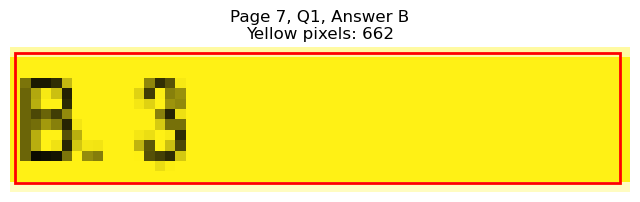

Page 7, Q1 - C: Detected box: x0=56.6, y0=127.2, x1=65.6, y1=139.9
Page 7, Q1, C: Yellow pixels: 0
Page 7, Q1, C: Total non-white pixels: 116
Page 7, Q1, C: Yellow percentage: 0.0%


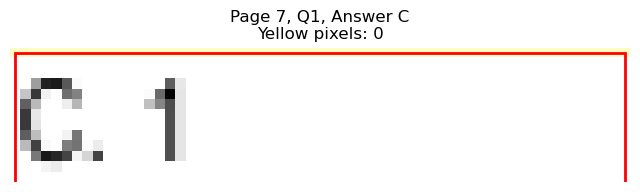

Page 7, Q1 - D: Detected box: x0=315.4, y0=102.0, x1=324.4, y1=114.7
Page 7, Q1, D: Yellow pixels: 0
Page 7, Q1, D: Total non-white pixels: 69
Page 7, Q1, D: Yellow percentage: 0.0%


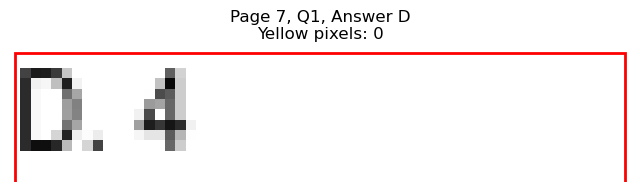

Page 7, Q1 - E: Detected box: x0=315.4, y0=114.6, x1=323.9, y1=127.3
Page 7, Q1, E: Yellow pixels: 0
Page 7, Q1, E: Total non-white pixels: 72
Page 7, Q1, E: Yellow percentage: 0.0%


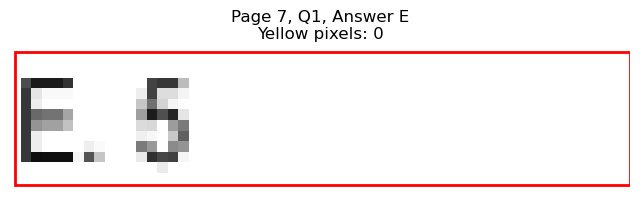


Page 7, Q1 - Selected Answer: B (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=68.3, y0=177.7, x1=106.0, y1=190.4
Page 7, Q2, A: Yellow pixels: 0
Page 7, Q2, A: Total non-white pixels: 199
Page 7, Q2, A: Yellow percentage: 0.0%


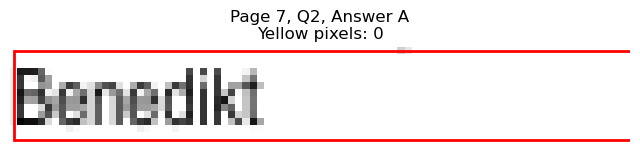

Page 7, Q2 - B: Detected box: x0=68.3, y0=190.3, x1=112.0, y1=203.0
Page 7, Q2, B: Yellow pixels: 0
Page 7, Q2, B: Total non-white pixels: 326
Page 7, Q2, B: Yellow percentage: 0.0%


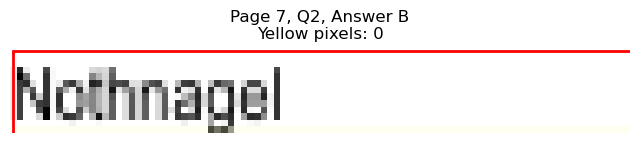

Page 7, Q2 - C: Detected box: x0=68.8, y0=202.9, x1=113.4, y1=215.6
Page 7, Q2, C: Yellow pixels: 1047
Page 7, Q2, C: Total non-white pixels: 1344
Page 7, Q2, C: Yellow percentage: 77.9%


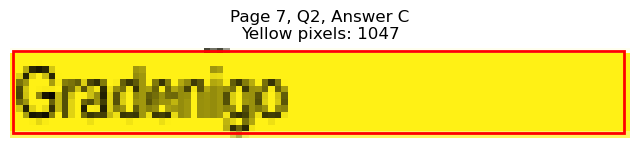

Page 7, Q2 - D: Detected box: x0=327.5, y0=177.7, x1=356.1, y1=190.4
Page 7, Q2, D: Yellow pixels: 0
Page 7, Q2, D: Total non-white pixels: 135
Page 7, Q2, D: Yellow percentage: 0.0%


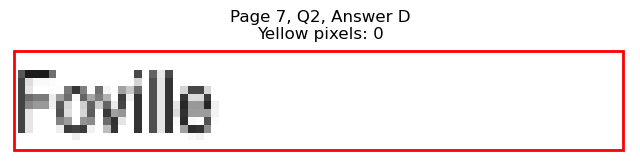

Page 7, Q2 - E: Detected box: x0=327.0, y0=190.3, x1=356.1, y1=203.0
Page 7, Q2, E: Yellow pixels: 0
Page 7, Q2, E: Total non-white pixels: 151
Page 7, Q2, E: Yellow percentage: 0.0%


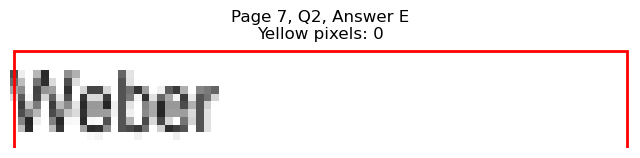


Page 7, Q2 - Selected Answer: C (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=68.3, y0=240.9, x1=79.3, y1=253.5
Page 7, Q3, A: Yellow pixels: 0
Page 7, Q3, A: Total non-white pixels: 36
Page 7, Q3, A: Yellow percentage: 0.0%


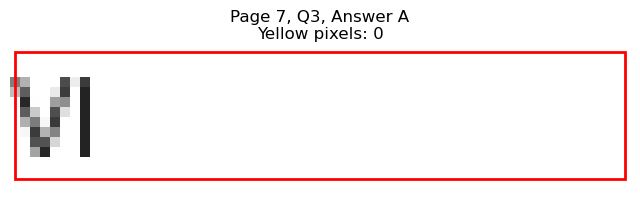

Page 7, Q3 - B: Detected box: x0=68.3, y0=253.5, x1=76.8, y1=266.1
Page 7, Q3, B: Yellow pixels: 0
Page 7, Q3, B: Total non-white pixels: 28
Page 7, Q3, B: Yellow percentage: 0.0%


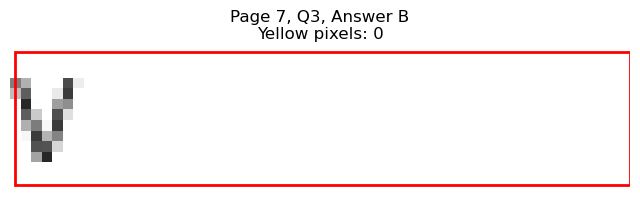

Page 7, Q3 - C: Detected box: x0=68.8, y0=266.1, x1=79.8, y1=278.7
Page 7, Q3, C: Yellow pixels: 0
Page 7, Q3, C: Total non-white pixels: 44
Page 7, Q3, C: Yellow percentage: 0.0%


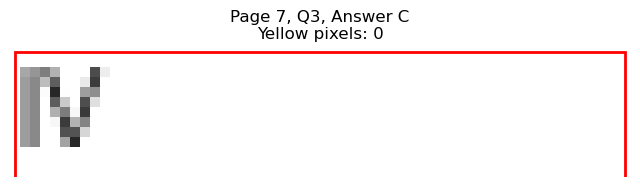

Page 7, Q3 - D: Detected box: x0=327.5, y0=240.9, x1=337.6, y1=253.5
Page 7, Q3, D: Yellow pixels: 753
Page 7, Q3, D: Total non-white pixels: 854
Page 7, Q3, D: Yellow percentage: 88.2%


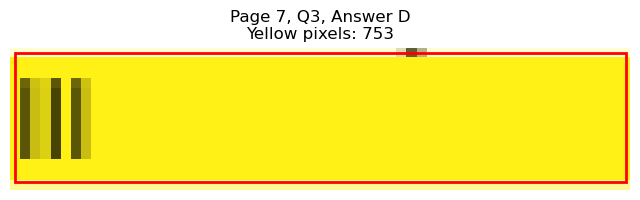

Page 7, Q3 - E: Detected box: x0=327.0, y0=253.5, x1=340.6, y1=266.1
Page 7, Q3, E: Yellow pixels: 64
Page 7, Q3, E: Total non-white pixels: 122
Page 7, Q3, E: Yellow percentage: 52.5%


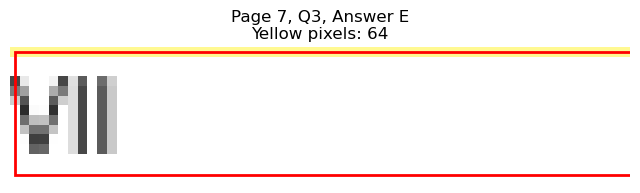


Page 7, Q3 - Selected Answer: D (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=68.3, y0=304.0, x1=96.5, y1=316.7
Page 7, Q4, A: Yellow pixels: 927
Page 7, Q4, A: Total non-white pixels: 1027
Page 7, Q4, A: Yellow percentage: 90.3%


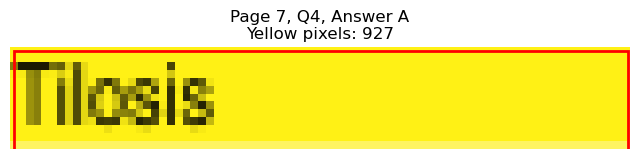

Page 7, Q4 - B: Detected box: x0=68.3, y0=316.6, x1=148.1, y1=329.3
Page 7, Q4, B: Yellow pixels: 131
Page 7, Q4, B: Total non-white pixels: 508
Page 7, Q4, B: Yellow percentage: 25.8%


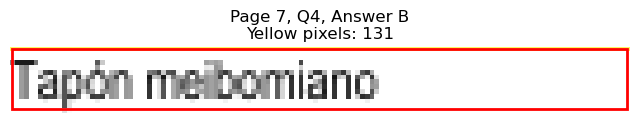

Page 7, Q4 - C: Detected box: x0=68.8, y0=329.2, x1=147.1, y1=341.9
Page 7, Q4, C: Yellow pixels: 0
Page 7, Q4, C: Total non-white pixels: 355
Page 7, Q4, C: Yellow percentage: 0.0%


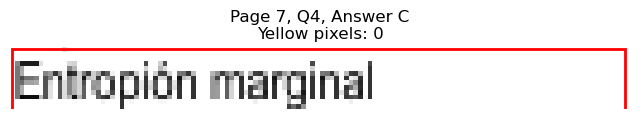

Page 7, Q4 - D: Detected box: x0=327.5, y0=304.0, x1=366.3, y1=316.7
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 203
Page 7, Q4, D: Yellow percentage: 0.0%


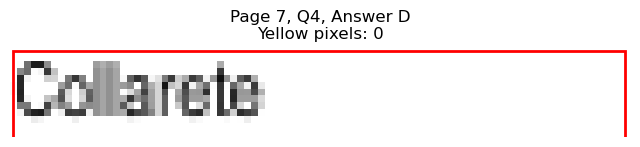

Page 7, Q4 - E: Detected box: x0=327.0, y0=316.6, x1=371.2, y1=329.3
Page 7, Q4, E: Yellow pixels: 0
Page 7, Q4, E: Total non-white pixels: 229
Page 7, Q4, E: Yellow percentage: 0.0%


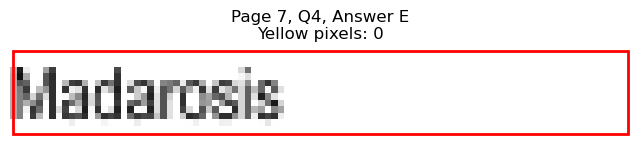


Page 7, Q4 - Selected Answer: A (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=136.0, y1=405.0
Page 7, Q5, A: Yellow pixels: 0
Page 7, Q5, A: Total non-white pixels: 368
Page 7, Q5, A: Yellow percentage: 0.0%


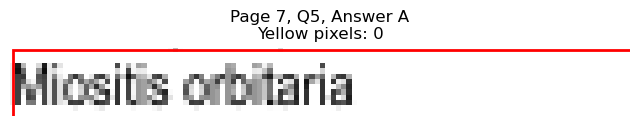

Page 7, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=174.1, y1=417.6
Page 7, Q5, B: Yellow pixels: 0
Page 7, Q5, B: Total non-white pixels: 525
Page 7, Q5, B: Yellow percentage: 0.0%


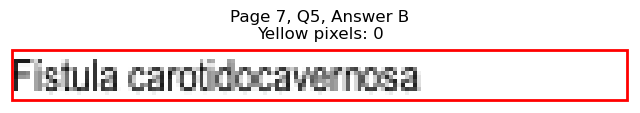

Page 7, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=103.5, y1=430.3
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 169
Page 7, Q5, C: Yellow percentage: 0.0%


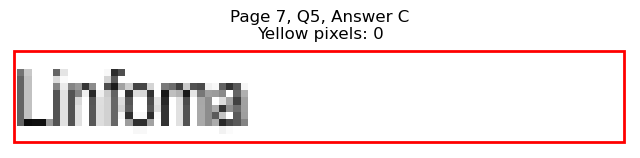

Page 7, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=414.4, y1=405.0
Page 7, Q5, D: Yellow pixels: 0
Page 7, Q5, D: Total non-white pixels: 574
Page 7, Q5, D: Yellow percentage: 0.0%


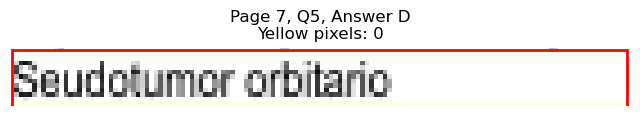

Page 7, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=452.5, y1=417.6
Page 7, Q5, E: Yellow pixels: 1849
Page 7, Q5, E: Total non-white pixels: 2464
Page 7, Q5, E: Yellow percentage: 75.0%


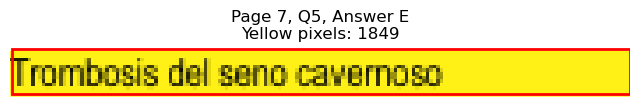


Page 7, Q5 - Selected Answer: E (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=68.3, y0=455.5, x1=129.1, y1=468.1
Page 7, Q6, A: Yellow pixels: 0
Page 7, Q6, A: Total non-white pixels: 284
Page 7, Q6, A: Yellow percentage: 0.0%


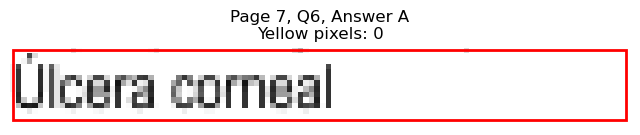

Page 7, Q6 - B: Detected box: x0=68.3, y0=468.1, x1=124.6, y1=480.7
Page 7, Q6, B: Yellow pixels: 0
Page 7, Q6, B: Total non-white pixels: 295
Page 7, Q6, B: Yellow percentage: 0.0%


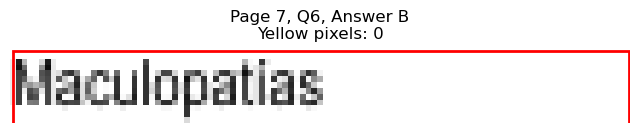

Page 7, Q6 - C: Detected box: x0=68.8, y0=480.8, x1=107.0, y1=493.4
Page 7, Q6, C: Yellow pixels: 920
Page 7, Q6, C: Total non-white pixels: 1260
Page 7, Q6, C: Yellow percentage: 73.0%


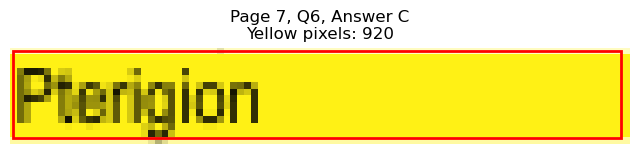

Page 7, Q6 - D: Detected box: x0=327.5, y0=455.5, x1=360.3, y1=468.1
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 173
Page 7, Q6, D: Yellow percentage: 0.0%


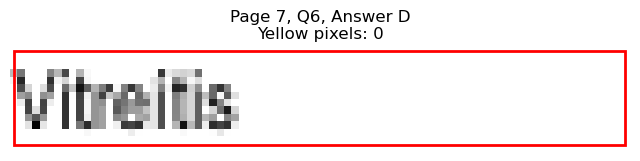

Page 7, Q6 - E: Detected box: x0=327.0, y0=468.1, x1=408.9, y1=480.7
Page 7, Q6, E: Yellow pixels: 0
Page 7, Q6, E: Total non-white pixels: 422
Page 7, Q6, E: Yellow percentage: 0.0%


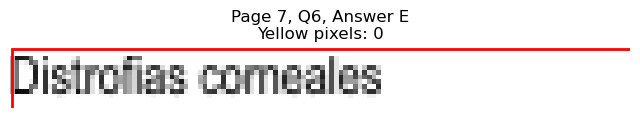


Page 7, Q6 - Selected Answer: C (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=68.3, y0=531.2, x1=136.0, y1=543.8
Page 7, Q7, A: Yellow pixels: 0
Page 7, Q7, A: Total non-white pixels: 290
Page 7, Q7, A: Yellow percentage: 0.0%


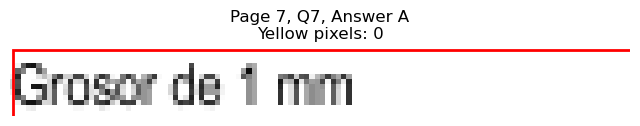

Page 7, Q7 - B: Detected box: x0=68.3, y0=543.8, x1=160.1, y1=556.4
Page 7, Q7, B: Yellow pixels: 0
Page 7, Q7, B: Total non-white pixels: 440
Page 7, Q7, B: Yellow percentage: 0.0%


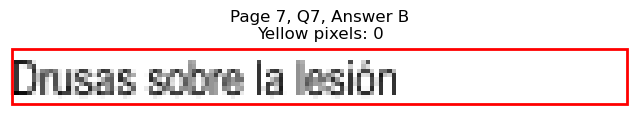

Page 7, Q7 - C: Detected box: x0=68.8, y0=556.5, x1=152.5, y1=569.2
Page 7, Q7, C: Yellow pixels: 1421
Page 7, Q7, C: Total non-white pixels: 1890
Page 7, Q7, C: Yellow percentage: 75.2%


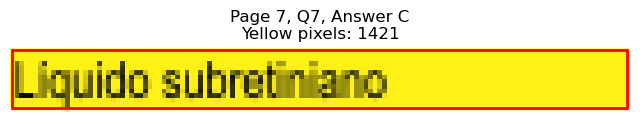

Page 7, Q7 - D: Detected box: x0=327.5, y0=531.2, x1=396.8, y1=543.8
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 372
Page 7, Q7, D: Yellow percentage: 0.0%


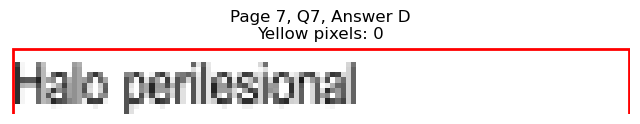

Page 7, Q7 - E: Detected box: x0=327.0, y0=543.8, x1=405.8, y1=556.4
Page 7, Q7, E: Yellow pixels: 0
Page 7, Q7, E: Total non-white pixels: 419
Page 7, Q7, E: Yellow percentage: 0.0%


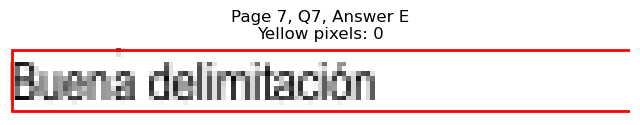


Page 7, Q7 - Selected Answer: C (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=68.3, y0=606.9, x1=126.0, y1=619.6
Page 7, Q8, A: Yellow pixels: 0
Page 7, Q8, A: Total non-white pixels: 297
Page 7, Q8, A: Yellow percentage: 0.0%


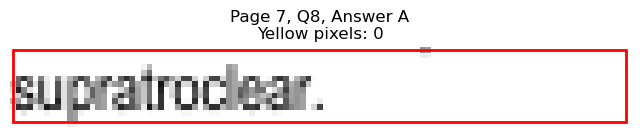

Page 7, Q8 - B: Detected box: x0=68.3, y0=619.6, x1=111.4, y1=632.3
Page 7, Q8, B: Yellow pixels: 978
Page 7, Q8, B: Total non-white pixels: 1316
Page 7, Q8, B: Yellow percentage: 74.3%


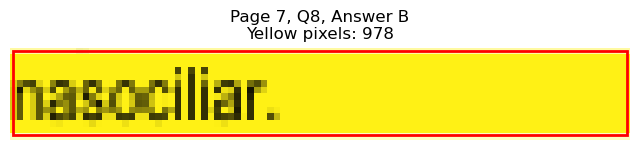

Page 7, Q8 - C: Detected box: x0=68.8, y0=632.2, x1=102.9, y1=644.9
Page 7, Q8, C: Yellow pixels: 0
Page 7, Q8, C: Total non-white pixels: 245
Page 7, Q8, C: Yellow percentage: 0.0%


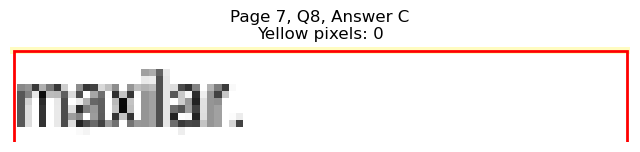

Page 7, Q8 - D: Detected box: x0=327.5, y0=606.9, x1=387.8, y1=619.6
Page 7, Q8, D: Yellow pixels: 0
Page 7, Q8, D: Total non-white pixels: 310
Page 7, Q8, D: Yellow percentage: 0.0%


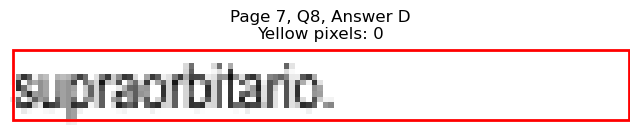

Page 7, Q8 - E: Detected box: x0=327.0, y0=619.6, x1=363.7, y1=632.3
Page 7, Q8, E: Yellow pixels: 0
Page 7, Q8, E: Total non-white pixels: 202
Page 7, Q8, E: Yellow percentage: 0.0%


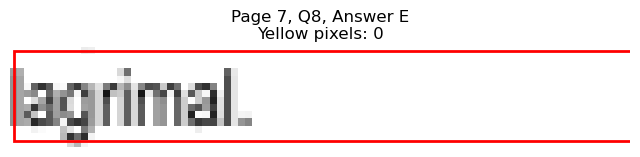


Page 7, Q8 - Selected Answer: B (based on yellow pixel count)




Page 7, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=164.1, y1=708.0
Page 7, Q9, A: Yellow pixels: 147
Page 7, Q9, A: Total non-white pixels: 773
Page 7, Q9, A: Yellow percentage: 19.0%


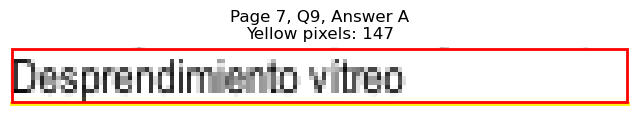

Page 7, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=122.4, y1=720.6
Page 7, Q9, B: Yellow pixels: 1138
Page 7, Q9, B: Total non-white pixels: 1470
Page 7, Q9, B: Yellow percentage: 77.4%


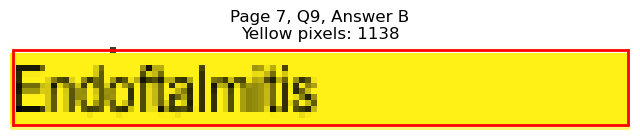

Page 7, Q9 - C: Detected box: x0=68.8, y0=720.6, x1=176.7, y1=733.2
Page 7, Q9, C: Yellow pixels: 159
Page 7, Q9, C: Total non-white pixels: 721
Page 7, Q9, C: Yellow percentage: 22.1%


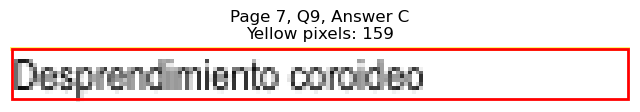

Page 7, Q9 - D: Detected box: x0=327.5, y0=695.4, x1=401.2, y1=708.0
Page 7, Q9, D: Yellow pixels: 0
Page 7, Q9, D: Total non-white pixels: 392
Page 7, Q9, D: Yellow percentage: 0.0%


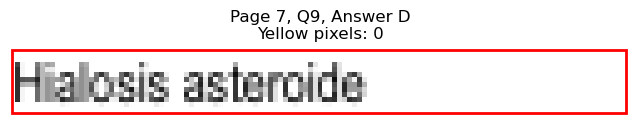

Page 7, Q9 - E: Detected box: x0=327.0, y0=708.0, x1=414.3, y1=720.6
Page 7, Q9, E: Yellow pixels: 0
Page 7, Q9, E: Total non-white pixels: 494
Page 7, Q9, E: Yellow percentage: 0.0%


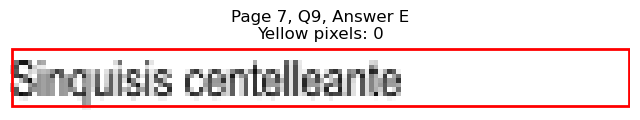


Page 7, Q9 - Selected Answer: B (based on yellow pixel count)





Page 8: Found 9 questions
Page 8, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=93.4, y1=114.7
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 120
Page 8, Q1, A: Yellow percentage: 0.0%


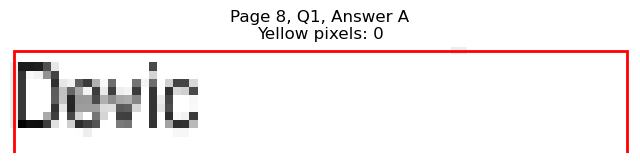

Page 8, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=103.5, y1=127.3
Page 8, Q1, B: Yellow pixels: 86
Page 8, Q1, B: Total non-white pixels: 279
Page 8, Q1, B: Yellow percentage: 30.8%


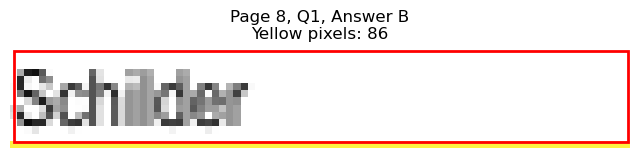

Page 8, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=100.3, y1=139.9
Page 8, Q1, C: Yellow pixels: 949
Page 8, Q1, C: Total non-white pixels: 1079
Page 8, Q1, C: Yellow percentage: 88.0%


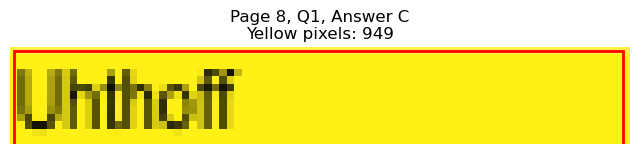

Page 8, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=359.1, y1=114.7
Page 8, Q1, D: Yellow pixels: 0
Page 8, Q1, D: Total non-white pixels: 156
Page 8, Q1, D: Yellow percentage: 0.0%


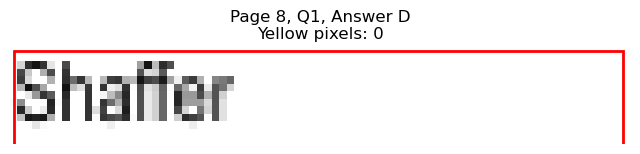

Page 8, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=349.6, y1=127.3
Page 8, Q1, E: Yellow pixels: 0
Page 8, Q1, E: Total non-white pixels: 115
Page 8, Q1, E: Yellow percentage: 0.0%


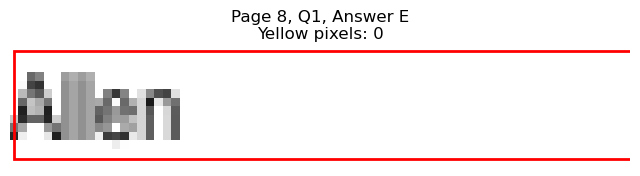


Page 8, Q1 - Selected Answer: C (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=68.3, y0=165.1, x1=290.0, y1=177.8
Page 8, Q2, A: Yellow pixels: 0
Page 8, Q2, A: Total non-white pixels: 1066
Page 8, Q2, A: Yellow percentage: 0.0%


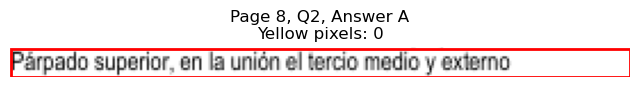

Page 8, Q2 - B: Detected box: x0=68.3, y0=177.7, x1=315.6, y1=190.4
Page 8, Q2, B: Yellow pixels: 0
Page 8, Q2, B: Total non-white pixels: 1175
Page 8, Q2, B: Yellow percentage: 0.0%


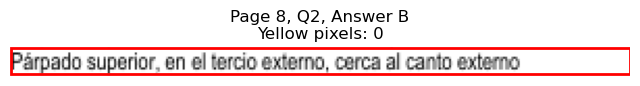

Page 8, Q2 - C: Detected box: x0=68.8, y0=190.3, x1=302.9, y1=203.0
Page 8, Q2, C: Yellow pixels: 0
Page 8, Q2, C: Total non-white pixels: 1108
Page 8, Q2, C: Yellow percentage: 0.0%


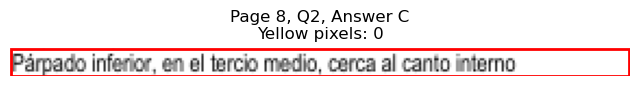

Page 8, Q2 - D: Detected box: x0=68.8, y0=202.9, x1=288.4, y1=215.6
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 1040
Page 8, Q2, D: Yellow percentage: 0.0%


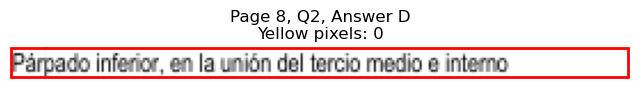

Page 8, Q2 - E: Detected box: x0=68.3, y0=215.7, x1=293.0, y1=228.3
Page 8, Q2, E: Yellow pixels: 2509
Page 8, Q2, E: Total non-white pixels: 3850
Page 8, Q2, E: Yellow percentage: 65.2%


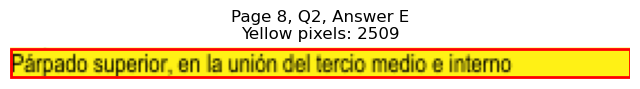


Page 8, Q2 - Selected Answer: E (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=105.9, y1=266.1
Page 8, Q3, A: Yellow pixels: 0
Page 8, Q3, A: Total non-white pixels: 172
Page 8, Q3, A: Yellow percentage: 0.0%


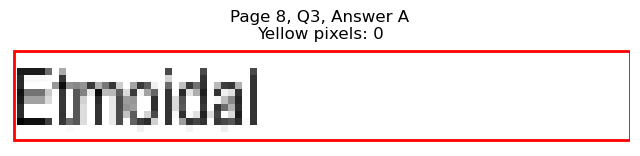

Page 8, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=105.4, y1=278.7
Page 8, Q3, B: Yellow pixels: 0
Page 8, Q3, B: Total non-white pixels: 180
Page 8, Q3, B: Yellow percentage: 0.0%


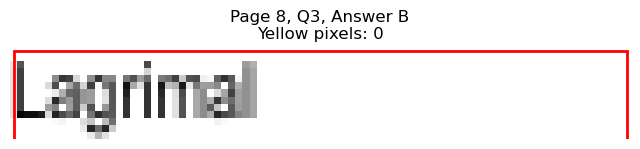

Page 8, Q3 - C: Detected box: x0=68.8, y0=379.7, x1=109.5, y1=392.4
Page 8, Q3, C: Yellow pixels: 782
Page 8, Q3, C: Total non-white pixels: 1288
Page 8, Q3, C: Yellow percentage: 60.7%


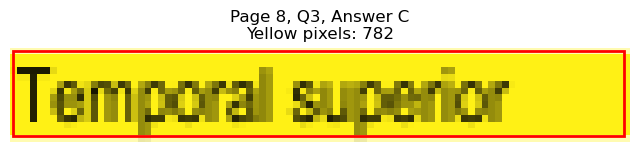

Page 8, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=359.1, y1=266.1
Page 8, Q3, D: Yellow pixels: 83
Page 8, Q3, D: Total non-white pixels: 242
Page 8, Q3, D: Yellow percentage: 34.3%


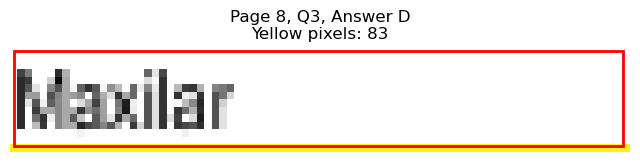

Page 8, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=369.3, y1=278.7
Page 8, Q3, E: Yellow pixels: 1043
Page 8, Q3, E: Total non-white pixels: 1209
Page 8, Q3, E: Yellow percentage: 86.3%


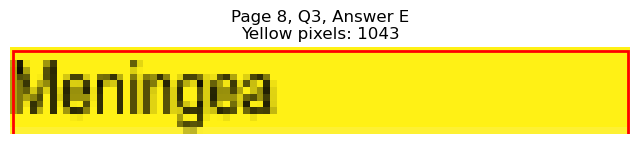


Page 8, Q3 - Selected Answer: E (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=68.3, y0=354.5, x1=102.9, y1=367.2
Page 8, Q4, A: Yellow pixels: 0
Page 8, Q4, A: Total non-white pixels: 165
Page 8, Q4, A: Yellow percentage: 0.0%


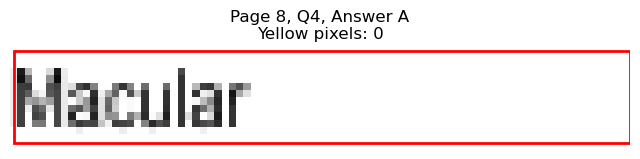

Page 8, Q4 - B: Detected box: x0=68.3, y0=367.1, x1=124.0, y1=379.8
Page 8, Q4, B: Yellow pixels: 0
Page 8, Q4, B: Total non-white pixels: 381
Page 8, Q4, B: Yellow percentage: 0.0%


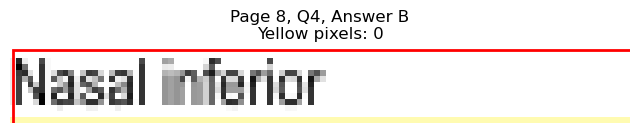

Page 8, Q4 - C: Detected box: x0=68.8, y0=379.7, x1=144.5, y1=392.4
Page 8, Q4, C: Yellow pixels: 1202
Page 8, Q4, C: Total non-white pixels: 1778
Page 8, Q4, C: Yellow percentage: 67.6%


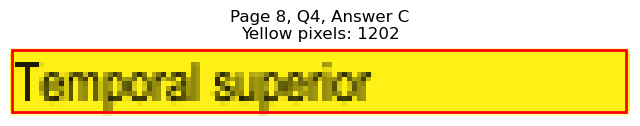

Page 8, Q4 - D: Detected box: x0=327.5, y0=354.5, x1=373.1, y1=367.2
Page 8, Q4, D: Yellow pixels: 0
Page 8, Q4, D: Total non-white pixels: 236
Page 8, Q4, D: Yellow percentage: 0.0%


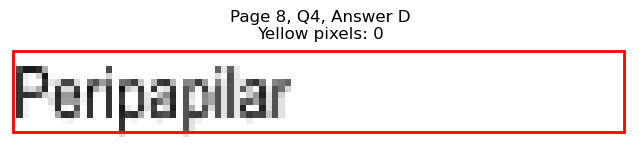

Page 8, Q4 - E: Detected box: x0=327.0, y0=367.1, x1=397.7, y1=379.8
Page 8, Q4, E: Yellow pixels: 0
Page 8, Q4, E: Total non-white pixels: 363
Page 8, Q4, E: Yellow percentage: 0.0%


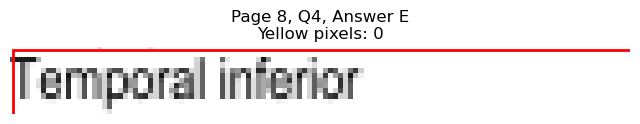


Page 8, Q4 - Selected Answer: C (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=68.3, y0=417.6, x1=177.1, y1=430.3
Page 8, Q5, A: Yellow pixels: 0
Page 8, Q5, A: Total non-white pixels: 516
Page 8, Q5, A: Yellow percentage: 0.0%


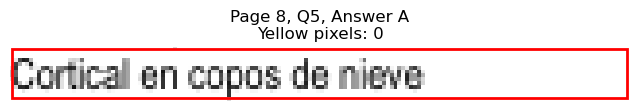

Page 8, Q5 - B: Detected box: x0=68.3, y0=430.2, x1=123.5, y1=442.9
Page 8, Q5, B: Yellow pixels: 0
Page 8, Q5, B: Total non-white pixels: 315
Page 8, Q5, B: Yellow percentage: 0.0%


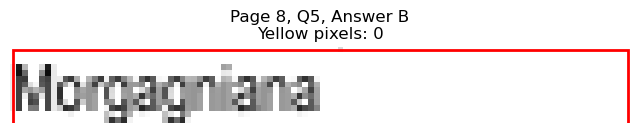

Page 8, Q5 - C: Detected box: x0=68.8, y0=442.8, x1=148.0, y1=455.5
Page 8, Q5, C: Yellow pixels: 0
Page 8, Q5, C: Total non-white pixels: 430
Page 8, Q5, C: Yellow percentage: 0.0%


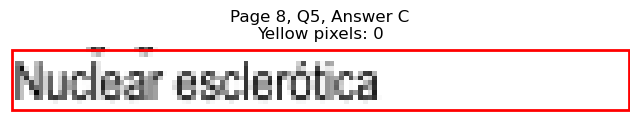

Page 8, Q5 - D: Detected box: x0=327.5, y0=417.6, x1=417.8, y1=430.3
Page 8, Q5, D: Yellow pixels: 1336
Page 8, Q5, D: Total non-white pixels: 1974
Page 8, Q5, D: Yellow percentage: 67.7%


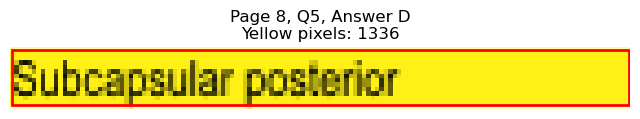

Page 8, Q5 - E: Detected box: x0=327.0, y0=430.2, x1=379.7, y1=442.9
Page 8, Q5, E: Yellow pixels: 0
Page 8, Q5, E: Total non-white pixels: 383
Page 8, Q5, E: Yellow percentage: 0.0%


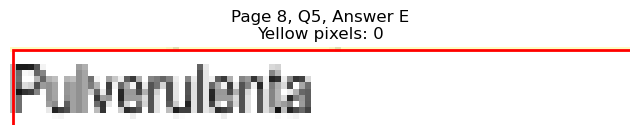


Page 8, Q5 - Selected Answer: D (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=68.3, y0=480.8, x1=100.9, y1=493.4
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 170
Page 8, Q6, A: Yellow percentage: 0.0%


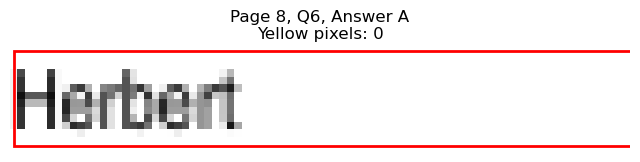

Page 8, Q6 - B: Detected box: x0=68.3, y0=493.4, x1=88.8, y1=506.0
Page 8, Q6, B: Yellow pixels: 0
Page 8, Q6, B: Total non-white pixels: 111
Page 8, Q6, B: Yellow percentage: 0.0%


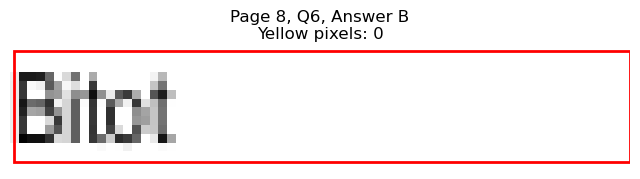

Page 8, Q6 - C: Detected box: x0=68.8, y0=506.0, x1=101.9, y1=518.6
Page 8, Q6, C: Yellow pixels: 0
Page 8, Q6, C: Total non-white pixels: 170
Page 8, Q6, C: Yellow percentage: 0.0%


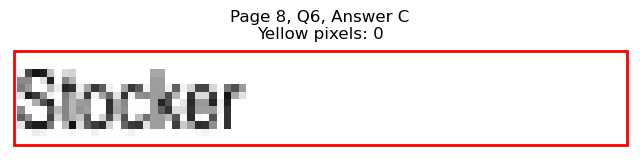

Page 8, Q6 - D: Detected box: x0=327.5, y0=480.8, x1=343.6, y1=493.4
Page 8, Q6, D: Yellow pixels: 751
Page 8, Q6, D: Total non-white pixels: 938
Page 8, Q6, D: Yellow percentage: 80.1%


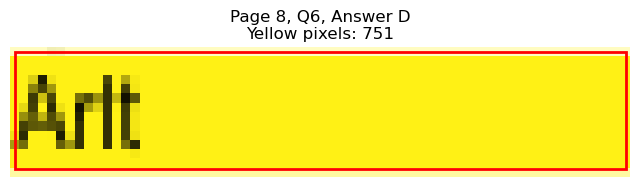

Page 8, Q6 - E: Detected box: x0=327.0, y0=493.4, x1=364.1, y1=506.0
Page 8, Q6, E: Yellow pixels: 0
Page 8, Q6, E: Total non-white pixels: 279
Page 8, Q6, E: Yellow percentage: 0.0%


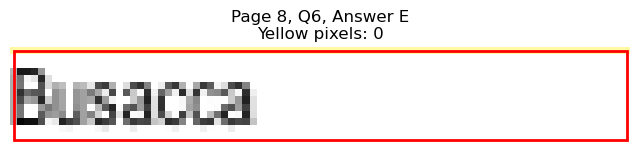


Page 8, Q6 - Selected Answer: D (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=109.6, y1=556.4
Page 8, Q7, A: Yellow pixels: 0
Page 8, Q7, A: Total non-white pixels: 200
Page 8, Q7, A: Yellow percentage: 0.0%


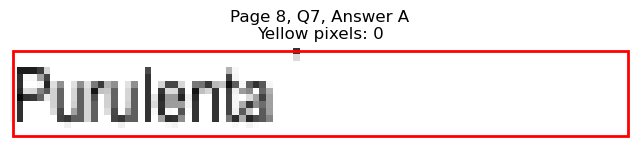

Page 8, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=123.6, y1=569.2
Page 8, Q7, B: Yellow pixels: 0
Page 8, Q7, B: Total non-white pixels: 274
Page 8, Q7, B: Yellow percentage: 0.0%


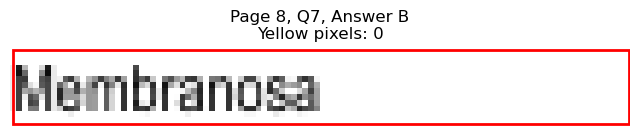

Page 8, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=131.1, y1=581.8
Page 8, Q7, C: Yellow pixels: 0
Page 8, Q7, C: Total non-white pixels: 333
Page 8, Q7, C: Yellow percentage: 0.0%


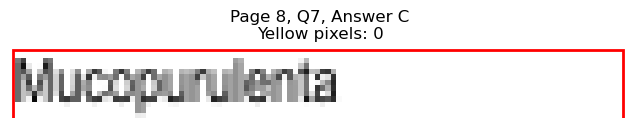

Page 8, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=360.3, y1=556.4
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 162
Page 8, Q7, D: Yellow percentage: 0.0%


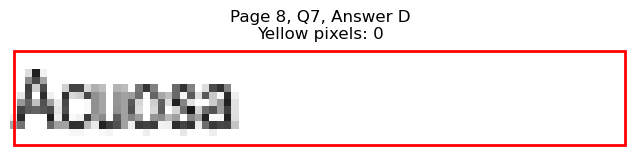

Page 8, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=363.7, y1=569.2
Page 8, Q7, E: Yellow pixels: 981
Page 8, Q7, E: Total non-white pixels: 1218
Page 8, Q7, E: Yellow percentage: 80.5%


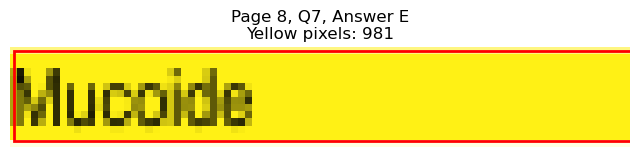


Page 8, Q7 - Selected Answer: E (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=68.3, y0=644.9, x1=139.5, y1=657.5
Page 8, Q8, A: Yellow pixels: 1288
Page 8, Q8, A: Total non-white pixels: 1708
Page 8, Q8, A: Yellow percentage: 75.4%


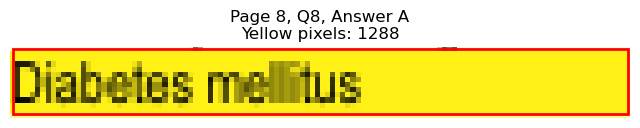

Page 8, Q8 - B: Detected box: x0=68.3, y0=657.5, x1=145.6, y1=670.1
Page 8, Q8, B: Yellow pixels: 128
Page 8, Q8, B: Total non-white pixels: 525
Page 8, Q8, B: Yellow percentage: 24.4%


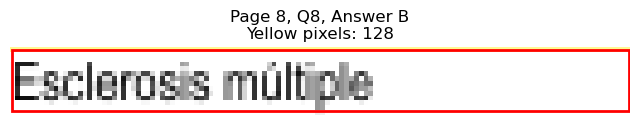

Page 8, Q8 - C: Detected box: x0=68.8, y0=670.1, x1=182.2, y1=682.7
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 581
Page 8, Q8, C: Yellow percentage: 0.0%


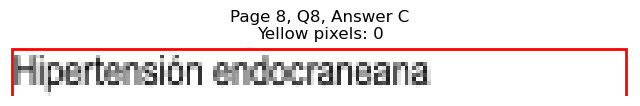

Page 8, Q8 - D: Detected box: x0=327.5, y0=644.9, x1=416.3, y1=657.5
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 448
Page 8, Q8, D: Yellow percentage: 0.0%


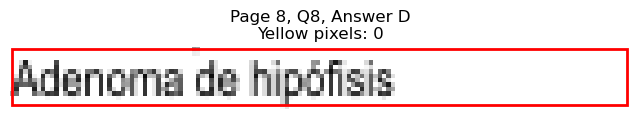

Page 8, Q8 - E: Detected box: x0=327.0, y0=657.5, x1=404.3, y1=670.1
Page 8, Q8, E: Yellow pixels: 0
Page 8, Q8, E: Total non-white pixels: 424
Page 8, Q8, E: Yellow percentage: 0.0%


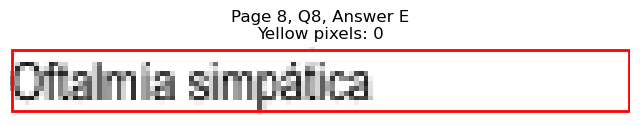


Page 8, Q8 - Selected Answer: A (based on yellow pixel count)




Page 8, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=176.2, y1=708.0
Page 8, Q9, A: Yellow pixels: 0
Page 8, Q9, A: Total non-white pixels: 532
Page 8, Q9, A: Yellow percentage: 0.0%


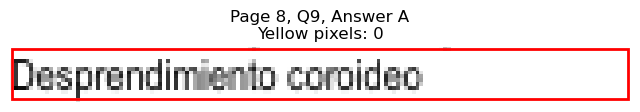

Page 8, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=157.6, y1=720.6
Page 8, Q9, B: Yellow pixels: 0
Page 8, Q9, B: Total non-white pixels: 440
Page 8, Q9, B: Yellow percentage: 0.0%


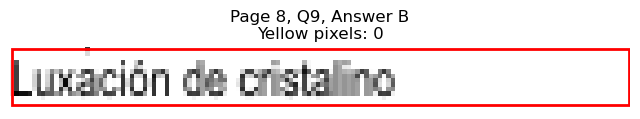

Page 8, Q9 - C: Detected box: x0=68.8, y0=720.6, x1=118.5, y1=733.2
Page 8, Q9, C: Yellow pixels: 0
Page 8, Q9, C: Total non-white pixels: 281
Page 8, Q9, C: Yellow percentage: 0.0%


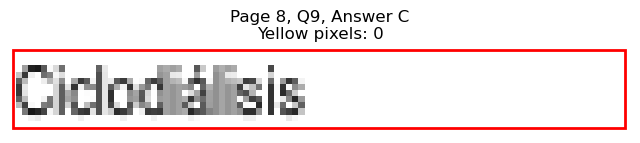

Page 8, Q9 - D: Detected box: x0=327.5, y0=695.4, x1=400.3, y1=708.0
Page 8, Q9, D: Yellow pixels: 124
Page 8, Q9, D: Total non-white pixels: 623
Page 8, Q9, D: Yellow percentage: 19.9%


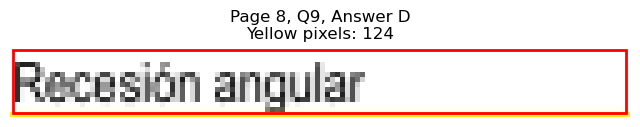

Page 8, Q9 - E: Detected box: x0=327.0, y0=708.0, x1=422.8, y1=720.6
Page 8, Q9, E: Yellow pixels: 1516
Page 8, Q9, E: Total non-white pixels: 2044
Page 8, Q9, E: Yellow percentage: 74.2%


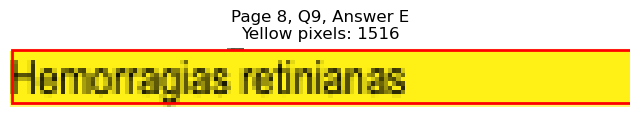


Page 8, Q9 - Selected Answer: E (based on yellow pixel count)





Page 9: Found 8 questions
Page 9, Q1 - A: Detected box: x0=56.6, y0=114.6, x1=65.2, y1=127.3
Page 9, Q1, A: Yellow pixels: 0
Page 9, Q1, A: Total non-white pixels: 65
Page 9, Q1, A: Yellow percentage: 0.0%


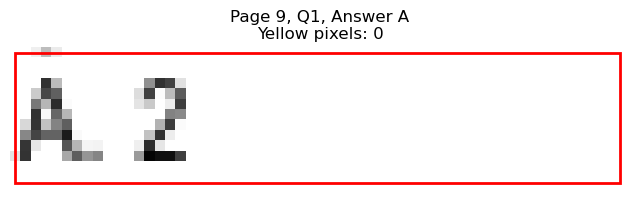

Page 9, Q1 - B: Detected box: x0=56.6, y0=127.2, x1=65.2, y1=139.9
Page 9, Q1, B: Yellow pixels: 0
Page 9, Q1, B: Total non-white pixels: 60
Page 9, Q1, B: Yellow percentage: 0.0%


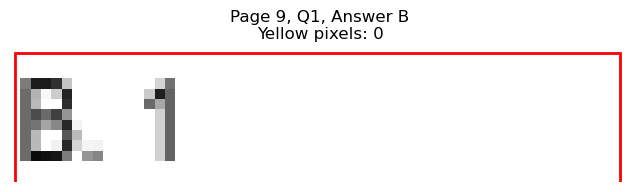

Page 9, Q1 - C: Detected box: x0=56.6, y0=139.9, x1=65.6, y1=152.6
Page 9, Q1, C: Yellow pixels: 734
Page 9, Q1, C: Total non-white pixels: 840
Page 9, Q1, C: Yellow percentage: 87.4%


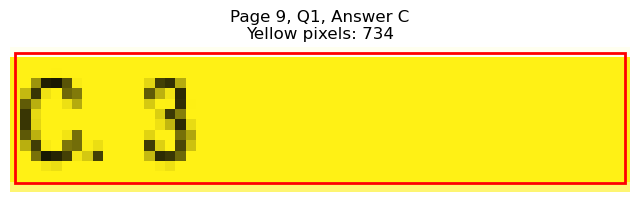

Page 9, Q1 - D: Detected box: x0=315.4, y0=114.6, x1=324.4, y1=127.3
Page 9, Q1, D: Yellow pixels: 0
Page 9, Q1, D: Total non-white pixels: 71
Page 9, Q1, D: Yellow percentage: 0.0%


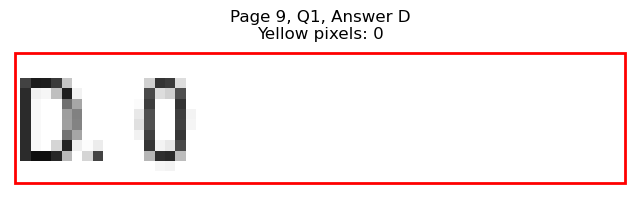

Page 9, Q1 - E: Detected box: x0=315.4, y0=127.2, x1=323.9, y1=139.9
Page 9, Q1, E: Yellow pixels: 0
Page 9, Q1, E: Total non-white pixels: 63
Page 9, Q1, E: Yellow percentage: 0.0%


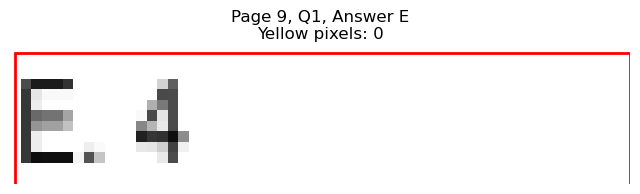


Page 9, Q1 - Selected Answer: C (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=68.3, y0=228.3, x1=219.3, y1=240.9
Page 9, Q2, A: Yellow pixels: 0
Page 9, Q2, A: Total non-white pixels: 739
Page 9, Q2, A: Yellow percentage: 0.0%


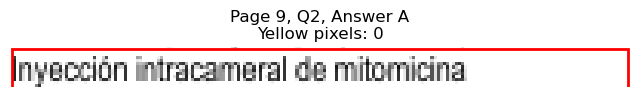

Page 9, Q2 - B: Detected box: x0=68.3, y0=240.9, x1=181.7, y1=253.5
Page 9, Q2, B: Yellow pixels: 0
Page 9, Q2, B: Total non-white pixels: 570
Page 9, Q2, B: Yellow percentage: 0.0%


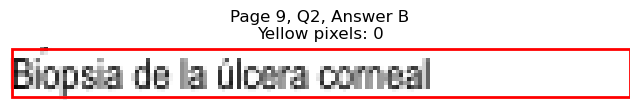

Page 9, Q2 - C: Detected box: x0=68.8, y0=253.5, x1=220.4, y1=266.1
Page 9, Q2, C: Yellow pixels: 0
Page 9, Q2, C: Total non-white pixels: 755
Page 9, Q2, C: Yellow percentage: 0.0%


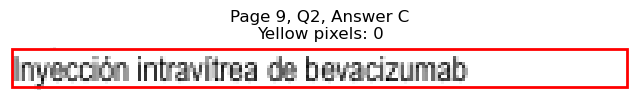

Page 9, Q2 - D: Detected box: x0=327.5, y0=228.3, x1=415.3, y1=240.9
Page 9, Q2, D: Yellow pixels: 1484
Page 9, Q2, D: Total non-white pixels: 1807
Page 9, Q2, D: Yellow percentage: 82.1%


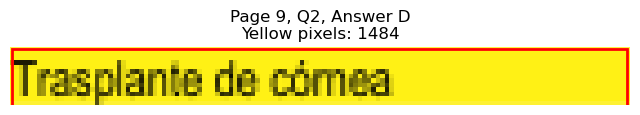

Page 9, Q2 - E: Detected box: x0=327.0, y0=240.9, x1=509.6, y1=253.5
Page 9, Q2, E: Yellow pixels: 212
Page 9, Q2, E: Total non-white pixels: 1155
Page 9, Q2, E: Yellow percentage: 18.4%


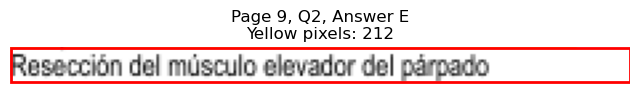


Page 9, Q2 - Selected Answer: D (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=68.3, y0=316.6, x1=173.7, y1=329.3
Page 9, Q3, A: Yellow pixels: 0
Page 9, Q3, A: Total non-white pixels: 517
Page 9, Q3, A: Yellow percentage: 0.0%


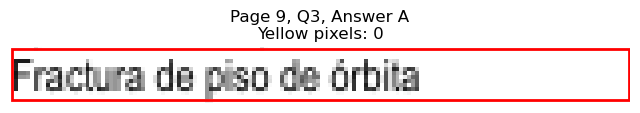

Page 9, Q3 - B: Detected box: x0=68.3, y0=329.2, x1=145.6, y1=341.9
Page 9, Q3, B: Yellow pixels: 0
Page 9, Q3, B: Total non-white pixels: 406
Page 9, Q3, B: Yellow percentage: 0.0%


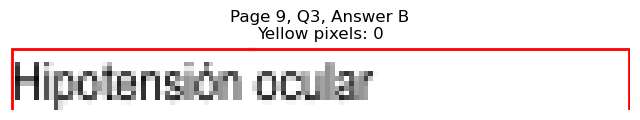

Page 9, Q3 - C: Detected box: x0=68.8, y0=341.9, x1=161.5, y1=354.6
Page 9, Q3, C: Yellow pixels: 1524
Page 9, Q3, C: Total non-white pixels: 2016
Page 9, Q3, C: Yellow percentage: 75.6%


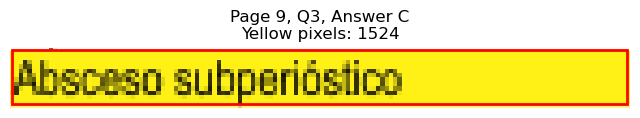

Page 9, Q3 - D: Detected box: x0=327.5, y0=316.6, x1=394.3, y1=329.3
Page 9, Q3, D: Yellow pixels: 0
Page 9, Q3, D: Total non-white pixels: 336
Page 9, Q3, D: Yellow percentage: 0.0%


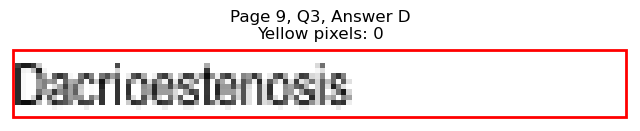

Page 9, Q3 - E: Detected box: x0=327.0, y0=329.2, x1=416.8, y1=341.9
Page 9, Q3, E: Yellow pixels: 0
Page 9, Q3, E: Total non-white pixels: 470
Page 9, Q3, E: Yellow percentage: 0.0%


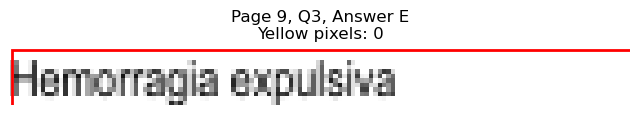


Page 9, Q3 - Selected Answer: C (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=68.3, y0=379.7, x1=120.5, y1=392.4
Page 9, Q4, A: Yellow pixels: 103
Page 9, Q4, A: Total non-white pixels: 380
Page 9, Q4, A: Yellow percentage: 27.1%


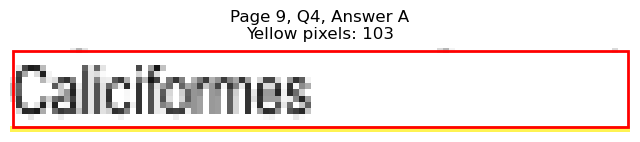

Page 9, Q4 - B: Detected box: x0=68.3, y0=392.3, x1=151.1, y1=405.0
Page 9, Q4, B: Yellow pixels: 1421
Page 9, Q4, B: Total non-white pixels: 1742
Page 9, Q4, B: Yellow percentage: 81.6%


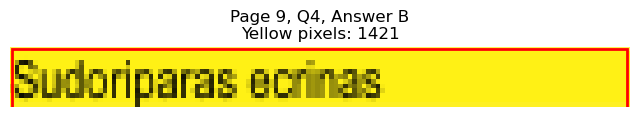

Page 9, Q4 - C: Detected box: x0=68.8, y0=404.9, x1=111.4, y1=417.6
Page 9, Q4, C: Yellow pixels: 93
Page 9, Q4, C: Total non-white pixels: 321
Page 9, Q4, C: Yellow percentage: 29.0%


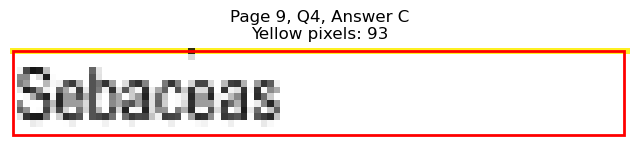

Page 9, Q4 - D: Detected box: x0=327.5, y0=379.7, x1=371.2, y1=392.4
Page 9, Q4, D: Yellow pixels: 0
Page 9, Q4, D: Total non-white pixels: 212
Page 9, Q4, D: Yellow percentage: 0.0%


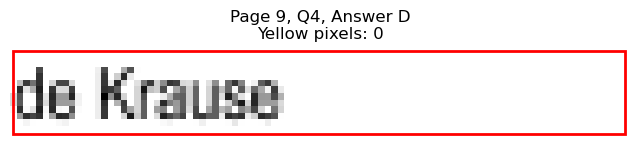

Page 9, Q4 - E: Detected box: x0=327.0, y0=392.3, x1=375.2, y1=405.0
Page 9, Q4, E: Yellow pixels: 0
Page 9, Q4, E: Total non-white pixels: 248
Page 9, Q4, E: Yellow percentage: 0.0%


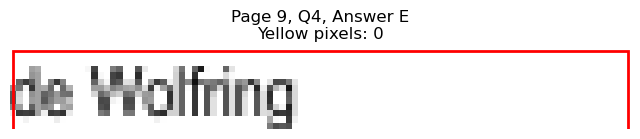


Page 9, Q4 - Selected Answer: B (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=68.3, y0=468.1, x1=119.4, y1=480.7
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 284
Page 9, Q5, A: Yellow percentage: 0.0%


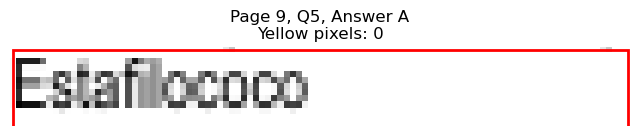

Page 9, Q5 - B: Detected box: x0=68.3, y0=480.8, x1=110.5, y1=493.4
Page 9, Q5, B: Yellow pixels: 966
Page 9, Q5, B: Total non-white pixels: 1302
Page 9, Q5, B: Yellow percentage: 74.2%


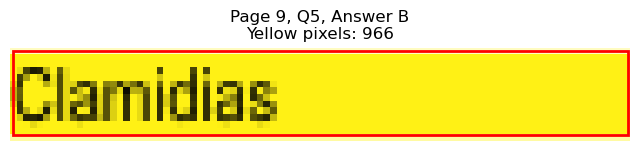

Page 9, Q5 - C: Detected box: x0=68.8, y0=493.4, x1=112.5, y1=506.0
Page 9, Q5, C: Yellow pixels: 0
Page 9, Q5, C: Total non-white pixels: 308
Page 9, Q5, C: Yellow percentage: 0.0%


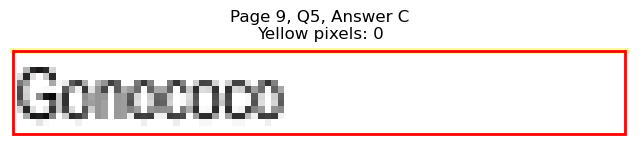

Page 9, Q5 - D: Detected box: x0=327.5, y0=468.1, x1=382.7, y1=480.7
Page 9, Q5, D: Yellow pixels: 0
Page 9, Q5, D: Total non-white pixels: 296
Page 9, Q5, D: Yellow percentage: 0.0%


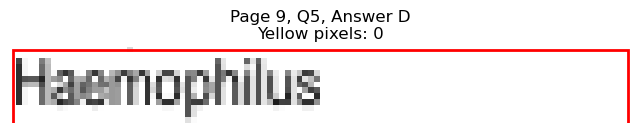

Page 9, Q5 - E: Detected box: x0=327.0, y0=480.8, x1=374.7, y1=493.4
Page 9, Q5, E: Yellow pixels: 0
Page 9, Q5, E: Total non-white pixels: 239
Page 9, Q5, E: Yellow percentage: 0.0%


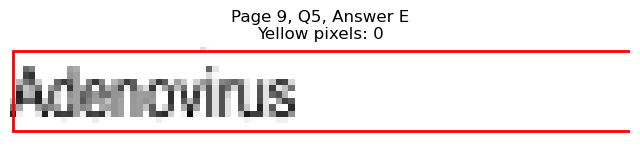


Page 9, Q5 - Selected Answer: B (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=68.3, y0=556.5, x1=90.9, y1=569.2
Page 9, Q6, A: Yellow pixels: 0
Page 9, Q6, A: Total non-white pixels: 127
Page 9, Q6, A: Yellow percentage: 0.0%


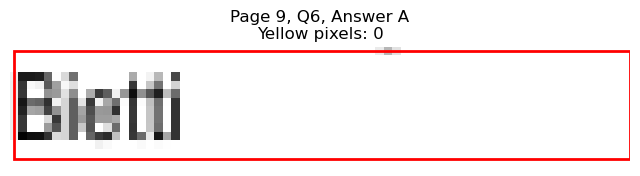

Page 9, Q6 - B: Detected box: x0=68.3, y0=569.1, x1=89.9, y1=581.8
Page 9, Q6, B: Yellow pixels: 0
Page 9, Q6, B: Total non-white pixels: 111
Page 9, Q6, B: Yellow percentage: 0.0%


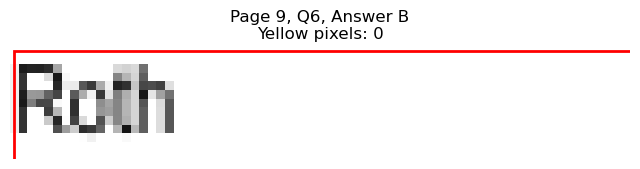

Page 9, Q6 - C: Detected box: x0=68.8, y0=581.7, x1=108.4, y1=594.4
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 214
Page 9, Q6, C: Yellow percentage: 0.0%


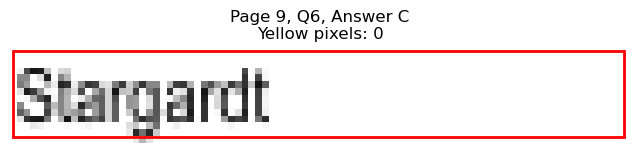

Page 9, Q6 - D: Detected box: x0=327.5, y0=556.5, x1=359.6, y1=569.2
Page 9, Q6, D: Yellow pixels: 83
Page 9, Q6, D: Total non-white pixels: 259
Page 9, Q6, D: Yellow percentage: 32.0%


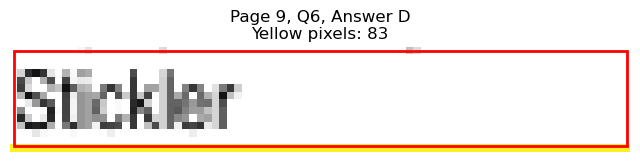

Page 9, Q6 - E: Detected box: x0=327.0, y0=569.1, x1=368.2, y1=581.8
Page 9, Q6, E: Yellow pixels: 1026
Page 9, Q6, E: Total non-white pixels: 1196
Page 9, Q6, E: Yellow percentage: 85.8%


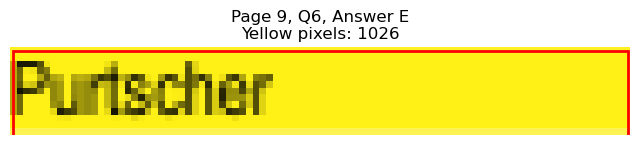


Page 9, Q6 - Selected Answer: E (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=68.3, y0=619.6, x1=119.4, y1=632.3
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 271
Page 9, Q7, A: Yellow percentage: 0.0%


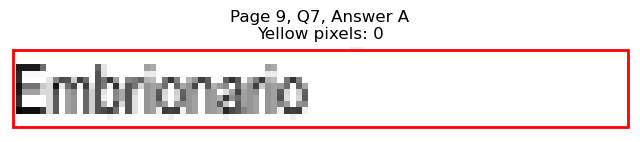

Page 9, Q7 - B: Detected box: x0=68.3, y0=632.2, x1=106.5, y1=644.9
Page 9, Q7, B: Yellow pixels: 0
Page 9, Q7, B: Total non-white pixels: 206
Page 9, Q7, B: Yellow percentage: 0.0%


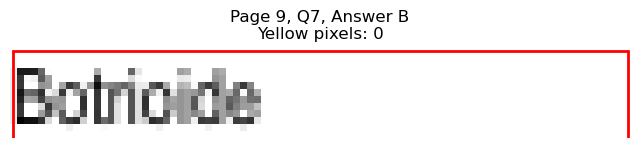

Page 9, Q7 - C: Detected box: x0=68.8, y0=644.9, x1=112.5, y1=657.5
Page 9, Q7, C: Yellow pixels: 0
Page 9, Q7, C: Total non-white pixels: 215
Page 9, Q7, C: Yellow percentage: 0.0%


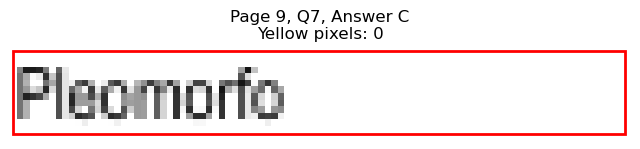

Page 9, Q7 - D: Detected box: x0=327.5, y0=619.6, x1=362.7, y1=632.3
Page 9, Q7, D: Yellow pixels: 889
Page 9, Q7, D: Total non-white pixels: 1204
Page 9, Q7, D: Yellow percentage: 73.8%


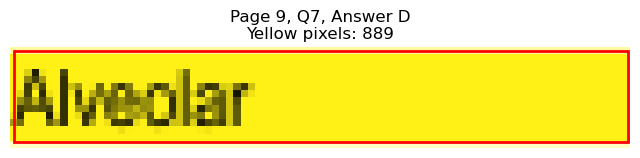

Page 9, Q7 - E: Detected box: x0=327.0, y0=632.2, x1=365.7, y1=644.9
Page 9, Q7, E: Yellow pixels: 0
Page 9, Q7, E: Total non-white pixels: 290
Page 9, Q7, E: Yellow percentage: 0.0%


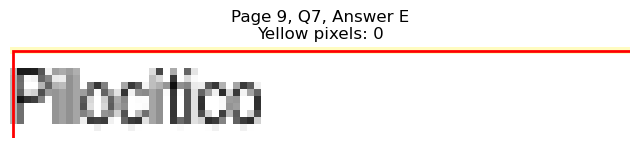


Page 9, Q7 - Selected Answer: D (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=68.3, y0=682.7, x1=168.1, y1=695.3
Page 9, Q8, A: Yellow pixels: 0
Page 9, Q8, A: Total non-white pixels: 517
Page 9, Q8, A: Yellow percentage: 0.0%


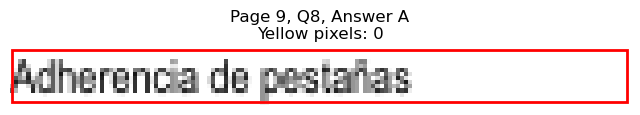

Page 9, Q8 - B: Detected box: x0=68.3, y0=695.4, x1=191.1, y1=708.0
Page 9, Q8, B: Yellow pixels: 1778
Page 9, Q8, B: Total non-white pixels: 2265
Page 9, Q8, B: Yellow percentage: 78.5%


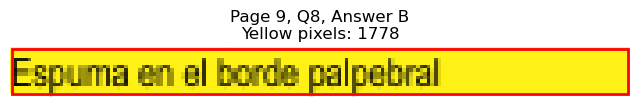

Page 9, Q8 - C: Detected box: x0=68.8, y0=708.0, x1=194.7, y1=720.6
Page 9, Q8, C: Yellow pixels: 174
Page 9, Q8, C: Total non-white pixels: 800
Page 9, Q8, C: Yellow percentage: 21.8%


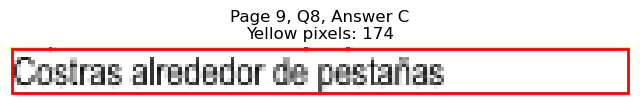

Page 9, Q8 - D: Detected box: x0=327.5, y0=682.7, x1=371.7, y1=695.3
Page 9, Q8, D: Yellow pixels: 0
Page 9, Q8, D: Total non-white pixels: 238
Page 9, Q8, D: Yellow percentage: 0.0%


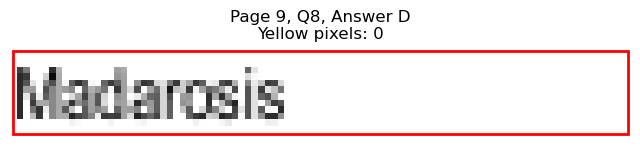

Page 9, Q8 - E: Detected box: x0=327.0, y0=695.4, x1=410.3, y1=708.0
Page 9, Q8, E: Yellow pixels: 0
Page 9, Q8, E: Total non-white pixels: 437
Page 9, Q8, E: Yellow percentage: 0.0%


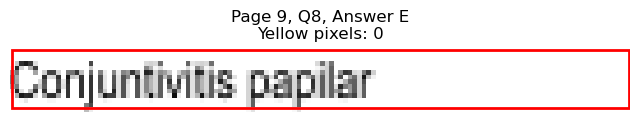


Page 9, Q8 - Selected Answer: B (based on yellow pixel count)





Page 10: Found 9 questions
Page 10, Q1 - A: Detected box: x0=68.3, y0=89.4, x1=101.4, y1=102.1
Page 10, Q1, A: Yellow pixels: 0
Page 10, Q1, A: Total non-white pixels: 170
Page 10, Q1, A: Yellow percentage: 0.0%


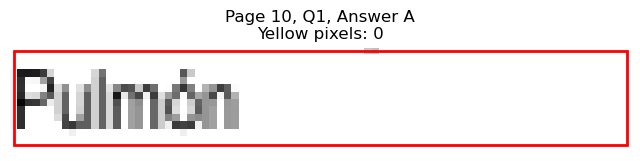

Page 10, Q1 - B: Detected box: x0=68.3, y0=102.0, x1=97.3, y1=114.7
Page 10, Q1, B: Yellow pixels: 0
Page 10, Q1, B: Total non-white pixels: 142
Page 10, Q1, B: Yellow percentage: 0.0%


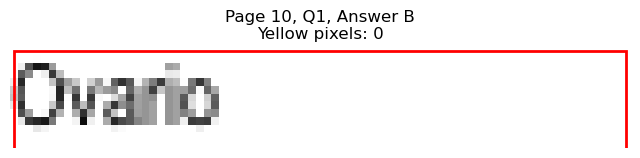

Page 10, Q1 - C: Detected box: x0=68.8, y0=114.6, x1=100.3, y1=127.3
Page 10, Q1, C: Yellow pixels: 0
Page 10, Q1, C: Total non-white pixels: 164
Page 10, Q1, C: Yellow percentage: 0.0%


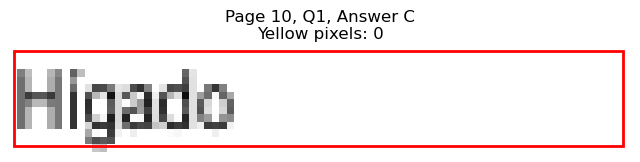

Page 10, Q1 - D: Detected box: x0=327.5, y0=89.4, x1=353.6, y1=102.1
Page 10, Q1, D: Yellow pixels: 77
Page 10, Q1, D: Total non-white pixels: 216
Page 10, Q1, D: Yellow percentage: 35.6%


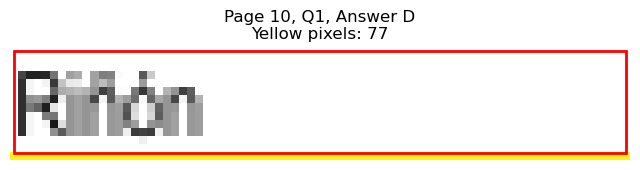

Page 10, Q1 - E: Detected box: x0=327.0, y0=102.0, x1=354.7, y1=114.7
Page 10, Q1, E: Yellow pixels: 904
Page 10, Q1, E: Total non-white pixels: 1014
Page 10, Q1, E: Yellow percentage: 89.2%


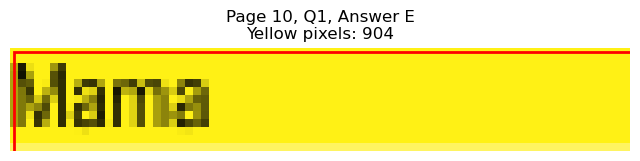


Page 10, Q1 - Selected Answer: E (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=184.1, y1=203.0
Page 10, Q2, A: Yellow pixels: 0
Page 10, Q2, A: Total non-white pixels: 591
Page 10, Q2, A: Yellow percentage: 0.0%


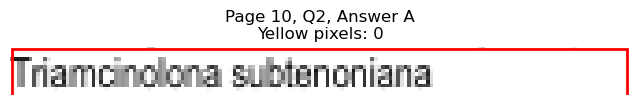

Page 10, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=157.6, y1=215.6
Page 10, Q2, B: Yellow pixels: 0
Page 10, Q2, B: Total non-white pixels: 429
Page 10, Q2, B: Yellow percentage: 0.0%


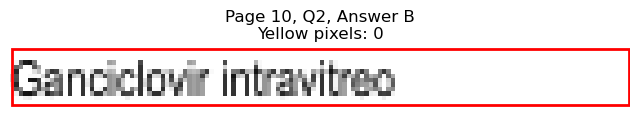

Page 10, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=177.6, y1=228.3
Page 10, Q2, C: Yellow pixels: 0
Page 10, Q2, C: Total non-white pixels: 568
Page 10, Q2, C: Yellow percentage: 0.0%


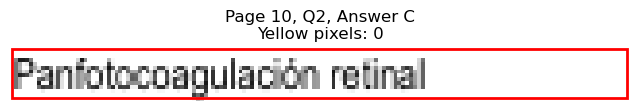

Page 10, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=450.9, y1=203.0
Page 10, Q2, D: Yellow pixels: 1798
Page 10, Q2, D: Total non-white pixels: 2262
Page 10, Q2, D: Yellow percentage: 79.5%


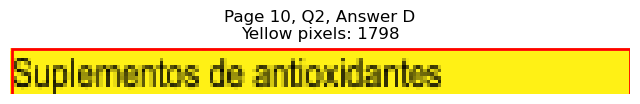

Page 10, Q2 - E: Detected box: x0=327.0, y0=202.9, x1=412.9, y1=215.6
Page 10, Q2, E: Yellow pixels: 135
Page 10, Q2, E: Total non-white pixels: 591
Page 10, Q2, E: Yellow percentage: 22.8%


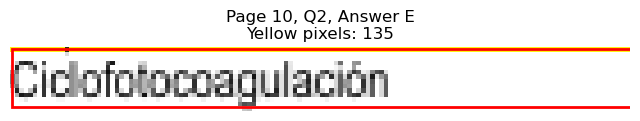


Page 10, Q2 - Selected Answer: D (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=68.3, y0=253.5, x1=129.1, y1=266.1
Page 10, Q3, A: Yellow pixels: 0
Page 10, Q3, A: Total non-white pixels: 288
Page 10, Q3, A: Yellow percentage: 0.0%


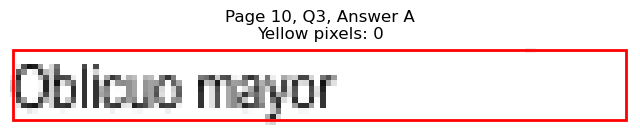

Page 10, Q3 - B: Detected box: x0=68.3, y0=266.1, x1=91.5, y1=278.7
Page 10, Q3, B: Yellow pixels: 0
Page 10, Q3, B: Total non-white pixels: 126
Page 10, Q3, B: Yellow percentage: 0.0%


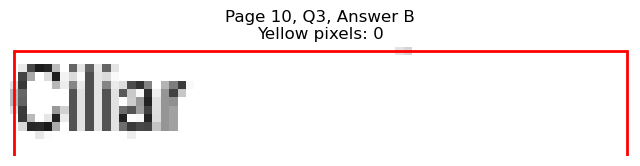

Page 10, Q3 - C: Detected box: x0=68.8, y0=278.8, x1=95.9, y1=291.5
Page 10, Q3, C: Yellow pixels: 0
Page 10, Q3, C: Total non-white pixels: 143
Page 10, Q3, C: Yellow percentage: 0.0%


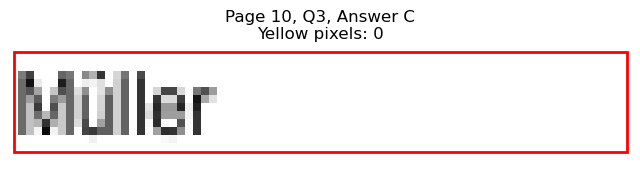

Page 10, Q3 - D: Detected box: x0=327.5, y0=253.5, x1=366.8, y1=266.1
Page 10, Q3, D: Yellow pixels: 1022
Page 10, Q3, D: Total non-white pixels: 1260
Page 10, Q3, D: Yellow percentage: 81.1%


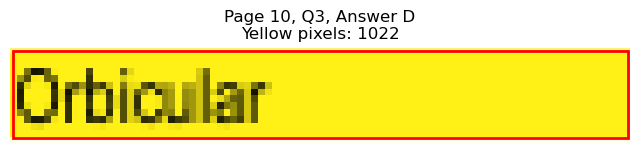

Page 10, Q3 - E: Detected box: x0=327.0, y0=266.1, x1=415.4, y1=278.7
Page 10, Q3, E: Yellow pixels: 0
Page 10, Q3, E: Total non-white pixels: 600
Page 10, Q3, E: Yellow percentage: 0.0%


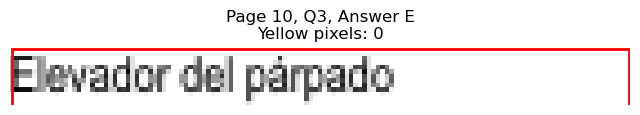


Page 10, Q3 - Selected Answer: D (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=68.3, y0=316.6, x1=124.5, y1=329.3
Page 10, Q4, A: Yellow pixels: 0
Page 10, Q4, A: Total non-white pixels: 282
Page 10, Q4, A: Yellow percentage: 0.0%


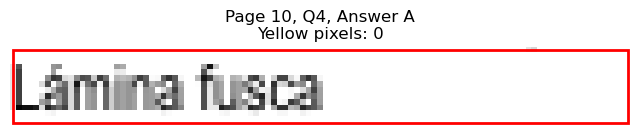

Page 10, Q4 - B: Detected box: x0=68.3, y0=329.2, x1=221.8, y1=341.9
Page 10, Q4, B: Yellow pixels: 0
Page 10, Q4, B: Total non-white pixels: 771
Page 10, Q4, B: Yellow percentage: 0.0%


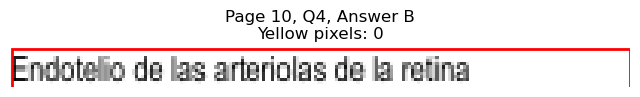

Page 10, Q4 - C: Detected box: x0=68.8, y0=341.9, x1=153.0, y1=354.6
Page 10, Q4, C: Yellow pixels: 1410
Page 10, Q4, C: Total non-white pixels: 1904
Page 10, Q4, C: Yellow percentage: 74.1%


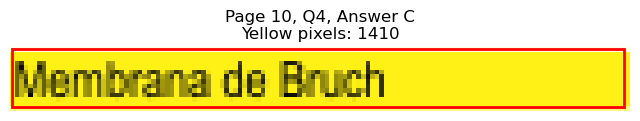

Page 10, Q4 - D: Detected box: x0=327.5, y0=316.6, x1=475.1, y1=329.3
Page 10, Q4, D: Yellow pixels: 0
Page 10, Q4, D: Total non-white pixels: 711
Page 10, Q4, D: Yellow percentage: 0.0%


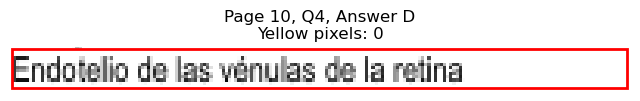

Page 10, Q4 - E: Detected box: x0=327.0, y0=329.2, x1=441.4, y1=341.9
Page 10, Q4, E: Yellow pixels: 0
Page 10, Q4, E: Total non-white pixels: 590
Page 10, Q4, E: Yellow percentage: 0.0%


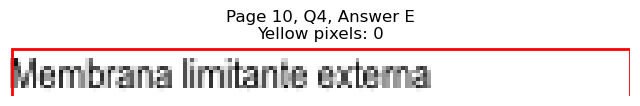


Page 10, Q4 - Selected Answer: C (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=68.3, y0=392.3, x1=139.5, y1=405.0
Page 10, Q5, A: Yellow pixels: 0
Page 10, Q5, A: Total non-white pixels: 505
Page 10, Q5, A: Yellow percentage: 0.0%


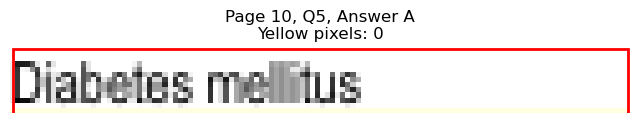

Page 10, Q5 - B: Detected box: x0=68.3, y0=404.9, x1=145.0, y1=417.6
Page 10, Q5, B: Yellow pixels: 1349
Page 10, Q5, B: Total non-white pixels: 1778
Page 10, Q5, B: Yellow percentage: 75.9%


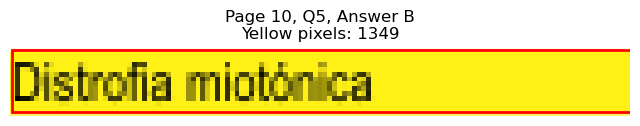

Page 10, Q5 - C: Detected box: x0=68.8, y0=417.6, x1=143.5, y1=430.3
Page 10, Q5, C: Yellow pixels: 126
Page 10, Q5, C: Total non-white pixels: 523
Page 10, Q5, C: Yellow percentage: 24.1%


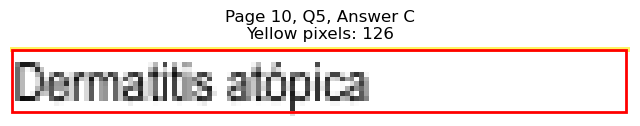

Page 10, Q5 - D: Detected box: x0=327.5, y0=392.3, x1=403.3, y1=405.0
Page 10, Q5, D: Yellow pixels: 0
Page 10, Q5, D: Total non-white pixels: 391
Page 10, Q5, D: Yellow percentage: 0.0%


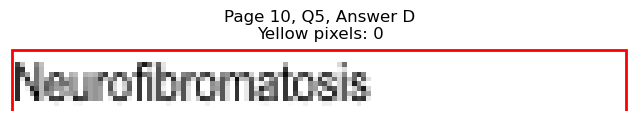

Page 10, Q5 - E: Detected box: x0=327.0, y0=404.9, x1=389.2, y1=417.6
Page 10, Q5, E: Yellow pixels: 0
Page 10, Q5, E: Total non-white pixels: 323
Page 10, Q5, E: Yellow percentage: 0.0%


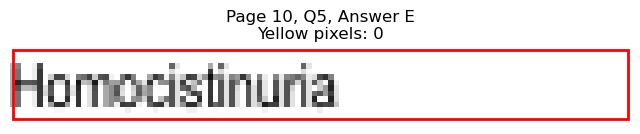


Page 10, Q5 - Selected Answer: B (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=68.3, y0=468.1, x1=142.0, y1=480.7
Page 10, Q6, A: Yellow pixels: 0
Page 10, Q6, A: Total non-white pixels: 387
Page 10, Q6, A: Yellow percentage: 0.0%


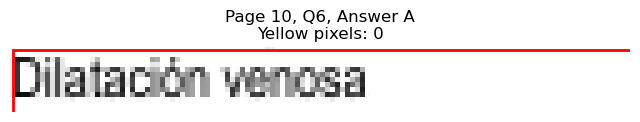

Page 10, Q6 - B: Detected box: x0=68.3, y0=480.8, x1=159.0, y1=493.4
Page 10, Q6, B: Yellow pixels: 0
Page 10, Q6, B: Total non-white pixels: 429
Page 10, Q6, B: Yellow percentage: 0.0%


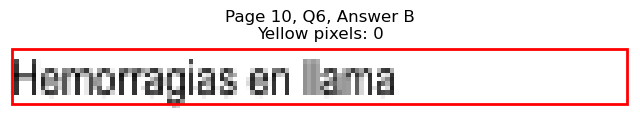

Page 10, Q6 - C: Detected box: x0=68.8, y0=493.4, x1=219.3, y1=506.0
Page 10, Q6, C: Yellow pixels: 0
Page 10, Q6, C: Total non-white pixels: 739
Page 10, Q6, C: Yellow percentage: 0.0%


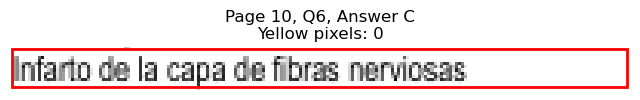

Page 10, Q6 - D: Detected box: x0=327.5, y0=468.1, x1=393.2, y1=480.7
Page 10, Q6, D: Yellow pixels: 0
Page 10, Q6, D: Total non-white pixels: 317
Page 10, Q6, D: Yellow percentage: 0.0%


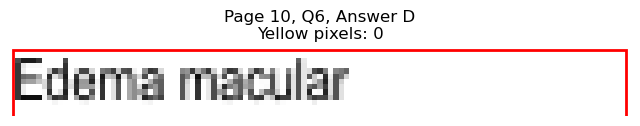

Page 10, Q6 - E: Detected box: x0=327.0, y0=480.8, x1=408.8, y1=493.4
Page 10, Q6, E: Yellow pixels: 1285
Page 10, Q6, E: Total non-white pixels: 1848
Page 10, Q6, E: Yellow percentage: 69.5%


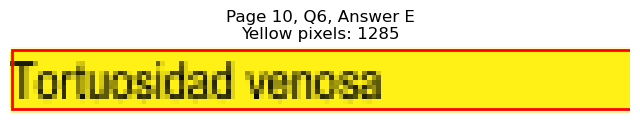


Page 10, Q6 - Selected Answer: E (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=68.3, y0=543.8, x1=131.5, y1=556.4
Page 10, Q7, A: Yellow pixels: 1217
Page 10, Q7, A: Total non-white pixels: 1596
Page 10, Q7, A: Yellow percentage: 76.3%


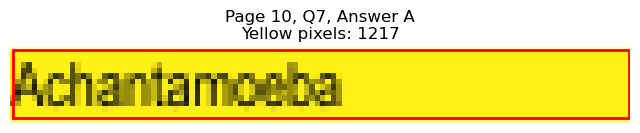

Page 10, Q7 - B: Detected box: x0=68.3, y0=556.5, x1=124.5, y1=569.2
Page 10, Q7, B: Yellow pixels: 107
Page 10, Q7, B: Total non-white pixels: 420
Page 10, Q7, B: Yellow percentage: 25.5%


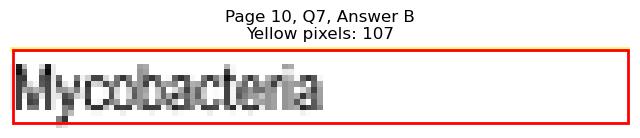

Page 10, Q7 - C: Detected box: x0=68.8, y0=569.1, x1=108.9, y1=581.8
Page 10, Q7, C: Yellow pixels: 0
Page 10, Q7, C: Total non-white pixels: 200
Page 10, Q7, C: Yellow percentage: 0.0%


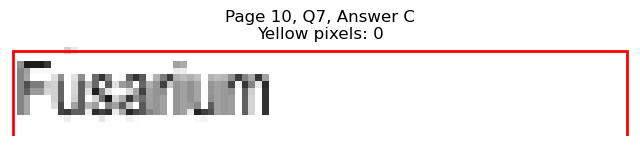

Page 10, Q7 - D: Detected box: x0=327.5, y0=543.8, x1=412.3, y1=556.4
Page 10, Q7, D: Yellow pixels: 0
Page 10, Q7, D: Total non-white pixels: 423
Page 10, Q7, D: Yellow percentage: 0.0%


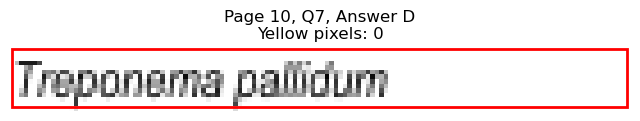

Page 10, Q7 - E: Detected box: x0=327.0, y0=556.5, x1=374.7, y1=569.2
Page 10, Q7, E: Yellow pixels: 0
Page 10, Q7, E: Total non-white pixels: 240
Page 10, Q7, E: Yellow percentage: 0.0%


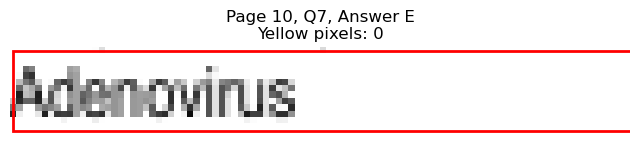


Page 10, Q7 - Selected Answer: A (based on yellow pixel count)




Page 10, Q8 - A: Detected box: x0=68.3, y0=619.6, x1=93.9, y1=632.3
Page 10, Q8, A: Yellow pixels: 0
Page 10, Q8, A: Total non-white pixels: 132
Page 10, Q8, A: Yellow percentage: 0.0%


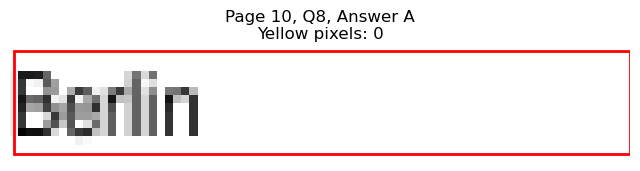

Page 10, Q8 - B: Detected box: x0=68.3, y0=632.2, x1=88.8, y1=644.9
Page 10, Q8, B: Yellow pixels: 0
Page 10, Q8, B: Total non-white pixels: 107
Page 10, Q8, B: Yellow percentage: 0.0%


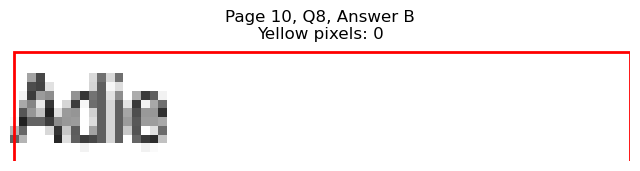

Page 10, Q8 - C: Detected box: x0=68.8, y0=644.9, x1=107.9, y1=657.5
Page 10, Q8, C: Yellow pixels: 0
Page 10, Q8, C: Total non-white pixels: 194
Page 10, Q8, C: Yellow percentage: 0.0%


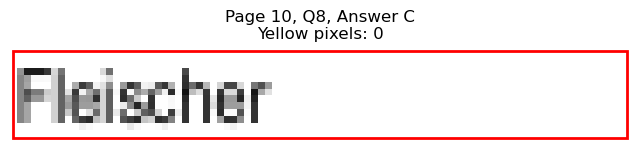

Page 10, Q8 - D: Detected box: x0=327.5, y0=619.6, x1=364.1, y1=632.3
Page 10, Q8, D: Yellow pixels: 88
Page 10, Q8, D: Total non-white pixels: 283
Page 10, Q8, D: Yellow percentage: 31.1%


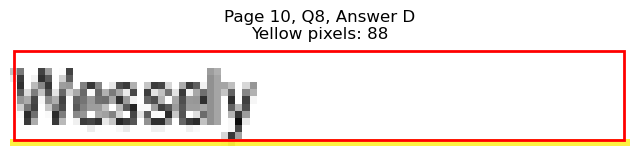

Page 10, Q8 - E: Detected box: x0=327.0, y0=632.2, x1=361.1, y1=644.9
Page 10, Q8, E: Yellow pixels: 973
Page 10, Q8, E: Total non-white pixels: 1105
Page 10, Q8, E: Yellow percentage: 88.1%


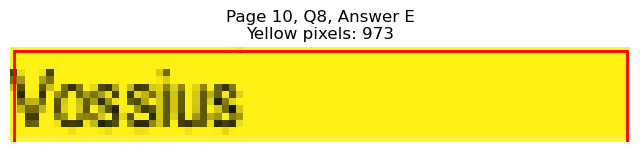


Page 10, Q8 - Selected Answer: E (based on yellow pixel count)




Page 10, Q9 - A: Detected box: x0=68.3, y0=695.4, x1=122.4, y1=708.0
Page 10, Q9, A: Yellow pixels: 0
Page 10, Q9, A: Total non-white pixels: 308
Page 10, Q9, A: Yellow percentage: 0.0%


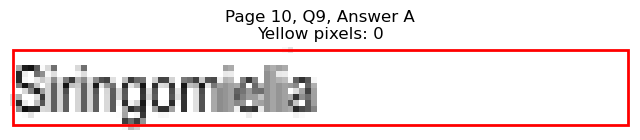

Page 10, Q9 - B: Detected box: x0=68.3, y0=708.0, x1=215.2, y1=720.6
Page 10, Q9, B: Yellow pixels: 0
Page 10, Q9, B: Total non-white pixels: 743
Page 10, Q9, B: Yellow percentage: 0.0%


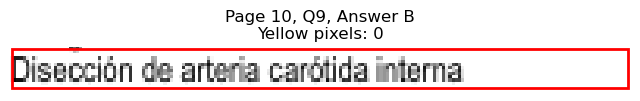

Page 10, Q9 - C: Detected box: x0=68.8, y0=720.6, x1=152.5, y1=733.2
Page 10, Q9, C: Yellow pixels: 0
Page 10, Q9, C: Total non-white pixels: 404
Page 10, Q9, C: Yellow percentage: 0.0%


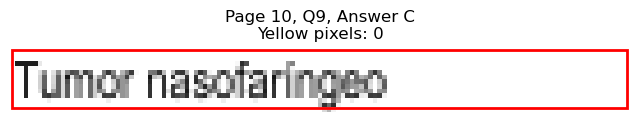

Page 10, Q9 - D: Detected box: x0=327.5, y0=695.4, x1=408.8, y1=708.0
Page 10, Q9, D: Yellow pixels: 1415
Page 10, Q9, D: Total non-white pixels: 1716
Page 10, Q9, D: Yellow percentage: 82.5%


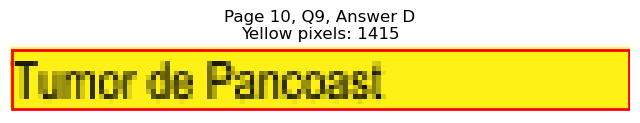

Page 10, Q9 - E: Detected box: x0=327.0, y0=708.0, x1=433.9, y1=720.6
Page 10, Q9, E: Yellow pixels: 157
Page 10, Q9, E: Total non-white pixels: 655
Page 10, Q9, E: Yellow percentage: 24.0%


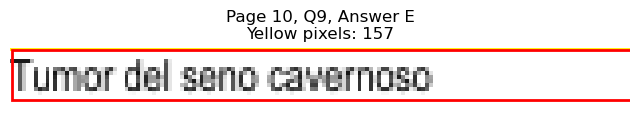


Page 10, Q9 - Selected Answer: D (based on yellow pixel count)





Page 11: Found 8 questions
Page 11, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=176.2, y1=114.7
Page 11, Q1, A: Yellow pixels: 0
Page 11, Q1, A: Total non-white pixels: 531
Page 11, Q1, A: Yellow percentage: 0.0%


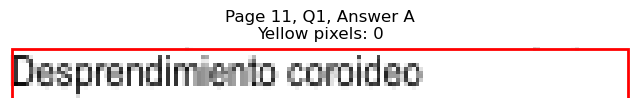

Page 11, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=143.1, y1=127.3
Page 11, Q1, B: Yellow pixels: 126
Page 11, Q1, B: Total non-white pixels: 481
Page 11, Q1, B: Yellow percentage: 26.2%


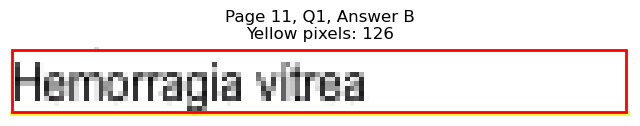

Page 11, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=149.1, y1=139.9
Page 11, Q1, C: Yellow pixels: 1398
Page 11, Q1, C: Total non-white pixels: 1716
Page 11, Q1, C: Yellow percentage: 81.5%


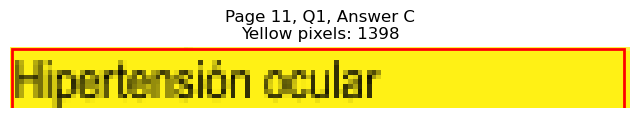

Page 11, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=374.7, y1=114.7
Page 11, Q1, D: Yellow pixels: 0
Page 11, Q1, D: Total non-white pixels: 240
Page 11, Q1, D: Yellow percentage: 0.0%


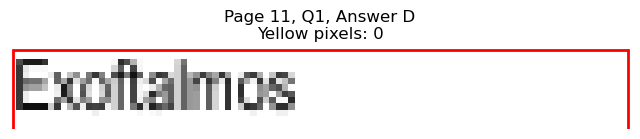

Page 11, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=439.9, y1=127.3
Page 11, Q1, E: Yellow pixels: 0
Page 11, Q1, E: Total non-white pixels: 567
Page 11, Q1, E: Yellow percentage: 0.0%


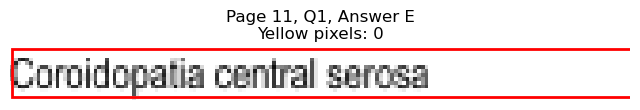


Page 11, Q1 - Selected Answer: C (based on yellow pixel count)




Page 11, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=168.6, y1=203.0
Page 11, Q2, A: Yellow pixels: 0
Page 11, Q2, A: Total non-white pixels: 491
Page 11, Q2, A: Yellow percentage: 0.0%


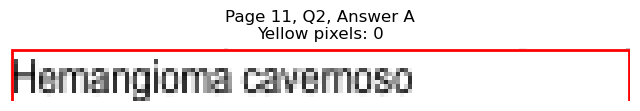

Page 11, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=132.0, y1=215.6
Page 11, Q2, B: Yellow pixels: 0
Page 11, Q2, B: Total non-white pixels: 348
Page 11, Q2, B: Yellow percentage: 0.0%


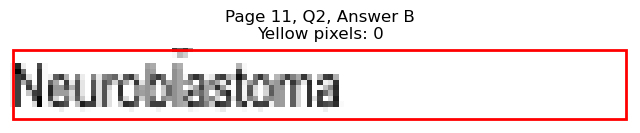

Page 11, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=103.3, y1=228.3
Page 11, Q2, C: Yellow pixels: 0
Page 11, Q2, C: Total non-white pixels: 169
Page 11, Q2, C: Yellow percentage: 0.0%


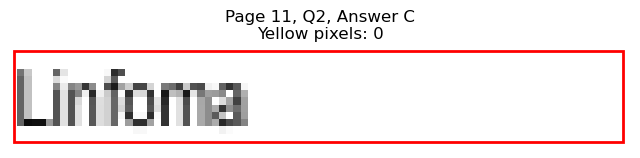

Page 11, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=388.7, y1=203.0
Page 11, Q2, D: Yellow pixels: 1223
Page 11, Q2, D: Total non-white pixels: 1456
Page 11, Q2, D: Yellow percentage: 84.0%


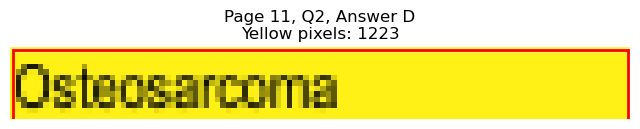

Page 11, Q2 - E: Detected box: x0=327.0, y0=202.9, x1=405.8, y1=215.6
Page 11, Q2, E: Yellow pixels: 129
Page 11, Q2, E: Total non-white pixels: 533
Page 11, Q2, E: Yellow percentage: 24.2%


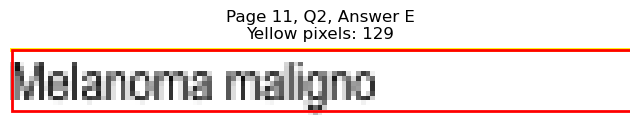


Page 11, Q2 - Selected Answer: D (based on yellow pixel count)




Page 11, Q3 - A: Detected box: x0=68.3, y0=266.1, x1=136.5, y1=278.7
Page 11, Q3, A: Yellow pixels: 0
Page 11, Q3, A: Total non-white pixels: 360
Page 11, Q3, A: Yellow percentage: 0.0%


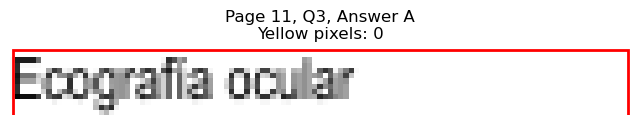

Page 11, Q3 - B: Detected box: x0=68.3, y0=278.8, x1=162.6, y1=291.5
Page 11, Q3, B: Yellow pixels: 1505
Page 11, Q3, B: Total non-white pixels: 2030
Page 11, Q3, B: Yellow percentage: 74.1%


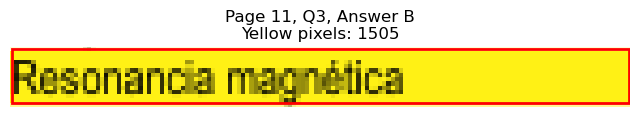

Page 11, Q3 - C: Detected box: x0=68.8, y0=291.4, x1=179.1, y1=304.1
Page 11, Q3, C: Yellow pixels: 161
Page 11, Q3, C: Total non-white pixels: 719
Page 11, Q3, C: Yellow percentage: 22.4%


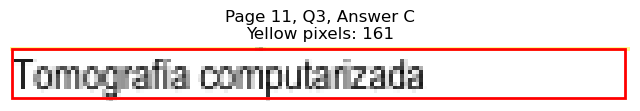

Page 11, Q3 - D: Detected box: x0=327.5, y0=266.1, x1=376.7, y1=278.7
Page 11, Q3, D: Yellow pixels: 0
Page 11, Q3, D: Total non-white pixels: 276
Page 11, Q3, D: Yellow percentage: 0.0%


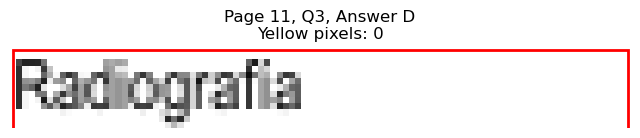

Page 11, Q3 - E: Detected box: x0=327.0, y0=278.8, x1=378.8, y1=291.5
Page 11, Q3, E: Yellow pixels: 0
Page 11, Q3, E: Total non-white pixels: 291
Page 11, Q3, E: Yellow percentage: 0.0%


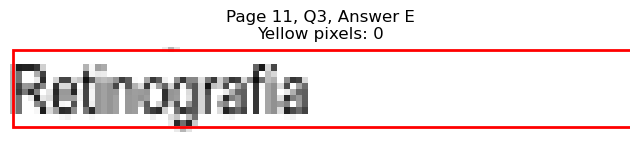


Page 11, Q3 - Selected Answer: B (based on yellow pixel count)




Page 11, Q4 - A: Detected box: x0=68.3, y0=329.2, x1=162.1, y1=341.9
Page 11, Q4, A: Yellow pixels: 0
Page 11, Q4, A: Total non-white pixels: 478
Page 11, Q4, A: Yellow percentage: 0.0%


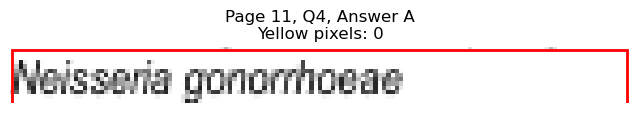

Page 11, Q4 - B: Detected box: x0=68.3, y0=341.9, x1=162.6, y1=354.6
Page 11, Q4, B: Yellow pixels: 0
Page 11, Q4, B: Total non-white pixels: 495
Page 11, Q4, B: Yellow percentage: 0.0%


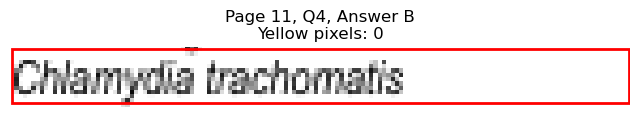

Page 11, Q4 - C: Detected box: x0=68.8, y0=354.5, x1=167.5, y1=367.2
Page 11, Q4, C: Yellow pixels: 0
Page 11, Q4, C: Total non-white pixels: 502
Page 11, Q4, C: Yellow percentage: 0.0%


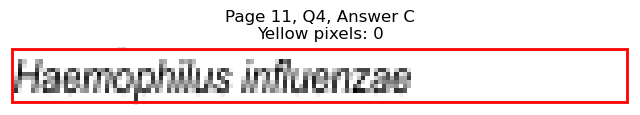

Page 11, Q4 - D: Detected box: x0=327.5, y0=329.2, x1=405.8, y1=341.9
Page 11, Q4, D: Yellow pixels: 1353
Page 11, Q4, D: Total non-white pixels: 1677
Page 11, Q4, D: Yellow percentage: 80.7%


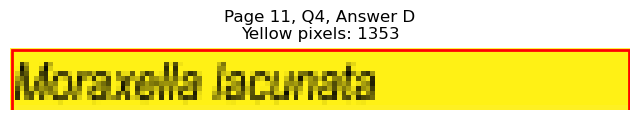

Page 11, Q4 - E: Detected box: x0=327.0, y0=341.9, x1=417.3, y1=354.6
Page 11, Q4, E: Yellow pixels: 141
Page 11, Q4, E: Total non-white pixels: 621
Page 11, Q4, E: Yellow percentage: 22.7%


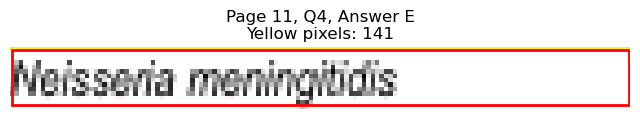


Page 11, Q4 - Selected Answer: D (based on yellow pixel count)




Page 11, Q5 - A: Detected box: x0=68.3, y0=430.2, x1=227.8, y1=442.9
Page 11, Q5, A: Yellow pixels: 0
Page 11, Q5, A: Total non-white pixels: 801
Page 11, Q5, A: Yellow percentage: 0.0%


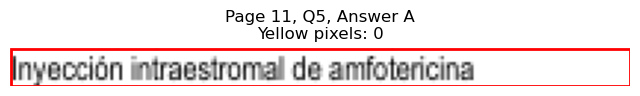

Page 11, Q5 - B: Detected box: x0=68.3, y0=442.8, x1=208.7, y1=455.5
Page 11, Q5, B: Yellow pixels: 191
Page 11, Q5, B: Total non-white pixels: 896
Page 11, Q5, B: Yellow percentage: 21.3%


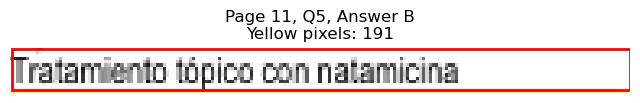

Page 11, Q5 - C: Detected box: x0=68.8, y0=455.5, x1=223.4, y1=468.1
Page 11, Q5, C: Yellow pixels: 2082
Page 11, Q5, C: Total non-white pixels: 2884
Page 11, Q5, C: Yellow percentage: 72.2%


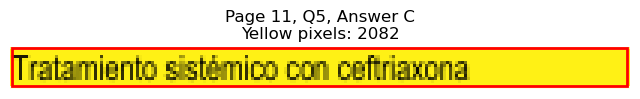

Page 11, Q5 - D: Detected box: x0=327.5, y0=430.2, x1=475.5, y1=442.9
Page 11, Q5, D: Yellow pixels: 0
Page 11, Q5, D: Total non-white pixels: 760
Page 11, Q5, D: Yellow percentage: 0.0%


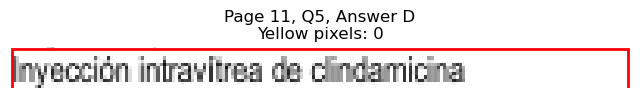

Page 11, Q5 - E: Detected box: x0=327.0, y0=442.8, x1=456.4, y1=455.5
Page 11, Q5, E: Yellow pixels: 0
Page 11, Q5, E: Total non-white pixels: 652
Page 11, Q5, E: Yellow percentage: 0.0%


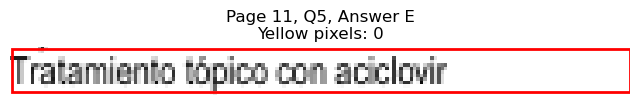


Page 11, Q5 - Selected Answer: C (based on yellow pixel count)




Page 11, Q6 - A: Detected box: x0=68.3, y0=506.0, x1=141.0, y1=518.6
Page 11, Q6, A: Yellow pixels: 0
Page 11, Q6, A: Total non-white pixels: 370
Page 11, Q6, A: Yellow percentage: 0.0%


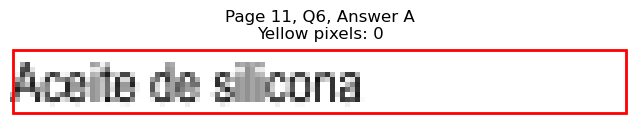

Page 11, Q6 - B: Detected box: x0=68.3, y0=518.6, x1=162.6, y1=531.2
Page 11, Q6, B: Yellow pixels: 145
Page 11, Q6, B: Total non-white pixels: 610
Page 11, Q6, B: Yellow percentage: 23.8%


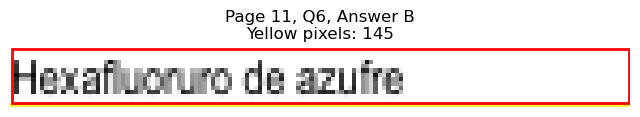

Page 11, Q6 - C: Detected box: x0=68.8, y0=531.2, x1=169.1, y1=543.8
Page 11, Q6, C: Yellow pixels: 1580
Page 11, Q6, C: Total non-white pixels: 1976
Page 11, Q6, C: Yellow percentage: 80.0%


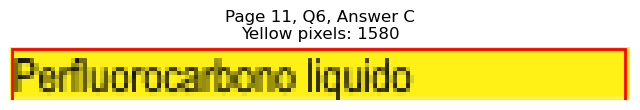

Page 11, Q6 - D: Detected box: x0=327.5, y0=506.0, x1=389.2, y1=518.6
Page 11, Q6, D: Yellow pixels: 0
Page 11, Q6, D: Total non-white pixels: 311
Page 11, Q6, D: Yellow percentage: 0.0%


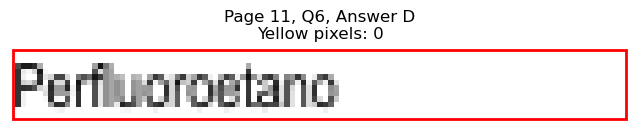

Page 11, Q6 - E: Detected box: x0=327.0, y0=518.6, x1=399.3, y1=531.2
Page 11, Q6, E: Yellow pixels: 0
Page 11, Q6, E: Total non-white pixels: 356
Page 11, Q6, E: Yellow percentage: 0.0%


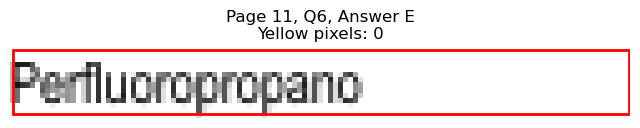


Page 11, Q6 - Selected Answer: C (based on yellow pixel count)




Page 11, Q7 - A: Detected box: x0=68.3, y0=606.9, x1=206.7, y1=619.6
Page 11, Q7, A: Yellow pixels: 0
Page 11, Q7, A: Total non-white pixels: 700
Page 11, Q7, A: Yellow percentage: 0.0%


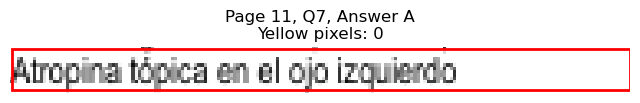

Page 11, Q7 - B: Detected box: x0=68.3, y0=619.6, x1=269.4, y1=632.3
Page 11, Q7, B: Yellow pixels: 6
Page 11, Q7, B: Total non-white pixels: 997
Page 11, Q7, B: Yellow percentage: 0.6%


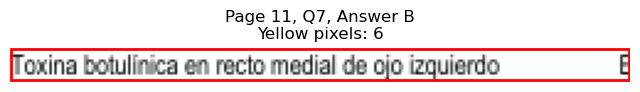

Page 11, Q7 - C: Detected box: x0=68.8, y0=632.2, x1=206.2, y1=644.9
Page 11, Q7, C: Yellow pixels: 0
Page 11, Q7, C: Total non-white pixels: 686
Page 11, Q7, C: Yellow percentage: 0.0%


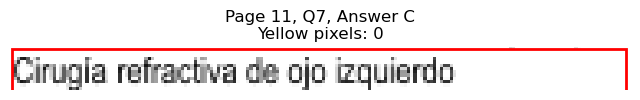

Page 11, Q7 - D: Detected box: x0=327.5, y0=606.9, x1=480.6, y1=619.6
Page 11, Q7, D: Yellow pixels: 2083
Page 11, Q7, D: Total non-white pixels: 2856
Page 11, Q7, D: Yellow percentage: 72.9%


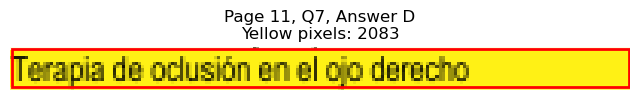

Page 11, Q7 - E: Detected box: x0=327.0, y0=619.6, x1=447.4, y1=632.3
Page 11, Q7, E: Yellow pixels: 170
Page 11, Q7, E: Total non-white pixels: 795
Page 11, Q7, E: Yellow percentage: 21.4%


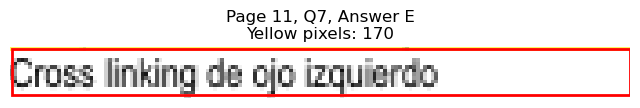


Page 11, Q7 - Selected Answer: D (based on yellow pixel count)




Page 11, Q8 - A: Detected box: x0=68.3, y0=670.1, x1=188.2, y1=682.7
Page 11, Q8, A: Yellow pixels: 0
Page 11, Q8, A: Total non-white pixels: 608
Page 11, Q8, A: Yellow percentage: 0.0%


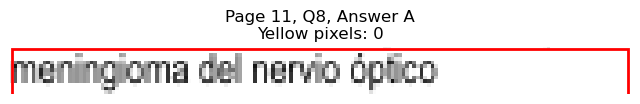

Page 11, Q8 - B: Detected box: x0=68.3, y0=682.7, x1=117.5, y1=695.3
Page 11, Q8, B: Yellow pixels: 0
Page 11, Q8, B: Total non-white pixels: 260
Page 11, Q8, B: Yellow percentage: 0.0%


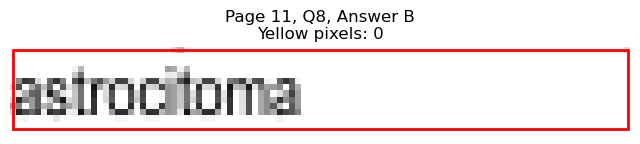

Page 11, Q8 - C: Detected box: x0=68.8, y0=695.4, x1=166.1, y1=708.0
Page 11, Q8, C: Yellow pixels: 0
Page 11, Q8, C: Total non-white pixels: 485
Page 11, Q8, C: Yellow percentage: 0.0%


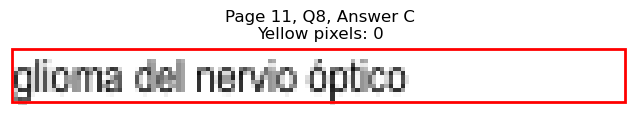

Page 11, Q8 - D: Detected box: x0=327.5, y0=670.1, x1=427.5, y1=682.7
Page 11, Q8, D: Yellow pixels: 1547
Page 11, Q8, D: Total non-white pixels: 1963
Page 11, Q8, D: Yellow percentage: 78.8%


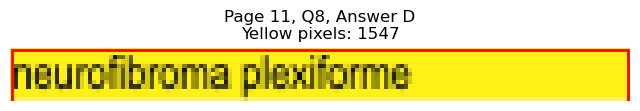

Page 11, Q8 - E: Detected box: x0=327.0, y0=682.7, x1=400.8, y1=695.3
Page 11, Q8, E: Yellow pixels: 124
Page 11, Q8, E: Total non-white pixels: 559
Page 11, Q8, E: Yellow percentage: 22.2%


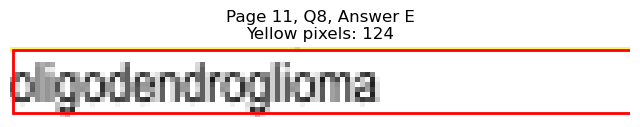


Page 11, Q8 - Selected Answer: D (based on yellow pixel count)





Page 12: Found 4 questions
Page 12, Q1 - A: Detected box: x0=68.3, y0=102.0, x1=100.3, y1=114.7
Page 12, Q1, A: Yellow pixels: 0
Page 12, Q1, A: Total non-white pixels: 165
Page 12, Q1, A: Yellow percentage: 0.0%


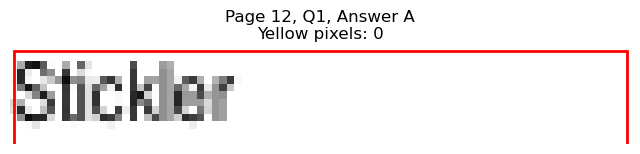

Page 12, Q1 - B: Detected box: x0=68.3, y0=114.6, x1=95.4, y1=127.3
Page 12, Q1, B: Yellow pixels: 78
Page 12, Q1, B: Total non-white pixels: 239
Page 12, Q1, B: Yellow percentage: 32.6%


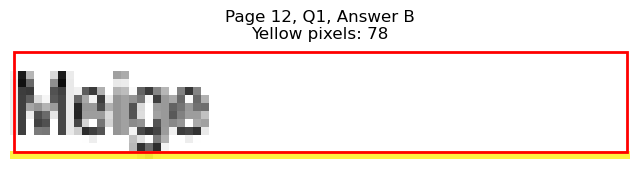

Page 12, Q1 - C: Detected box: x0=68.8, y0=127.2, x1=97.8, y1=139.9
Page 12, Q1, C: Yellow pixels: 927
Page 12, Q1, C: Total non-white pixels: 1040
Page 12, Q1, C: Yellow percentage: 89.1%


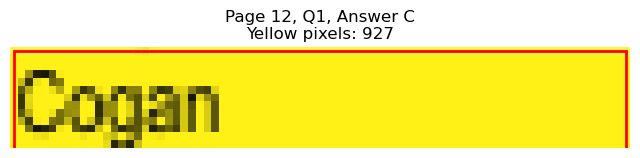

Page 12, Q1 - D: Detected box: x0=327.5, y0=102.0, x1=351.7, y1=114.7
Page 12, Q1, D: Yellow pixels: 0
Page 12, Q1, D: Total non-white pixels: 99
Page 12, Q1, D: Yellow percentage: 0.0%


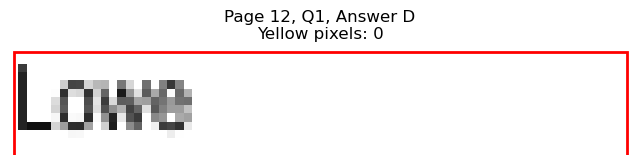

Page 12, Q1 - E: Detected box: x0=327.0, y0=114.6, x1=356.1, y1=127.3
Page 12, Q1, E: Yellow pixels: 0
Page 12, Q1, E: Total non-white pixels: 150
Page 12, Q1, E: Yellow percentage: 0.0%


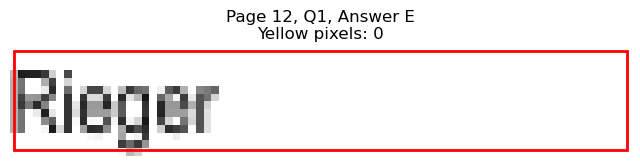


Page 12, Q1 - Selected Answer: C (based on yellow pixel count)




Page 12, Q2 - A: Detected box: x0=68.3, y0=190.3, x1=197.8, y1=203.0
Page 12, Q2, A: Yellow pixels: 0
Page 12, Q2, A: Total non-white pixels: 641
Page 12, Q2, A: Yellow percentage: 0.0%


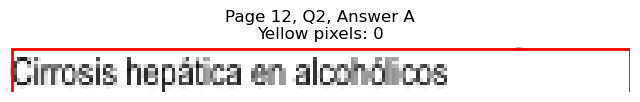

Page 12, Q2 - B: Detected box: x0=68.3, y0=202.9, x1=208.7, y1=215.6
Page 12, Q2, B: Yellow pixels: 0
Page 12, Q2, B: Total non-white pixels: 668
Page 12, Q2, B: Yellow percentage: 0.0%


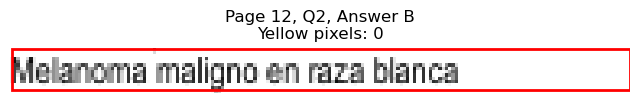

Page 12, Q2 - C: Detected box: x0=68.8, y0=215.7, x1=208.2, y1=228.3
Page 12, Q2, C: Yellow pixels: 0
Page 12, Q2, C: Total non-white pixels: 700
Page 12, Q2, C: Yellow percentage: 0.0%


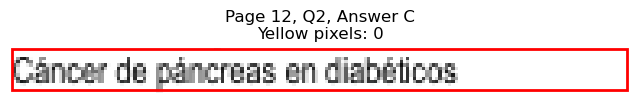

Page 12, Q2 - D: Detected box: x0=327.5, y0=190.3, x1=454.0, y1=203.0
Page 12, Q2, D: Yellow pixels: 0
Page 12, Q2, D: Total non-white pixels: 806
Page 12, Q2, D: Yellow percentage: 0.0%


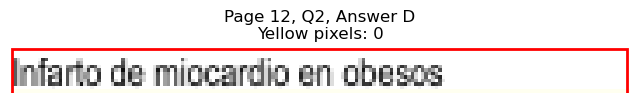

Page 12, Q2 - E: Detected box: x0=327.0, y0=202.9, x1=460.9, y1=215.6
Page 12, Q2, E: Yellow pixels: 1886
Page 12, Q2, E: Total non-white pixels: 2576
Page 12, Q2, E: Yellow percentage: 73.2%


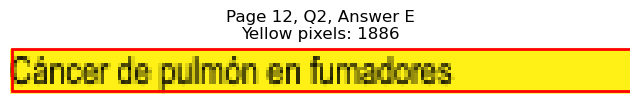


Page 12, Q2 - Selected Answer: E (based on yellow pixel count)




Page 12, Q3 - A: Detected box: x0=68.3, y0=304.0, x1=238.2, y1=316.7
Page 12, Q3, A: Yellow pixels: 0
Page 12, Q3, A: Total non-white pixels: 863
Page 12, Q3, A: Yellow percentage: 0.0%


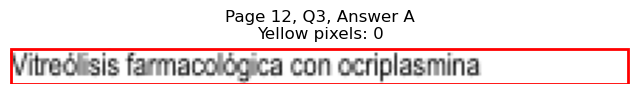

Page 12, Q3 - B: Detected box: x0=68.3, y0=316.6, x1=176.7, y1=329.3
Page 12, Q3, B: Yellow pixels: 0
Page 12, Q3, B: Total non-white pixels: 537
Page 12, Q3, B: Yellow percentage: 0.0%


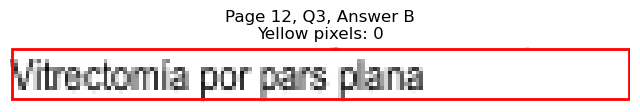

Page 12, Q3 - C: Detected box: x0=196.1, y0=329.2, x1=241.7, y1=341.9
Page 12, Q3, C: Yellow pixels: 0
Page 12, Q3, C: Total non-white pixels: 408
Page 12, Q3, C: Yellow percentage: 0.0%


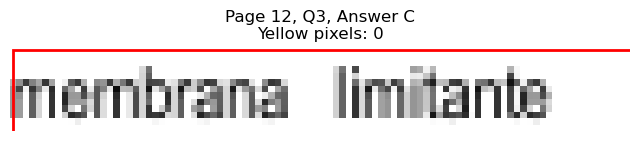

Page 12, Q3 - D: Detected box: x0=327.5, y0=304.0, x1=493.5, y1=316.7
Page 12, Q3, D: Yellow pixels: 2141
Page 12, Q3, D: Total non-white pixels: 2782
Page 12, Q3, D: Yellow percentage: 77.0%


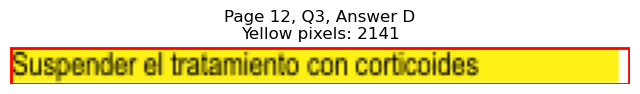

Page 12, Q3 - E: Detected box: x0=327.0, y0=316.6, x1=500.6, y1=329.3
Page 12, Q3, E: Yellow pixels: 213
Page 12, Q3, E: Total non-white pixels: 1082
Page 12, Q3, E: Yellow percentage: 19.7%


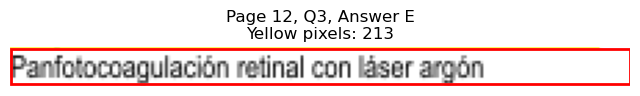


Page 12, Q3 - Selected Answer: D (based on yellow pixel count)




Page 12, Q4 - A: Detected box: x0=68.3, y0=430.2, x1=165.7, y1=442.9
Page 12, Q4, A: Yellow pixels: 0
Page 12, Q4, A: Total non-white pixels: 496
Page 12, Q4, A: Yellow percentage: 0.0%


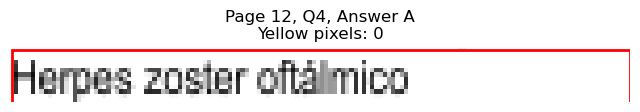

Page 12, Q4 - B: Detected box: x0=68.3, y0=442.8, x1=164.1, y1=455.5
Page 12, Q4, B: Yellow pixels: 0
Page 12, Q4, B: Total non-white pixels: 511
Page 12, Q4, B: Yellow percentage: 0.0%


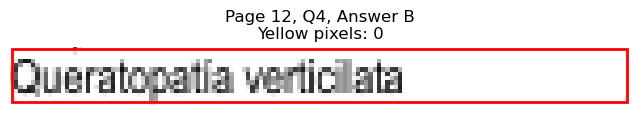

Page 12, Q4 - C: Detected box: x0=68.8, y0=455.5, x1=153.6, y1=468.1
Page 12, Q4, C: Yellow pixels: 0
Page 12, Q4, C: Total non-white pixels: 427
Page 12, Q4, C: Yellow percentage: 0.0%


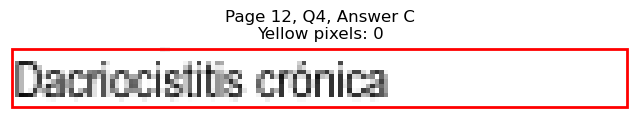

Page 12, Q4 - D: Detected box: x0=327.5, y0=430.2, x1=452.9, y1=442.9
Page 12, Q4, D: Yellow pixels: 0
Page 12, Q4, D: Total non-white pixels: 856
Page 12, Q4, D: Yellow percentage: 0.0%


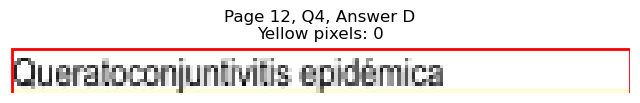

Page 12, Q4 - E: Detected box: x0=327.0, y0=442.8, x1=475.1, y1=455.5
Page 12, Q4, E: Yellow pixels: 2008
Page 12, Q4, E: Total non-white pixels: 2786
Page 12, Q4, E: Yellow percentage: 72.1%


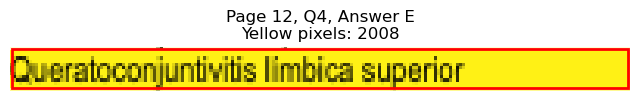


Page 12, Q4 - Selected Answer: E (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,¿Qué enfermedad cutánea produce madarosis?
1,La granulomatosis de ...... es una enfermedad ...
2,¿Cuál es el tumor intraocular primario maligno...
3,"En el electrorretinograma, la onda a es una de..."
4,"Varón de 28 años, con ojo rojo izquierdo. Exam..."
...,...
95,El......es el tumor de nervios periféricos pri...
96,¿Cuál de los siguientes es el síndrome que pre...
97,En el ensayo clínico AREDS 2 sobre suplementos...
98,"Varón de 25 años, con altos niveles de estrés,..."


In [8]:
answers_df

,option_A,option_B,option_C,option_D,option_E
0,Dermatomiositis,Sífilis adquirida,Psoriasis,Lupus eritematoso sistémico,Mixedema
1,Rieger,Koeppe,Fuchs,Harada,Wegener
2,Linfoma,Melanoma coroideo,Linfangioma,Retinoblastoma,Hemangioma capilar
3,células bipolares.,células de Müller.,células ganglionares.,epitelio pigmentario.,fotorreceptores.
4,Úlcera corneal geográfica,Desprendimiento coroideo hemorrágico,Hifema,Oclusión de vena central de la retina,Edema macular cistoide
...,...,...,...,...,...
95,meningioma del nervio óptico,astrocitoma,glioma del nervio óptico,neurofibroma plexiforme,oligodendroglioma
96,Stickler,Meige,Cogan,Lowe,Rieger
97,Cirrosis hepática en alcohólicos,Melanoma maligno en raza blanca,Cáncer de páncreas en diabéticos,Infarto de miocardio en obesos,Cáncer de pulmón en fumadores
98,Vitreólisis farmacológica con ocriplasmina,Vitrectomía por pars plana,Extracción quirúrgica de la membrana limitante,Suspender el tratamiento con corticoides,Panfotocoagulación retinal con láser argón


In [9]:
correct_answers_df

,correct_answer
0,C
1,E
2,B
3,E
4,A
...,...
95,D
96,C
97,E
98,D


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "option_E", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,option_E,correct_answer
0,¿Qué enfermedad cutánea produce madarosis?,Dermatomiositis,Sífilis adquirida,Psoriasis,Lupus eritematoso sistémico,Mixedema,C
1,La granulomatosis de ...... es una enfermedad ...,Rieger,Koeppe,Fuchs,Harada,Wegener,E
2,¿Cuál es el tumor intraocular primario maligno...,Linfoma,Melanoma coroideo,Linfangioma,Retinoblastoma,Hemangioma capilar,B
3,"En el electrorretinograma, la onda a es una de...",células bipolares.,células de Müller.,células ganglionares.,epitelio pigmentario.,fotorreceptores.,E
4,"Varón de 28 años, con ojo rojo izquierdo. Exam...",Úlcera corneal geográfica,Desprendimiento coroideo hemorrágico,Hifema,Oclusión de vena central de la retina,Edema macular cistoide,A
...,...,...,...,...,...,...,...
95,El......es el tumor de nervios periféricos pri...,meningioma del nervio óptico,astrocitoma,glioma del nervio óptico,neurofibroma plexiforme,oligodendroglioma,D
96,¿Cuál de los siguientes es el síndrome que pre...,Stickler,Meige,Cogan,Lowe,Rieger,C
97,En el ensayo clínico AREDS 2 sobre suplementos...,Cirrosis hepática en alcohólicos,Melanoma maligno en raza blanca,Cáncer de páncreas en diabéticos,Infarto de miocardio en obesos,Cáncer de pulmón en fumadores,E
98,"Varón de 25 años, con altos niveles de estrés,...",Vitreólisis farmacológica con ocriplasmina,Vitrectomía por pars plana,Extracción quirúrgica de la membrana limitante,Suspender el tratamiento con corticoides,Panfotocoagulación retinal con láser argón,D


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2022/Oftalmología.csv
